In [1]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 1: Environment Setup
# ================================================================

# Install required packages (run once in Google Colab)
!pip -q install -U timm einops torchmetrics fvcore transformers

# ================================================================
# Imports
# ================================================================

import os
import gc
import math
import time
import random
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as T

import timm

from einops import rearrange, repeat

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score,
)

from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score,
)

from fvcore.nn import FlopCountAnalysis, parameter_count_table

warnings.filterwarnings("ignore")

# ================================================================
# Reproducibility
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ================================================================
# Device
# ================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("PALT Environment Initialized")
print("=" * 60)
print(f"PyTorch Version      : {torch.__version__}")
print(f"Torchvision Version  : {torchvision.__version__}")
print(f"TIMM Version         : {timm.__version__}")
print(f"CUDA Available       : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU                 : {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory          : {torch.cuda.get_device_properties(0).total_memory/1024**3:.2f} GB")

print(f"Device              : {DEVICE}")
print("=" * 60)

# ================================================================
# Clean GPU Cache
# ================================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Environment Ready ✅")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 11.1 MB/s eta 0:00:00
PALT Environment Initialized
PyTorch Version      : 2.11.0+cu128
Torchvision Version  : 0.26.0+cu128
TIMM Version         : 1.0.29
CUDA Available       : True
GPU                 : Tesla T4
GPU Memory          : 14.56 GB
Device              : cuda
Environment Ready ✅


In [2]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 2: Global Configuration
# ================================================================

from dataclasses import dataclass

@dataclass
class Config:

    # ============================================================
    # Dataset
    # ============================================================
    DATASET_NAME = "EuroSAT-MS"

    NUM_CLASSES = 10
    NUM_CHANNELS = 13

    IMAGE_SIZE = 224
    PATCH_SIZE = 16

    TRAIN_SPLIT = 0.80
    VAL_SPLIT = 0.10
    TEST_SPLIT = 0.10

    NUM_WORKERS = 2
    PIN_MEMORY = True

    # ============================================================
    # STG
    # ============================================================
    EMBED_DIM = 768

    # Number of image patches
    NUM_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2

    # ============================================================
    # ALTM-B
    # ============================================================
    MEMORY_SIZE = 32          # K

    MEMORY_DIM = EMBED_DIM

    LIQUID_ALPHA = 0.10

    DELTA_T = 1.0

    # ============================================================
    # LSBL
    # ============================================================
    NUM_BASES = 8             # L

    # ============================================================
    # PC-DSA
    # ============================================================
    NUM_HEADS = 12

    ATTENTION_DROPOUT = 0.10

    # ============================================================
    # ALTE
    # ============================================================
    NUM_ENCODER_LAYERS = 12

    MLP_RATIO = 4

    DROPOUT = 0.10

    # ============================================================
    # PIH
    # ============================================================
    PROTOTYPE_REFINEMENT_WEIGHT = 0.20

    # ============================================================
    # Training
    # ============================================================
    BATCH_SIZE = 16

    EPOCHS = 10

    LEARNING_RATE = 3e-4

    WEIGHT_DECAY = 1e-4

    BETAS = (0.9, 0.999)

    LABEL_SMOOTHING = 0.1

    # ============================================================
    # Scheduler
    # ============================================================
    WARMUP_EPOCHS = 5

    MIN_LR = 1e-6

    # ============================================================
    # Loss Weights
    # ============================================================
    LAMBDA_ABDR = 0.10

    LAMBDA_PC = 0.20

    LAMBDA_REG = 1e-4

    # ============================================================
    # Misc
    # ============================================================
    SAVE_DIR = "./checkpoints"

    LOG_DIR = "./logs"

    DEVICE = DEVICE


cfg = Config()

# ================================================================
# Create Required Directories
# ================================================================

os.makedirs(cfg.SAVE_DIR, exist_ok=True)
os.makedirs(cfg.LOG_DIR, exist_ok=True)

# ================================================================
# Display Configuration
# ================================================================

print("=" * 65)
print("PALT CONFIGURATION")
print("=" * 65)

for key, value in vars(cfg).items():
    print(f"{key:30s}: {value}")

print("=" * 65)

# ================================================================
# Tensor Shape Summary
# ================================================================

print("\nTensor Dimensions")
print("-" * 65)

print(f"Input Image            : (B, {cfg.NUM_CHANNELS}, {cfg.IMAGE_SIZE}, {cfg.IMAGE_SIZE})")
print(f"Patch Embeddings       : (B, {cfg.NUM_PATCHES}, {cfg.EMBED_DIM})")
print(f"Memory Bank            : (B, {cfg.MEMORY_SIZE}, {cfg.MEMORY_DIM})")
print(f"Latent Bases           : (B, {cfg.NUM_BASES}, {cfg.EMBED_DIM})")
print(f"Prototype Assignment   : (B, {cfg.NUM_PATCHES}, {cfg.NUM_BASES})")
print(f"Transformer Features   : (B, {cfg.NUM_PATCHES}, {cfg.EMBED_DIM})")
print(f"Class Logits           : (B, {cfg.NUM_CLASSES})")

print("\nConfiguration Loaded Successfully ✅")

PALT CONFIGURATION

Tensor Dimensions
-----------------------------------------------------------------
Input Image            : (B, 13, 224, 224)
Patch Embeddings       : (B, 196, 768)
Memory Bank            : (B, 32, 768)
Latent Bases           : (B, 8, 768)
Prototype Assignment   : (B, 196, 8)
Transformer Features   : (B, 196, 768)
Class Logits           : (B, 10)

Configuration Loaded Successfully ✅


In [3]:
!pip -q install -U gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.8 MB/s eta 0:00:00


In [4]:
import gdown
import os

url = "https://drive.google.com/file/d/1-raHylWPs7YUyOugKJ3MfiKrIrynREmd/view?usp=sharing"

# Ensure the output directory exists
os.makedirs("/kaggle/working", exist_ok=True)

gdown.download(
    url=url,
    output="/kaggle/working/dataset.zip",
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1-raHylWPs7YUyOugKJ3MfiKrIrynREmd
From (redirected): https://drive.google.com/uc?id=1-raHylWPs7YUyOugKJ3MfiKrIrynREmd&confirm=t&uuid=d5521f4e-0e47-48da-b39e-053343be30f2
To: /kaggle/working/dataset.zip
100%|██████████| 2.07G/2.07G [00:33<00:00, 61.3MB/s]


'/kaggle/working/dataset.zip'

In [5]:
import zipfile
import os

extract_path = "/kaggle/working/dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile("/kaggle/working/dataset.zip", "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import os

print(os.listdir("/kaggle/working/dataset"))

['EuroSAT_MS']


In [7]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 3: Load & Extract EuroSAT-MS Dataset (Kaggle)
# ================================================================

# Install rasterio (run once)
!pip -q install rasterio

# ================================================================
# Imports
# ================================================================

import os
import zipfile
import random
from glob import glob
from collections import Counter

# ================================================================
# Dataset Paths (Kaggle)
# ================================================================

ZIP_PATH = "/kaggle/working/dataset.zip"
EXTRACT_DIR = "/kaggle/working/eurosat_ms"

os.makedirs(EXTRACT_DIR, exist_ok=True)

# ================================================================
# Extract Dataset
# ================================================================

if not os.path.exists(os.path.join(EXTRACT_DIR, "EuroSAT_MS")):

    print("Extracting EuroSAT-MS dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Dataset extracted successfully!")

else:
    print("Dataset already extracted.")

# ================================================================
# Dataset Root
# ================================================================

DATA_ROOT = os.path.join(EXTRACT_DIR, "EuroSAT_MS")

assert os.path.exists(DATA_ROOT), f"Dataset folder not found: {DATA_ROOT}"

# ================================================================
# Class Names
# ================================================================

CLASS_NAMES = sorted([
    folder
    for folder in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, folder))
])

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: cls for cls, idx in CLASS_TO_IDX.items()}

# ================================================================
# Collect Image Paths
# ================================================================

image_paths = []
labels = []

for cls in CLASS_NAMES:

    files = sorted(glob(os.path.join(DATA_ROOT, cls, "*.tif")))

    image_paths.extend(files)
    labels.extend([CLASS_TO_IDX[cls]] * len(files))

# ================================================================
# Dataset Summary
# ================================================================

print("\n" + "=" * 65)
print("EUROSAT-MS DATASET SUMMARY")
print("=" * 65)

print(f"Dataset Root      : {DATA_ROOT}")
print(f"Number of Classes : {NUM_CLASSES}")
print(f"Total Images      : {len(image_paths)}")

print("\nClass Mapping")
print("-" * 65)

for cls, idx in CLASS_TO_IDX.items():
    print(f"{idx:2d} --> {cls}")

print("\nImages Per Class")
print("-" * 65)

counter = Counter(labels)

for idx in range(NUM_CLASSES):
    print(f"{IDX_TO_CLASS[idx]:25s}: {counter[idx]}")

print("-" * 65)

sample_path = random.choice(image_paths)

print("Random Sample")
print(sample_path)

print("=" * 65)
print("Dataset Preparation Completed Successfully ✅")
print("=" * 65)

Extracting EuroSAT-MS dataset...
Dataset extracted successfully!

EUROSAT-MS DATASET SUMMARY
Dataset Root      : /kaggle/working/eurosat_ms/EuroSAT_MS
Number of Classes : 10
Total Images      : 27000

Class Mapping
-----------------------------------------------------------------
 0 --> AnnualCrop
 1 --> Forest
 2 --> HerbaceousVegetation
 3 --> Highway
 4 --> Industrial
 5 --> Pasture
 6 --> PermanentCrop
 7 --> Residential
 8 --> River
 9 --> SeaLake

Images Per Class
-----------------------------------------------------------------
AnnualCrop               : 3000
Forest                   : 3000
HerbaceousVegetation     : 3000
Highway                  : 2500
Industrial               : 2500
Pasture                  : 2000
PermanentCrop            : 2500
Residential              : 3000
River                    : 2500
SeaLake                  : 3000
-----------------------------------------------------------------
Random Sample
/kaggle/working/eurosat_ms/EuroSAT_MS/Residential/Residenti

In [8]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 4A: Dataset Split + Compute Training Statistics
# ================================================================

import rasterio
import numpy as np

from sklearn.model_selection import train_test_split

# ================================================================
# Reproducibility
# ================================================================

SEED = 42

# ================================================================
# Train / Validation / Test Split
# ================================================================

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=SEED
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

print("="*60)
print("Dataset Split")
print("="*60)

print(f"Training Images   : {len(train_paths)}")
print(f"Validation Images : {len(val_paths)}")
print(f"Testing Images    : {len(test_paths)}")

# ================================================================
# Compute Band-wise Mean & Std (Training Set Only)
# ================================================================

NUM_BANDS = 13

band_sum = np.zeros(NUM_BANDS, dtype=np.float64)
band_sq_sum = np.zeros(NUM_BANDS, dtype=np.float64)
pixel_count = np.zeros(NUM_BANDS, dtype=np.float64)

print("\nComputing training statistics...")
print("This may take a few minutes (only runs once).")

for idx, path in enumerate(train_paths):

    with rasterio.open(path) as src:
        img = src.read().astype(np.float32)

    for b in range(NUM_BANDS):

        band = img[b]

        band_sum[b] += band.sum()
        band_sq_sum[b] += np.square(band).sum()
        pixel_count[b] += band.size

    if (idx + 1) % 2000 == 0:
        print(f"Processed {idx+1}/{len(train_paths)} images")

# ================================================================
# Mean
# ================================================================

band_mean = band_sum / pixel_count

# ================================================================
# Standard Deviation
# ================================================================

band_std = np.sqrt(
    (band_sq_sum / pixel_count) - np.square(band_mean)
)

band_std = np.clip(band_std, 1e-6, None)

# ================================================================
# Save Statistics
# ================================================================

np.save("eurosat_band_mean.npy", band_mean)
np.save("eurosat_band_std.npy", band_std)

print("\nBand Mean")

for i, m in enumerate(band_mean):
    print(f"Band {i+1:02d}: {m:.4f}")

print("\nBand Std")

for i, s in enumerate(band_std):
    print(f"Band {i+1:02d}: {s:.4f}")

print("\nStatistics saved:")
print("eurosat_band_mean.npy")
print("eurosat_band_std.npy")

print("\nTraining statistics computed successfully ✅")
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 4B: Dataset Class + DataLoaders + Verification
# ================================================================

import cv2
import torch
import rasterio
import numpy as np

from torch.utils.data import Dataset, DataLoader

# ================================================================
# Load Training Statistics
# ================================================================

band_mean = np.load("eurosat_band_mean.npy").astype(np.float32)
band_std = np.load("eurosat_band_std.npy").astype(np.float32)

print("=" * 60)
print("Loaded Training Statistics")
print("=" * 60)
print("Band Mean Shape :", band_mean.shape)
print("Band Std Shape  :", band_std.shape)

# ================================================================
# Dataset
# ================================================================

class EuroSATDataset(Dataset):

    def __init__(
        self,
        image_paths,
        labels,
        band_mean,
        band_std,
        image_size=224,
    ):

        self.image_paths = image_paths
        self.labels = labels
        self.band_mean = band_mean
        self.band_std = band_std
        self.image_size = image_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        img_path = self.image_paths[index]
        label = self.labels[index]

        # --------------------------------------------------------
        # Read GeoTIFF
        # --------------------------------------------------------

        with rasterio.open(img_path) as src:
            image = src.read().astype(np.float32)

        # --------------------------------------------------------
        # Resize Each Spectral Band
        # --------------------------------------------------------

        resized = []

        for band in image:

            band = cv2.resize(
                band,
                (self.image_size, self.image_size),
                interpolation=cv2.INTER_CUBIC,
            )

            resized.append(band)

        image = np.stack(resized, axis=0)

        # --------------------------------------------------------
        # Standardization
        # --------------------------------------------------------

        image = (image - self.band_mean[:, None, None]) / (
            self.band_std[:, None, None] + 1e-8
        )

        # --------------------------------------------------------
        # Tensor
        # --------------------------------------------------------

        image = torch.from_numpy(image).float()
        label = torch.tensor(label).long()

        return image, label


# ================================================================
# Create Datasets
# ================================================================

train_dataset = EuroSATDataset(
    train_paths,
    train_labels,
    band_mean,
    band_std,
    image_size=cfg.IMAGE_SIZE,
)

val_dataset = EuroSATDataset(
    val_paths,
    val_labels,
    band_mean,
    band_std,
    image_size=cfg.IMAGE_SIZE,
)

test_dataset = EuroSATDataset(
    test_paths,
    test_labels,
    band_mean,
    band_std,
    image_size=cfg.IMAGE_SIZE,
)

# ================================================================
# DataLoaders
# ================================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
)

# ================================================================
# Verify Dataset
# ================================================================

print("\n")
print("=" * 60)
print("Dataset Summary")
print("=" * 60)

print("Training Samples   :", len(train_dataset))
print("Validation Samples :", len(val_dataset))
print("Testing Samples    :", len(test_dataset))

print("\n")
print("=" * 60)
print("DataLoader Summary")
print("=" * 60)

print("Train Batches :", len(train_loader))
print("Valid Batches :", len(val_loader))
print("Test  Batches :", len(test_loader))

# ================================================================
# Verify One Batch
# ================================================================

images, labels = next(iter(train_loader))

print("\n")
print("=" * 60)
print("Batch Verification")
print("=" * 60)

print("Images Shape :", images.shape)
print("Labels Shape :", labels.shape)

print("Image dtype  :", images.dtype)
print("Label dtype  :", labels.dtype)

print("Image Min    :", images.min().item())
print("Image Max    :", images.max().item())

assert images.shape[1] == cfg.NUM_CHANNELS
assert images.shape[2] == cfg.IMAGE_SIZE
assert images.shape[3] == cfg.IMAGE_SIZE

print("\n✅ EuroSAT-MS Data Pipeline Ready for PALT")


Dataset Split
Training Images   : 21600
Validation Images : 2700
Testing Images    : 2700

Computing training statistics...
This may take a few minutes (only runs once).
Processed 2000/21600 images
Processed 4000/21600 images
Processed 6000/21600 images
Processed 8000/21600 images
Processed 10000/21600 images
Processed 12000/21600 images
Processed 14000/21600 images
Processed 16000/21600 images
Processed 18000/21600 images
Processed 20000/21600 images

Band Mean
Band 01: 1353.4801
Band 02: 1116.8989
Band 03: 1041.3706
Band 04: 945.9359
Band 05: 1198.1886
Band 06: 2001.1613
Band 07: 2371.9295
Band 08: 2299.0012
Band 09: 730.4195
Band 10: 12.0997
Band 11: 1820.4577
Band 12: 1117.4517
Band 13: 2597.8253

Band Std
Band 01: 244.9088
Band 02: 332.9972
Band 03: 394.8398
Band 04: 594.1040
Band 05: 566.9564
Band 06: 860.5053
Band 07: 1086.3241
Band 08: 1117.6566
Band 09: 402.7951
Band 10: 4.7799
Band 11: 1003.4747
Band 12: 760.1957
Band 13: 1231.3811

Statistics saved:
eurosat_band_mean.npy
eur

In [9]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 5A.1a : Patch Embedding
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Patch Embedding
# ================================================================

class PatchEmbedding(nn.Module):
    """
    Converts a 13-band Sentinel-2 image into patch tokens.

    Input
    -----
    (B,13,224,224)

    Output
    ------
    (B,196,768)
    """

    def __init__(
        self,
        in_channels=13,
        patch_size=16,
        embed_dim=768
    ):

        super().__init__()

        self.in_channels = in_channels
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.num_patches = (224 // patch_size) ** 2

        self.projection = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
            bias=True
        )

        self.initialize_weights()

    # -------------------------------------------------------------

    def initialize_weights(self):

        nn.init.xavier_uniform_(self.projection.weight)

        if self.projection.bias is not None:
            nn.init.zeros_(self.projection.bias)

    # -------------------------------------------------------------

    def forward(self, x):

        assert x.ndim == 4, \
            f"Expected 4D tensor, got {x.shape}"

        B, C, H, W = x.shape

        assert C == 13, \
            f"Expected 13 channels, got {C}"

        assert H == 224 and W == 224, \
            f"Expected 224×224 input, got {H}×{W}"

        # ------------------------------------------
        # Patch Projection
        # (B,768,14,14)
        # ------------------------------------------

        x = self.projection(x)

        # ------------------------------------------
        # Flatten
        # (B,768,196)
        # ------------------------------------------

        x = x.flatten(2)

        # ------------------------------------------
        # (B,196,768)
        # ------------------------------------------

        x = x.transpose(1,2)

        return x

# ================================================================
# Instantiate
# ================================================================

patch_embedding = PatchEmbedding(
    in_channels=cfg.NUM_CHANNELS,
    patch_size=cfg.PATCH_SIZE,
    embed_dim=cfg.EMBED_DIM
).to(cfg.DEVICE)

print("="*60)
print("Patch Embedding Initialized")
print("="*60)

print(patch_embedding)

total_params = sum(
    p.numel() for p in patch_embedding.parameters()
)

print(f"\nParameters : {total_params:,}")

print("\nReady ✅")

Patch Embedding Initialized
PatchEmbedding(
  (projection): Conv2d(13, 768, kernel_size=(16, 16), stride=(16, 16))
)

Parameters : 2,556,672

Ready ✅


In [10]:
import torch
import torch.nn as nn

class PatchSpectralStatistics(nn.Module):

    def __init__(self, patch_size=16):

        super().__init__()

        self.patch_size = patch_size
        self.num_patches = (224 // patch_size) ** 2

    def forward(self, x):

        B, C, H, W = x.shape

        assert C == 13

        # --------------------------------------------------------
        # Extract Patches
        # (B,C,14,14,16,16)
        # --------------------------------------------------------

        patches = x.unfold(
            2,
            self.patch_size,
            self.patch_size
        ).unfold(
            3,
            self.patch_size,
            self.patch_size
        )

        patches = patches.permute(
            0,
            2,
            3,
            1,
            4,
            5
        )

        patches = patches.contiguous().view(
            B,
            self.num_patches,
            C,
            self.patch_size,
            self.patch_size
        )

        # --------------------------------------------------------
        # Mean
        # --------------------------------------------------------

        patch_mean = patches.mean(dim=(-1, -2))

        # --------------------------------------------------------
        # Variance
        # --------------------------------------------------------

        patch_var = patches.var(
            dim=(-1, -2),
            unbiased=False
        )

        # --------------------------------------------------------
        # Minimum
        # --------------------------------------------------------

        patch_min = patches.amin(
            dim=(-1, -2)
        )

        # --------------------------------------------------------
        # Maximum
        # --------------------------------------------------------

        patch_max = patches.amax(
            dim=(-1, -2)
        )


        # --------------------------------------------------------
        # Dynamic Range
        # --------------------------------------------------------

        patch_range = patch_max - patch_min

        # --------------------------------------------------------
        # Concatenate
        #
        # Mean      : 13
        # Variance  : 13
        # Minimum   : 13
        # Maximum   : 13
        # Range     : 13
        #
        # Total = 65
        # --------------------------------------------------------

        spectral_features = torch.cat(
            [
                patch_mean,
                patch_var,
                patch_min,
                patch_max,
                patch_range
            ],
            dim=-1
        )

        return spectral_features


# ================================================================
# Instantiate
# ================================================================

spectral_statistics = PatchSpectralStatistics(
    patch_size=cfg.PATCH_SIZE
).to(cfg.DEVICE)

print("="*60)
print("Patch Spectral Statistics Module")
print("="*60)

images, _ = next(iter(train_loader))
images = images.to(cfg.DEVICE)

with torch.no_grad():

    spectral_features = spectral_statistics(images)

print("\nInput Shape :", images.shape)
print("Output Shape:", spectral_features.shape)

assert spectral_features.shape == (
    images.shape[0],
    196,
    65
)

print("\nTensor Statistics")
print("-"*60)

print("Minimum :", spectral_features.min().item())
print("Maximum :", spectral_features.max().item())
print("Mean    :", spectral_features.mean().item())
print("Std     :", spectral_features.std().item())

print("\nNaN :", torch.isnan(spectral_features).sum().item())
print("Inf :", torch.isinf(spectral_features).sum().item())

print("\nFirst Patch")

print("\nMeans")
print(spectral_features[0,0,:13])

print("\nVariances")
print(spectral_features[0,0,13:26])

print("\nMinimum")
print(spectral_features[0,0,26:39])

print("\nMaximum")
print(spectral_features[0,0,39:52])

print("\nDynamic Range")
print(spectral_features[0,0,52:65])

print("\nPatch Statistics Verified Successfully ✅")

Patch Spectral Statistics Module

Input Shape : torch.Size([16, 13, 224, 224])
Output Shape: torch.Size([16, 196, 65])

Tensor Statistics
------------------------------------------------------------
Minimum : -1.9452403783798218
Maximum : 9.297029495239258
Mean    : 0.24884410202503204
Std     : 0.8275812864303589

NaN : 0
Inf : 0

First Patch

Means
tensor([ 0.4869,  0.3755,  0.2994,  0.3105,  0.2722,  0.0716,  0.0727, -0.0276,
        -0.4740, -0.0209,  0.7578,  0.8033,  0.1179], device='cuda:0')

Variances
tensor([2.4570e-04, 2.0216e-02, 2.0181e-02, 2.4349e-02, 3.7216e-03, 8.2296e-03,
        6.0390e-03, 1.0232e-01, 4.7818e-05, 2.1227e-14, 1.3930e-03, 4.9025e-03,
        7.1164e-03], device='cuda:0')

Minimum
tensor([ 0.4534,  0.1022,  0.0228, -0.0534,  0.1769, -0.0957, -0.0823, -0.7247,
        -0.4810, -0.0209,  0.6924,  0.7101, -0.0458], device='cuda:0')

Maximum
tensor([ 0.5064,  0.6987,  0.4912,  0.5706,  0.3940,  0.2561,  0.2298,  0.6464,
        -0.4584, -0.0209,  0.8465,  1.

In [11]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 5A.2a : Spectral Encoder
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Spectral Encoder
# ================================================================

class SpectralEncoder(nn.Module):
    """
    Spectral Feature Encoder

    Input
    -----
    (B,196,26)

    Output
    ------
    (B,196,768)

    Architecture
    ------------
    26
      ↓
    Linear
      ↓
    256
      ↓
    GELU
      ↓
    LayerNorm
      ↓
    Dropout
      ↓
    Linear
      ↓
    768
    """

    def __init__(
        self,
        input_dim=65,
        hidden_dim=256,
        embed_dim=768,
        dropout=0.10
    ):

        super().__init__()

        self.encoder = nn.Sequential(

            nn.Linear(input_dim, hidden_dim),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Dropout(dropout),

            nn.Linear(hidden_dim, embed_dim),

            nn.LayerNorm(embed_dim),

            nn.Dropout(dropout)

        )

        self.initialize_weights()

    # ----------------------------------------------------------

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    # ----------------------------------------------------------

    def forward(self, x):

        assert x.ndim == 3

        return self.encoder(x)


# ================================================================
# Instantiate
# ================================================================

spectral_encoder = SpectralEncoder(
    input_dim=65,
    hidden_dim=256,
    embed_dim=cfg.EMBED_DIM,
    dropout=cfg.DROPOUT
).to(cfg.DEVICE)

print("="*60)
print("Spectral Encoder")
print("="*60)

print(spectral_encoder)

total_params = sum(
    p.numel()
    for p in spectral_encoder.parameters()
)

print("\nParameters :", format(total_params,","))
print("\nReady ✅")

# ================================================================
# Test
# ================================================================

images,_ = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    stats = spectral_statistics(images)

    spectral_tokens = spectral_encoder(stats)

print("\n")
print("="*60)
print("Verification")
print("="*60)

print("Input Shape :", stats.shape)
print("Output Shape:", spectral_tokens.shape)

assert spectral_tokens.shape == (
    images.shape[0],
    196,
    cfg.EMBED_DIM
)

print("\nStatistics")

print("Min :", spectral_tokens.min().item())
print("Max :", spectral_tokens.max().item())
print("Mean:", spectral_tokens.mean().item())
print("Std :", spectral_tokens.std().item())

print("\nNaN :", torch.isnan(spectral_tokens).sum().item())
print("Inf :", torch.isinf(spectral_tokens).sum().item())

assert not torch.isnan(spectral_tokens).any()
assert not torch.isinf(spectral_tokens).any()

print("\nSpectral Encoder Verified Successfully ✅")

Spectral Encoder
SpectralEncoder(
  (encoder): Sequential(
    (0): Linear(in_features=65, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=768, bias=True)
    (5): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (6): Dropout(p=0.1, inplace=False)
  )
)

Parameters : 216,320

Ready ✅


Verification
Input Shape : torch.Size([16, 196, 65])
Output Shape: torch.Size([16, 196, 768])

Statistics
Min : -5.059106826782227
Max : 5.036614418029785
Mean: -3.219220525352284e-05
Std : 1.0545340776443481

NaN : 0
Inf : 0

Spectral Encoder Verified Successfully ✅


In [12]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 5A.2b : Complete Spectral Token Generator (Updated)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class SpectralTokenGenerator(nn.Module):

    def __init__(
        self,
        image_size=224,
        patch_size=16,
        in_channels=13,
        embed_dim=768,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim
        self.num_patches = (image_size // patch_size) ** 2

        # --------------------------------------------------------
        # Components
        # --------------------------------------------------------

        self.patch_embedding = PatchEmbedding(
            in_channels=in_channels,
            patch_size=patch_size,
            embed_dim=embed_dim
        )

        self.spectral_statistics = PatchSpectralStatistics(
            patch_size=patch_size
        )

        self.spectral_encoder = SpectralEncoder(
            input_dim=65,              # UPDATED
            hidden_dim=hidden_dim,
            embed_dim=embed_dim,
            dropout=dropout
        )

        # --------------------------------------------------------
        # CLS Token
        # --------------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.zeros(1,1,embed_dim)
        )

        # --------------------------------------------------------
        # Position Embedding
        # --------------------------------------------------------

        self.position_embedding = nn.Parameter(
            torch.randn(
                1,
                self.num_patches,
                embed_dim
            ) * 0.02
        )

        # --------------------------------------------------------
        # Learnable Fusion Weights
        # --------------------------------------------------------

        self.fusion_logits = nn.Parameter(
            torch.ones(3)
        )

        # --------------------------------------------------------
        # Normalization
        # --------------------------------------------------------

        self.norm = nn.LayerNorm(embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.initialize_weights()

    # ------------------------------------------------------------

    def initialize_weights(self):

        nn.init.trunc_normal_(self.cls_token,std=0.02)

        nn.init.trunc_normal_(self.position_embedding,std=0.02)

    # ------------------------------------------------------------

    def forward(self,x):

        B = x.shape[0]

        # ========================================================
        # Patch Tokens
        # ========================================================

        patch_tokens = self.patch_embedding(x)

        # (B,196,768)

        # ========================================================
        # Spectral Features
        # ========================================================

        spectral_features = self.spectral_statistics(x)

        # (B,196,65)

        # ========================================================
        # Spectral Tokens
        # ========================================================

        spectral_tokens = self.spectral_encoder(
            spectral_features
        )

        # (B,196,768)

        # ========================================================
        # Adaptive Fusion
        # ========================================================

        weights = F.softmax(
            self.fusion_logits,
            dim=0
        )

        alpha = weights[0]
        beta  = weights[1]
        gamma = weights[2]

        fused_tokens = (

            alpha * patch_tokens +

            beta * spectral_tokens +

            gamma * self.position_embedding

        )

        fused_tokens = self.norm(fused_tokens)

        fused_tokens = self.dropout(fused_tokens)

        # ========================================================
        # CLS Token
        # ========================================================

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        )

        tokens = torch.cat(
            [
                cls,
                fused_tokens
            ],
            dim=1
        )

        return tokens


# ================================================================
# Instantiate STG
# ================================================================

stg = SpectralTokenGenerator(

    image_size=cfg.IMAGE_SIZE,

    patch_size=cfg.PATCH_SIZE,

    in_channels=cfg.NUM_CHANNELS,

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Spectral Token Generator (STG)")
print("="*70)

print(stg)

total_params = sum(
    p.numel()
    for p in stg.parameters()
)

trainable_params = sum(
    p.numel()
    for p in stg.parameters()
    if p.requires_grad
)

print("\nTotal Parameters     :", format(total_params,","))
print("Trainable Parameters :", format(trainable_params,","))

print("\nNumber of Patches :", stg.num_patches)

print("\nSTG Initialized Successfully ✅")

Spectral Token Generator (STG)
SpectralTokenGenerator(
  (patch_embedding): PatchEmbedding(
    (projection): Conv2d(13, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (spectral_statistics): PatchSpectralStatistics()
  (spectral_encoder): SpectralEncoder(
    (encoder): Sequential(
      (0): Linear(in_features=65, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (3): Dropout(p=0.1, inplace=False)
      (4): Linear(in_features=256, out_features=768, bias=True)
      (5): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (6): Dropout(p=0.1, inplace=False)
    )
  )
  (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

Total Parameters     : 2,925,827
Trainable Parameters : 2,925,827

Number of Patches : 196

STG Initialized Successfully ✅


In [13]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 6.1 : Prototype Initializer
# Image-adaptive Cross-Attention Memory Initialization
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Initializer
# ================================================================

class PrototypeInitializer(nn.Module):
    """
    Input
    -----
    STG Tokens
        (B,197,768)

    Output
    ------
    Prototype Memory
        (B,32,768)
    """

    def __init__(
        self,
        embed_dim=768,
        num_prototypes=32
    ):

        super().__init__()

        self.embed_dim = embed_dim
        self.num_prototypes = num_prototypes

        # --------------------------------------------------------
        # Learnable Prototype Queries
        # --------------------------------------------------------

        self.prototype_queries = nn.Parameter(
            torch.randn(
                num_prototypes,
                embed_dim
            ) * 0.02
        )

        # --------------------------------------------------------
        # CLS Projection
        # --------------------------------------------------------

        self.cls_projection = nn.Linear(
            embed_dim,
            embed_dim
        )

        # --------------------------------------------------------
        # Cross Attention
        # --------------------------------------------------------

        self.query_projection = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False
        )

        self.key_projection = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False
        )

        self.value_projection = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False
        )

        self.output_projection = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.initialize_weights()

    # ------------------------------------------------------------

    def initialize_weights(self):

        nn.init.trunc_normal_(
            self.prototype_queries,
            std=0.02
        )

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(self, tokens):

        B = tokens.shape[0]

        # ========================================================
        # CLS Token
        # ========================================================

        cls = tokens[:,0]

        # (B,768)

        cls_bias = self.cls_projection(cls)

        # ========================================================
        # Adaptive Prototype Queries
        # ========================================================

        queries = self.prototype_queries.unsqueeze(0)

        queries = queries.expand(
            B,
            -1,
            -1
        )

        queries = queries + cls_bias.unsqueeze(1)

        # ========================================================
        # Cross Attention
        # ========================================================

        Q = self.query_projection(queries)

        K = self.key_projection(tokens)

        V = self.value_projection(tokens)

        attention = torch.matmul(
            Q,
            K.transpose(-2,-1)
        )

        attention = attention / math.sqrt(
            self.embed_dim
        )

        attention = F.softmax(
            attention,
            dim=-1
        )

        memory = torch.matmul(
            attention,
            V
        )

        memory = self.output_projection(memory)

        memory = self.norm(memory)

        return memory, attention


# ================================================================
# Instantiate
# ================================================================

prototype_initializer = PrototypeInitializer(
    embed_dim=cfg.EMBED_DIM,
    num_prototypes=cfg.MEMORY_SIZE
).to(cfg.DEVICE)

print("="*70)
print("Prototype Initializer")
print("="*70)

print(prototype_initializer)

total = sum(
    p.numel()
    for p in prototype_initializer.parameters()
)

trainable = sum(
    p.numel()
    for p in prototype_initializer.parameters()
    if p.requires_grad
)

print("\nTotal Parameters     :", format(total,","))
print("Trainable Parameters :", format(trainable,","))

print("\nPrototype Initializer Ready ✅")

Prototype Initializer
PrototypeInitializer(
  (cls_projection): Linear(in_features=768, out_features=768, bias=True)
  (query_projection): Linear(in_features=768, out_features=768, bias=False)
  (key_projection): Linear(in_features=768, out_features=768, bias=False)
  (value_projection): Linear(in_features=768, out_features=768, bias=False)
  (output_projection): Linear(in_features=768, out_features=768, bias=True)
  (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

Total Parameters     : 2,976,768
Trainable Parameters : 2,976,768

Prototype Initializer Ready ✅


Prototype Initializer Verification

Input Images
torch.Size([16, 13, 224, 224])

STG Tokens
torch.Size([16, 197, 768])

Prototype Memory
torch.Size([16, 32, 768])

Prototype Attention
torch.Size([16, 32, 197])

Shape Verification Passed ✓

Attention Row Sum
Minimum : 0.9999998807907104
Maximum : 1.0000001192092896
Mean    : 1.0
Attention Normalization Passed ✓

Prototype Memory Statistics
------------------------------------------------------------
Minimum : -3.221054792404175
Maximum : 3.6636364459991455
Mean    : 1.4551915228366852e-10
Std     : 0.999995231628418

Attention Statistics
------------------------------------------------------------
Minimum : 0.004593929275870323
Maximum : 0.005507138092070818
Mean    : 0.005076142027974129
Std     : 5.3324623877415434e-05

NaN / Inf Check
------------------------------------------------------------
Memory NaN : 0
Memory Inf : 0
Attention NaN : 0
Attention Inf : 0
Numerical Stability Passed ✓

Prototype Norm Statistics
-------------------

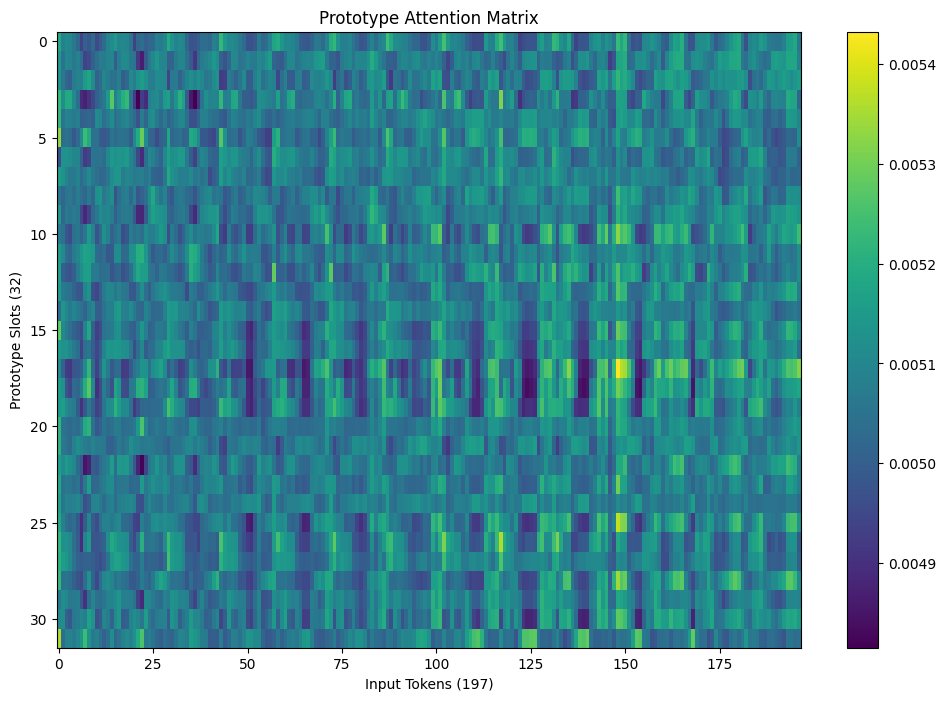

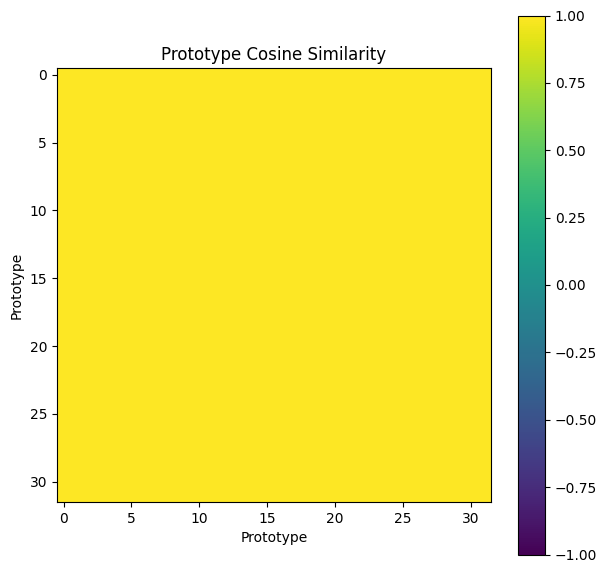

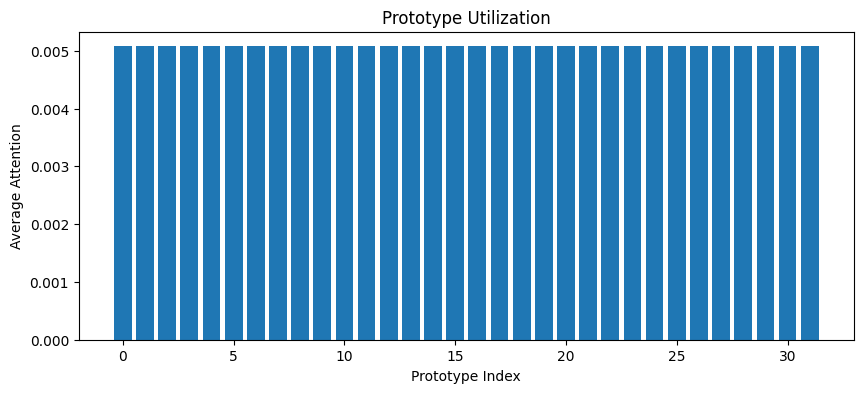


Parameter Summary
------------------------------------------------------------
Total Parameters      : 2,976,768
Trainable Parameters  : 2,976,768

GPU Memory
------------------------------------------------------------
Allocated : 105.39 MB
Reserved  : 148.00 MB

Prototype Initializer Verified Successfully ✅


In [14]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 6.2 : Prototype Initializer Verification & Debugging
# ================================================================

import torch
import matplotlib.pyplot as plt

# ================================================================
# Evaluation Mode
# ================================================================

stg.eval()
prototype_initializer.eval()

# ================================================================
# Forward Pass
# ================================================================

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    # STG
    stg_tokens = stg(images)

    # Prototype Initializer
    prototype_memory, prototype_attention = prototype_initializer(stg_tokens)

# ================================================================
# Shape Verification
# ================================================================

print("=" * 70)
print("Prototype Initializer Verification")
print("=" * 70)

print("\nInput Images")
print(images.shape)

print("\nSTG Tokens")
print(stg_tokens.shape)

print("\nPrototype Memory")
print(prototype_memory.shape)

print("\nPrototype Attention")
print(prototype_attention.shape)

assert stg_tokens.shape == (
    cfg.BATCH_SIZE,
    197,
    cfg.EMBED_DIM
)

assert prototype_memory.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.EMBED_DIM
)

assert prototype_attention.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    197
)

print("\nShape Verification Passed ✓")

# ================================================================
# Attention Verification
# ================================================================

attention_sum = prototype_attention.sum(dim=-1)

print("\nAttention Row Sum")

print("Minimum :", attention_sum.min().item())
print("Maximum :", attention_sum.max().item())
print("Mean    :", attention_sum.mean().item())

assert torch.allclose(
    attention_sum,
    torch.ones_like(attention_sum),
    atol=1e-4
)

print("Attention Normalization Passed ✓")

# ================================================================
# Prototype Memory Statistics
# ================================================================

print("\nPrototype Memory Statistics")
print("-" * 60)

print("Minimum :", prototype_memory.min().item())
print("Maximum :", prototype_memory.max().item())
print("Mean    :", prototype_memory.mean().item())
print("Std     :", prototype_memory.std().item())

# ================================================================
# Attention Statistics
# ================================================================

print("\nAttention Statistics")
print("-" * 60)

print("Minimum :", prototype_attention.min().item())
print("Maximum :", prototype_attention.max().item())
print("Mean    :", prototype_attention.mean().item())
print("Std     :", prototype_attention.std().item())

# ================================================================
# NaN / Inf Check
# ================================================================

print("\nNaN / Inf Check")
print("-" * 60)

print("Memory NaN :", torch.isnan(prototype_memory).sum().item())
print("Memory Inf :", torch.isinf(prototype_memory).sum().item())

print("Attention NaN :", torch.isnan(prototype_attention).sum().item())
print("Attention Inf :", torch.isinf(prototype_attention).sum().item())

assert not torch.isnan(prototype_memory).any()
assert not torch.isinf(prototype_memory).any()

assert not torch.isnan(prototype_attention).any()
assert not torch.isinf(prototype_attention).any()

print("Numerical Stability Passed ✓")

# ================================================================
# Prototype Norm Distribution
# ================================================================

prototype_norm = torch.norm(
    prototype_memory,
    dim=-1
)

print("\nPrototype Norm Statistics")
print("-" * 60)

print("Minimum :", prototype_norm.min().item())
print("Maximum :", prototype_norm.max().item())
print("Mean    :", prototype_norm.mean().item())

# ================================================================
# Visualization
# ================================================================

plt.figure(figsize=(12,8))

plt.imshow(
    prototype_attention[0].cpu(),
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar()

plt.xlabel("Input Tokens (197)")
plt.ylabel("Prototype Slots (32)")

plt.title("Prototype Attention Matrix")

plt.show()

# ================================================================
# Prototype Similarity Matrix
# ================================================================

memory = prototype_memory[0]

memory = torch.nn.functional.normalize(
    memory,
    dim=-1
)

similarity = torch.matmul(
    memory,
    memory.T
)

plt.figure(figsize=(7,7))

plt.imshow(
    similarity.cpu(),
    interpolation="nearest",
    vmin=-1,
    vmax=1
)

plt.colorbar()

plt.title("Prototype Cosine Similarity")

plt.xlabel("Prototype")

plt.ylabel("Prototype")

plt.show()

# ================================================================
# Memory Usage Histogram
# ================================================================

activation = prototype_attention.mean(dim=-1)[0]

plt.figure(figsize=(10,4))

plt.bar(
    range(cfg.MEMORY_SIZE),
    activation.cpu()
)

plt.xlabel("Prototype Index")
plt.ylabel("Average Attention")
plt.title("Prototype Utilization")

plt.show()

# ================================================================
# Parameter Summary
# ================================================================

total = sum(
    p.numel()
    for p in prototype_initializer.parameters()
)

trainable = sum(
    p.numel()
    for p in prototype_initializer.parameters()
    if p.requires_grad
)

print("\nParameter Summary")
print("-" * 60)

print(f"Total Parameters      : {total:,}")
print(f"Trainable Parameters  : {trainable:,}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    print("\nGPU Memory")
    print("-" * 60)

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved = torch.cuda.memory_reserved() / 1024**2

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

print("\nPrototype Initializer Verified Successfully ✅")

In [15]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 6.3a : Prototype Descriptor Extraction
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Descriptor Extractor
# ================================================================

class PrototypeDescriptorExtractor(nn.Module):
    """
    Creates a descriptor for every prototype.

    Inputs
    ------
    prototype_memory   : (B,K,D)
    attention_weights  : (B,K,N)

    Outputs
    -------
    descriptor : (B,K,D+3)

    Descriptor =
        Prototype Embedding (768)
      + Max Attention (1)
      + Mean Attention (1)
      + Attention Entropy (1)

    Total = 771 dimensions
    """

    def __init__(self, eps=1e-8):

        super().__init__()

        self.eps = eps

    # ------------------------------------------------------------

    def forward(
        self,
        prototype_memory,
        attention_weights
    ):

        B, K, D = prototype_memory.shape

        _, K2, N = attention_weights.shape

        assert K == K2

        # ========================================================
        # Maximum Attention
        # ========================================================

        max_attention = attention_weights.max(
            dim=-1,
            keepdim=True
        )[0]

        # (B,K,1)

        # ========================================================
        # Mean Attention
        # ========================================================

        mean_attention = attention_weights.mean(
            dim=-1,
            keepdim=True
        )

        # (B,K,1)

        # ========================================================
        # Attention Entropy
        # ========================================================

        entropy = -torch.sum(

            attention_weights *

            torch.log(
                attention_weights + self.eps
            ),

            dim=-1,
            keepdim=True

        )

        # (B,K,1)

        # ========================================================
        # Descriptor
        # ========================================================

        descriptor = torch.cat(

            [

                prototype_memory,

                max_attention,

                mean_attention,

                entropy

            ],

            dim=-1

        )

        return descriptor


# ================================================================
# Instantiate
# ================================================================

descriptor_extractor = PrototypeDescriptorExtractor().to(cfg.DEVICE)

print("="*70)
print("Prototype Descriptor Extractor")
print("="*70)

print(descriptor_extractor)

# ================================================================
# Forward Test
# ================================================================

prototype_initializer.eval()
stg.eval()

images, _ = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    tokens = stg(images)

    prototype_memory, prototype_attention = prototype_initializer(tokens)

    descriptor = descriptor_extractor(

        prototype_memory,

        prototype_attention

    )

# ================================================================
# Verification
# ================================================================

print("\n")
print("="*70)
print("Descriptor Verification")
print("="*70)

print("Prototype Memory :", prototype_memory.shape)

print("Attention        :", prototype_attention.shape)

print("Descriptor       :", descriptor.shape)

assert descriptor.shape == (

    cfg.BATCH_SIZE,

    cfg.MEMORY_SIZE,

    cfg.EMBED_DIM + 3

)

print("\nShape Verification Passed ✓")

# ================================================================
# Statistics
# ================================================================

print("\nDescriptor Statistics")
print("-"*60)

print("Minimum :", descriptor.min().item())

print("Maximum :", descriptor.max().item())

print("Mean    :", descriptor.mean().item())

print("Std     :", descriptor.std().item())

# ================================================================
# NaN / Inf
# ================================================================

print("\nNaN Values :", torch.isnan(descriptor).sum().item())

print("Inf Values :", torch.isinf(descriptor).sum().item())

assert not torch.isnan(descriptor).any()

assert not torch.isinf(descriptor).any()

print("\nDescriptor Module Verified Successfully ✅")

Prototype Descriptor Extractor
PrototypeDescriptorExtractor()


Descriptor Verification
Prototype Memory : torch.Size([16, 32, 768])
Attention        : torch.Size([16, 32, 197])
Descriptor       : torch.Size([16, 32, 771])

Shape Verification Passed ✓

Descriptor Statistics
------------------------------------------------------------
Minimum : -3.5081989765167236
Maximum : 5.283196449279785
Mean    : 0.006865647155791521
Std     : 1.015998125076294

NaN Values : 0
Inf Values : 0

Descriptor Module Verified Successfully ✅


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Allocation Gate
# ================================================================

class PrototypeAllocationGate(nn.Module):
    """
    Input
    -----
    Prototype Descriptor
        (B,32,771)

    Output
    ------
    Global Memory
        (B,32,768)

    Local Memory
        (B,32,768)

    Global Probability
        (B,32)

    Local Probability
        (B,32)

    Prototype Importance
        (B,32)
    """

    def __init__(
        self,
        descriptor_dim=771,
        hidden_dim=256,
        embed_dim=768,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim

        # --------------------------------------------------------
        # Allocation Network
        # --------------------------------------------------------

        self.network = nn.Sequential(

            nn.Linear(
                descriptor_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                2
            )

        )

        self.initialize_weights()

    # ------------------------------------------------------------

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(
        self,
        descriptor
    ):

        # ========================================================
        # Split Descriptor
        # ========================================================

        prototype_embedding = descriptor[:,:,:768]

        # (B,32,768)

        logits = self.network(descriptor)

        # (B,32,2)

        probability = F.softmax(
            logits,
            dim=-1
        )

        global_probability = probability[:,:,0]

        local_probability = probability[:,:,1]

        # ========================================================
        # Prototype Importance
        # ========================================================

        # ========================================================
        # Continuous Globality Score
        # ========================================================

        importance = (

            global_probability -

            local_probability

        )

        # Range:
        #
        # -1 → strongly local
        #
        #  0 → hybrid
        #
        # +1 → strongly global

        # ========================================================
        # Global Memory
        # ========================================================

        global_memory = (

            prototype_embedding *

            global_probability.unsqueeze(-1)

        )

        # ========================================================
        # Local Memory
        # ========================================================

        local_memory = (

            prototype_embedding *

            local_probability.unsqueeze(-1)

        )

        return (

            global_memory,

            local_memory,

            global_probability,

            local_probability,

            importance

        )


# ================================================================
# Instantiate
# ================================================================

pag = PrototypeAllocationGate(

    descriptor_dim=771,

    hidden_dim=256,

    embed_dim=cfg.EMBED_DIM,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Prototype Allocation Gate")
print("="*70)

print(pag)

total = sum(
    p.numel()
    for p in pag.parameters()
)

trainable = sum(
    p.numel()
    for p in pag.parameters()
    if p.requires_grad
)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nPAG Ready ✅")

Prototype Allocation Gate
PrototypeAllocationGate(
  (network): Sequential(
    (0): Linear(in_features=771, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
)

Total Parameters : 198,658
Trainable        : 198,658

PAG Ready ✅


Prototype Allocation Gate Verification

Global Memory
torch.Size([16, 32, 768])

Local Memory
torch.Size([16, 32, 768])

Global Probability
torch.Size([16, 32])

Local Probability
torch.Size([16, 32])

Importance
torch.Size([16, 32])

Competitive Importance
torch.Size([16, 32])

Shape Verification Passed ✓

Probability Check
------------------------------------------------------------
Minimum : 0.9999999403953552
Maximum : 1.0000001192092896
Mean    : 1.0
Global + Local = 1 ✓

Competition Check
------------------------------------------------------------
Minimum : 0.9999999403953552
Maximum : 1.0
Mean    : 1.0
Competition Normalization Passed ✓

Importance Statistics
------------------------------------------------------------
Minimum : -0.9781338572502136
Maximum : -0.009366244077682495
Mean    : -0.5681795477867126
Std     : 0.33067062497138977

NaN Check
------------------------------------------------------------
0
0


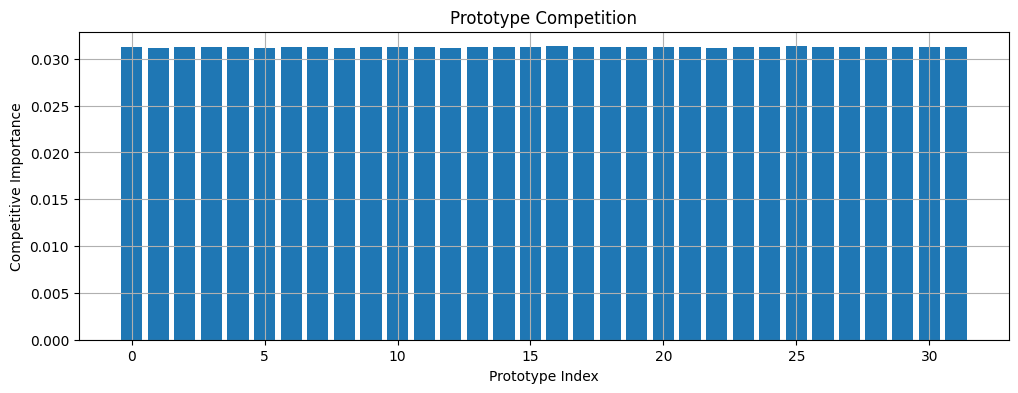

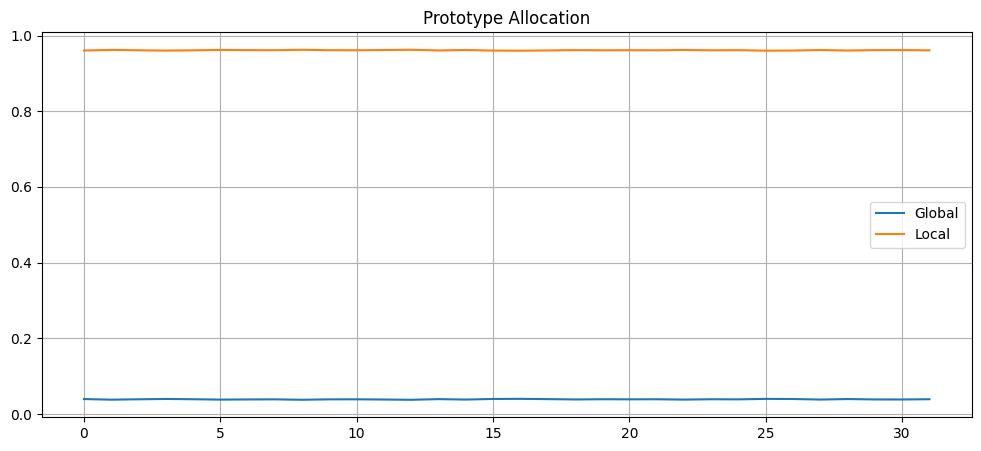


Top-5 Prototype Indices
tensor([16, 25,  3, 15, 26], device='cuda:0')

Top-5 Importance
tensor([0.0313, 0.0313, 0.0313, 0.0313, 0.0313], device='cuda:0')

PAG Verified Successfully ✅

Globality
torch.Size([16, 32])

Globality Statistics
------------------------------------------------------------
Minimum : -0.9781338572502136
Maximum : -0.009366244077682495
Mean    : -0.5681795477867126
Std     : 0.33067062497138977


In [17]:
# ================================================================
# PALT: Prototype-centric Adaptive Liquid Transformer
# Cell 6.3c : PAG Verification + Prototype Competition
# ================================================================

import matplotlib.pyplot as plt
import torch

# ================================================================
# Evaluation Mode
# ================================================================

stg.eval()

prototype_initializer.eval()

descriptor_extractor.eval()

pag.eval()

# ================================================================
# Forward
# ================================================================

images,_ = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    tokens = stg(images)

    prototype_memory, prototype_attention = prototype_initializer(tokens)

    descriptor = descriptor_extractor(

        prototype_memory,

        prototype_attention

    )

    (

        global_memory,

        local_memory,

        global_probability,

        local_probability,

        globality # This will receive the 5th value (importance) from pag

    ) = pag(descriptor)

# ================================================================
# Prototype Competition
# ================================================================

competitive_importance = torch.softmax(

    globality,

    dim=1

)

# ================================================================
# Shape Verification
# ================================================================

print("="*70)

print("Prototype Allocation Gate Verification")

print("="*70)

print("\nGlobal Memory")

print(global_memory.shape)

print("\nLocal Memory")

print(local_memory.shape)

print("\nGlobal Probability")

print(global_probability.shape)

print("\nLocal Probability")

print(local_probability.shape)

print("\nImportance")

print(globality.shape) # Changed to globality

print("\nCompetitive Importance")

print(competitive_importance.shape)

assert global_memory.shape == (

    cfg.BATCH_SIZE,

    cfg.MEMORY_SIZE,

    cfg.EMBED_DIM

)

assert local_memory.shape == (

    cfg.BATCH_SIZE,

    cfg.MEMORY_SIZE,

    cfg.EMBED_DIM

)

assert competitive_importance.shape == (

    cfg.BATCH_SIZE,

    cfg.MEMORY_SIZE

)

print("\nShape Verification Passed ✓")

# ================================================================
# Probability Check
# ================================================================

prob_sum = (

    global_probability +

    local_probability

)

print("\nProbability Check")

print("-"*60)

print("Minimum :",prob_sum.min().item())

print("Maximum :",prob_sum.max().item())

print("Mean    :",prob_sum.mean().item())

assert torch.allclose(

    prob_sum,

    torch.ones_like(prob_sum),

    atol=1e-5

)

print("Global + Local = 1 ✓")

# ================================================================
# Competition Check
# ================================================================

competition_sum = competitive_importance.sum(

    dim=1

)

print("\nCompetition Check")

print("-"*60)

print("Minimum :",competition_sum.min().item())

print("Maximum :",competition_sum.max().item())

print("Mean    :",competition_sum.mean().item())

assert torch.allclose(

    competition_sum,

    torch.ones_like(competition_sum),

    atol=1e-5

)

print("Competition Normalization Passed ✓")

# ================================================================
# Statistics
# ================================================================

print("\nImportance Statistics")

print("-"*60)

print("Minimum :",globality.min().item()) # Changed to globality

print("Maximum :",globality.max().item()) # Changed to globality

print("Mean    :",globality.mean().item()) # Changed to globality

print("Std     :",globality.std().item()) # Changed to globality

# ================================================================
# NaN / Inf
# ================================================================

print("\nNaN Check")

print("-"*60)

print(torch.isnan(competitive_importance).sum().item())

print(torch.isinf(competitive_importance).sum().item())

assert not torch.isnan(

    competitive_importance

).any()

assert not torch.isinf(

    competitive_importance

).any()

# ================================================================
# Visualization
# ================================================================

plt.figure(figsize=(12,4))

plt.bar(

    range(cfg.MEMORY_SIZE),

    competitive_importance[0].cpu()

)

plt.title(

    "Prototype Competition"

)

plt.xlabel(

    "Prototype Index"

)

plt.ylabel(

    "Competitive Importance"

)

plt.grid(True)

plt.show()

# ================================================================
# Global vs Local Allocation
# ================================================================

plt.figure(figsize=(12,5))

plt.plot(

    global_probability[0].cpu(),

    label="Global"

)

plt.plot(

    local_probability[0].cpu(),

    label="Local"

)

plt.legend()

plt.grid(True)

plt.title(

    "Prototype Allocation"

)

plt.show()

# ================================================================
# Top Prototypes
# ================================================================

topk = torch.topk(

    competitive_importance,

    k=5,

    dim=1

)

print("\nTop-5 Prototype Indices")

print(topk.indices[0])

print("\nTop-5 Importance")

print(topk.values[0])

print("\nPAG Verified Successfully ✅")



print("\nGlobality")

print(globality.shape)

assert globality.shape == (

    cfg.BATCH_SIZE,

    cfg.MEMORY_SIZE

)

print("\nGlobality Statistics")

print("-"*60)

print("Minimum :",globality.min().item())

print("Maximum :",globality.max().item())

print("Mean    :",globality.mean().item())

print("Std     :",globality.std().item())

In [18]:
# ================================================================
# PALT
# Cell 6.3d : Prototype Interaction Graph (GAR)
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Interaction Graph
# ================================================================

class PrototypeInteractionGraph(nn.Module):

    """
    Inputs
    ------
    prototype_memory : (B,K,D)

    Outputs
    -------
    refined_memory   : (B,K,D)

    similarity       : (B,K,K)

    graph_attention  : (B,K,K)
    """

    def __init__(
        self,
        embed_dim=768,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim

        self.query = nn.Linear(embed_dim, embed_dim, bias=False)
        self.key   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.value = nn.Linear(embed_dim, embed_dim, bias=False)

        self.output = nn.Linear(embed_dim, embed_dim)

        self.norm = nn.LayerNorm(embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.gamma = nn.Parameter(torch.tensor(0.0))

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(self, prototype_memory):

        # ========================================================
        # Normalize
        # ========================================================

        memory = F.normalize(
            prototype_memory,
            p=2,
            dim=-1
        )

        # ========================================================
        # Cosine Similarity Graph
        # ========================================================

        similarity = torch.matmul(

            memory,

            memory.transpose(-2,-1)

        )

        # ========================================================
        # Graph Attention
        # ========================================================

        Q = self.query(memory)

        K = self.key(memory)

        V = self.value(memory)

        score = torch.matmul(

            Q,

            K.transpose(-2,-1)

        )

        score = score / math.sqrt(self.embed_dim)

        score = score + similarity

        graph_attention = F.softmax(

            score,

            dim=-1

        )

        graph_attention = self.dropout(

            graph_attention

        )

        refined = torch.matmul(

            graph_attention,

            V

        )

        refined = self.output(refined)

        refined = self.norm(

            memory +

            self.gamma * refined

        )

        return (

            refined,

            similarity,

            graph_attention

        )


# ================================================================
# Instantiate
# ================================================================

pig = PrototypeInteractionGraph(

    embed_dim=cfg.EMBED_DIM,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Prototype Interaction Graph")
print("="*70)

print(pig)

total = sum(
    p.numel()
    for p in pig.parameters()
)

print("\nParameters :", format(total,","))

Prototype Interaction Graph
PrototypeInteractionGraph(
  (query): Linear(in_features=768, out_features=768, bias=False)
  (key): Linear(in_features=768, out_features=768, bias=False)
  (value): Linear(in_features=768, out_features=768, bias=False)
  (output): Linear(in_features=768, out_features=768, bias=True)
  (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

Parameters : 2,361,601


In [19]:
# ================================================================
# PALT
# Cell 6.4 : Prototype Liquid Dynamics (PLD)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Liquid Dynamics
# ================================================================

class PrototypeLiquidDynamics(nn.Module):
    """
    Prototype Liquid Dynamics (PLD)

    Input
    -----
    prototype_memory : (B,K,D)

    Output
    ------
    candidate_memory : (B,K,D)

    tau              : (B,K,1)

    beta             : (B,K,1)
    """

    def __init__(
        self,
        embed_dim=768,
        hidden_dim=256
    ):

        super().__init__()

        self.embed_dim = embed_dim

        # --------------------------------------------------------
        # Shared feature extractor
        # --------------------------------------------------------

        self.feature = nn.Sequential(

            nn.Linear(embed_dim, hidden_dim),

            nn.GELU(),

            nn.LayerNorm(hidden_dim)

        )

        # --------------------------------------------------------
        # Time Constant
        # τ > 0
        # --------------------------------------------------------

        self.tau_head = nn.Linear(
            hidden_dim,
            1
        )

        # --------------------------------------------------------
        # Plasticity
        # β ∈ [0,1]
        # --------------------------------------------------------

        self.beta_head = nn.Linear(
            hidden_dim,
            1
        )

        # --------------------------------------------------------
        # Candidate Update
        # --------------------------------------------------------

        self.delta_memory = nn.Linear(
            hidden_dim,
            embed_dim
        )

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(
        self,
        prototype_memory
    ):

        # ========================================================
        # Shared Features
        # ========================================================

        h = self.feature(prototype_memory)

        # ========================================================
        # Time Constant
        # Softplus ensures τ > 0
        # ========================================================

        tau = F.softplus(

            self.tau_head(h)

        ) + 1e-4

        # ========================================================
        # Plasticity
        # ========================================================

        beta = torch.sigmoid(

            self.beta_head(h)

        )

        # ========================================================
        # Candidate Update
        # ========================================================

        delta = torch.tanh(

            self.delta_memory(h)

        )

        # ========================================================
        # Stable Liquid Dynamics
        # ========================================================

        alpha = torch.exp(

            -1.0 / tau

        )

        candidate_memory = (

            alpha * prototype_memory +

            (1.0 - alpha) *

            beta *

            delta

        )

        return (

            candidate_memory,

            tau,

            beta,

            delta

        )


# ================================================================
# Instantiate
# ================================================================

pld = PrototypeLiquidDynamics(

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256

).to(cfg.DEVICE)

print("="*70)
print("Prototype Liquid Dynamics")
print("="*70)

print(pld)

total = sum(
    p.numel()
    for p in pld.parameters()
)

trainable = sum(
    p.numel()
    for p in pld.parameters()
    if p.requires_grad
)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nPLD Ready ✅")

Prototype Liquid Dynamics
PrototypeLiquidDynamics(
  (feature): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  )
  (tau_head): Linear(in_features=256, out_features=1, bias=True)
  (beta_head): Linear(in_features=256, out_features=1, bias=True)
  (delta_memory): Linear(in_features=256, out_features=768, bias=True)
)

Total Parameters : 395,266
Trainable        : 395,266

PLD Ready ✅


Prototype Liquid Dynamics Verification

Prototype Memory : torch.Size([16, 32, 768])
Candidate Memory : torch.Size([16, 32, 768])
Tau              : torch.Size([16, 32, 1])
Beta             : torch.Size([16, 32, 1])
Delta            : torch.Size([16, 32, 768])

Shape Verification Passed ✓

Numerical Stability
------------------------------------------------------------

Candidate Memory
NaN : 0
Inf : 0

Tau
NaN : 0
Inf : 0

Beta
NaN : 0
Inf : 0

Delta
NaN : 0
Inf : 0

Numerical Stability Passed ✓

Tau Statistics
------------------------------------------------------------
Min  : 0.19231869280338287
Max  : 2.1115522384643555
Mean : 0.791968584060669
Std  : 0.5317928194999695

Beta Statistics
------------------------------------------------------------
Min  : 0.17208179831504822
Max  : 0.7880814075469971
Mean : 0.5823541879653931
Std  : 0.15014128386974335

Candidate Memory Statistics
------------------------------------------------------------
Min  : -1.8712022304534912
Max  : 1.7836210

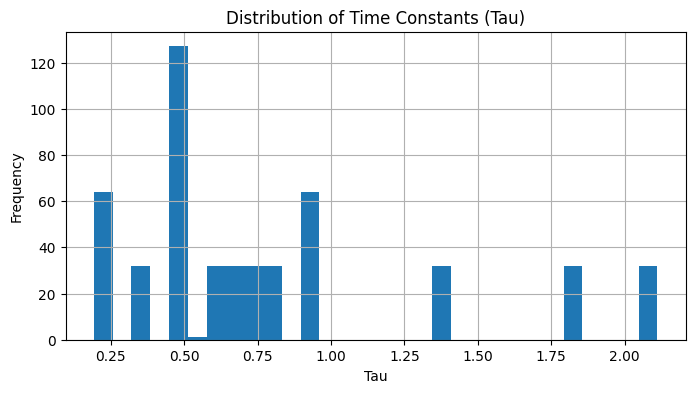

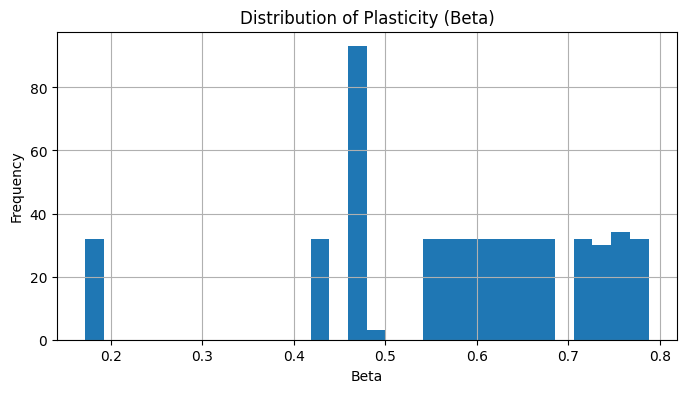

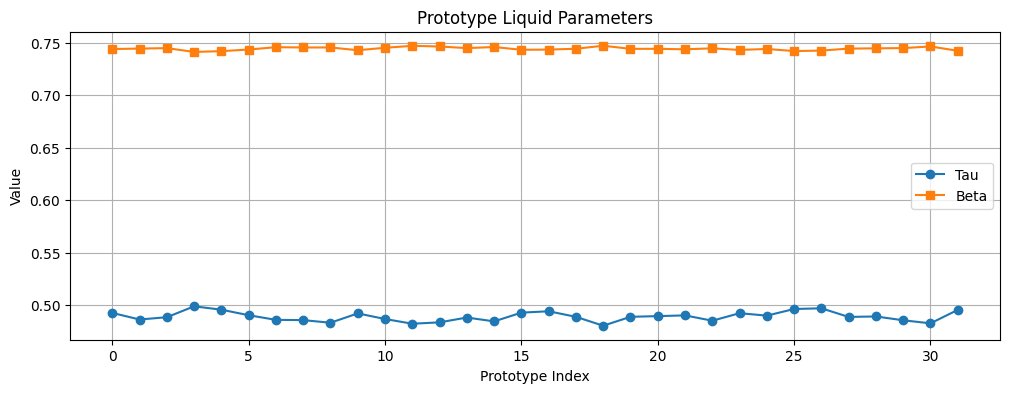


Parameter Summary
------------------------------------------------------------
Total Parameters     : 395,266
Trainable Parameters : 395,266

GPU Memory
------------------------------------------------------------
Allocated : 133.08 MB
Reserved  : 212.00 MB

Prototype Liquid Dynamics Verified Successfully ✅


In [20]:
import matplotlib.pyplot as plt
import torch

# ================================================================
# Evaluation Mode
# ================================================================

stg.eval()
prototype_initializer.eval()
pig.eval()
descriptor_extractor.eval()
pag.eval()
pld.eval()

# ================================================================
# Forward Pass
# ================================================================

images, labels = next(iter(train_loader))
images = images.to(cfg.DEVICE)

with torch.no_grad():

    # ------------------------------------------------------------
    # STG
    # ------------------------------------------------------------

    tokens = stg(images)

    # ------------------------------------------------------------
    # Prototype Initialization
    # ------------------------------------------------------------

    prototype_memory, prototype_attention = prototype_initializer(tokens)

    # ------------------------------------------------------------
    # Prototype Interaction Graph
    # ------------------------------------------------------------

    prototype_memory, similarity, graph_attention = pig(prototype_memory)

    # ------------------------------------------------------------
    # Descriptor
    # ------------------------------------------------------------

    descriptor = descriptor_extractor(
        prototype_memory,
        prototype_attention
    )

    # ------------------------------------------------------------
    # PAG
    # ------------------------------------------------------------

    (
        global_memory,
        local_memory,
        global_probability,
        local_probability,
        globality # This will receive the 5th value (importance) from pag
    ) = pag(descriptor)

    # ------------------------------------------------------------
    # Prototype Liquid Dynamics
    # ------------------------------------------------------------

    (
        candidate_memory,
        tau,
        beta,
        delta
    ) = pld(prototype_memory)

# ================================================================
# Shape Verification
# ================================================================

print("="*70)
print("Prototype Liquid Dynamics Verification")
print("="*70)

print("\nPrototype Memory :", prototype_memory.shape)
print("Candidate Memory :", candidate_memory.shape)
print("Tau              :", tau.shape)
print("Beta             :", beta.shape)
print("Delta            :", delta.shape)

assert candidate_memory.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.EMBED_DIM
)

assert tau.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    1
)

assert beta.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    1
)

assert delta.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.EMBED_DIM
)

print("\nShape Verification Passed ✓")

# ================================================================
# Numerical Stability
# ================================================================

print("\nNumerical Stability")
print("-"*60)

for name, tensor in {

    "Candidate Memory": candidate_memory,
    "Tau": tau,
    "Beta": beta,
    "Delta": delta

}.items():

    print(f"\n{name}")

    print("NaN :", torch.isnan(tensor).sum().item())
    print("Inf :", torch.isinf(tensor).sum().item())

    assert not torch.isnan(tensor).any()
    assert not torch.isinf(tensor).any()

print("\nNumerical Stability Passed ✓")

# ================================================================
# Tau Statistics
# ================================================================

print("\nTau Statistics")
print("-"*60)

print("Min  :", tau.min().item())
print("Max  :", tau.max().item())
print("Mean :", tau.mean().item())
print("Std  :", tau.std().item())

# ================================================================
# Beta Statistics
# ================================================================

print("\nBeta Statistics")
print("-"*60)

print("Min  :", beta.min().item())
print("Max  :", beta.max().item())
print("Mean :", beta.mean().item())
print("Std  :", beta.std().item())

# ================================================================
# Candidate Memory Statistics
# ================================================================

print("\nCandidate Memory Statistics")
print("-"*60)

print("Min  :", candidate_memory.min().item())
print("Max  :", candidate_memory.max().item())
print("Mean :", candidate_memory.mean().item())
print("Std  :", candidate_memory.std().item())

# ================================================================
# Delta Statistics
# ================================================================

print("\nDelta Memory Statistics")
print("-"*60)

print("Min  :", delta.min().item())
print("Max  :", delta.max().item())
print("Mean :", delta.mean().item())
print("Std  :", delta.std().item())

# ================================================================
# Histograms
# ================================================================

plt.figure(figsize=(8,4))
plt.hist(
    tau.cpu().view(-1),
    bins=30
)
plt.title("Distribution of Time Constants (Tau)")
plt.xlabel("Tau")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,4))
plt.hist(
    beta.cpu().view(-1),
    bins=30
)
plt.title("Distribution of Plasticity (Beta)")
plt.xlabel("Beta")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

# ================================================================
# Prototype-wise Visualization
# ================================================================

plt.figure(figsize=(12,4))

plt.plot(
    tau[0,:,0].cpu(),
    marker='o',
    label="Tau"
)

plt.plot(
    beta[0,:,0].cpu(),
    marker='s',
    label="Beta"
)

plt.xlabel("Prototype Index")
plt.ylabel("Value")
plt.title("Prototype Liquid Parameters")
plt.grid(True)
plt.legend()

plt.show()

# ================================================================
# Parameter Summary
# ================================================================

total_params = sum(
    p.numel()
    for p in pld.parameters()
)

trainable_params = sum(
    p.numel()
    for p in pld.parameters()
    if p.requires_grad
)

print("\nParameter Summary")
print("-"*60)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    print("\nGPU Memory")
    print("-"*60)

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved = torch.cuda.memory_reserved() / 1024**2

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

print("\nPrototype Liquid Dynamics Verified Successfully ✅")

In [21]:
# ================================================================
# PALT
# Cell 6.5 : Memory Retention Gate (MRG)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Memory Retention Gate
# ================================================================

class MemoryRetentionGate(nn.Module):

    """
    Inputs
    ------
    prototype_memory : (B,K,D)

    candidate_memory : (B,K,D)

    globality        : (B,K)

    Outputs
    -------
    updated_memory   : (B,K,D)

    retention_gate   : (B,K,1)
    """

    def __init__(
        self,
        embed_dim=768,
        hidden_dim=256
    ):

        super().__init__()

        self.embed_dim = embed_dim

        input_dim = embed_dim * 2 + 1

        self.gate = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Linear(
                hidden_dim,
                1
            )

        )

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(

        self,

        prototype_memory,

        candidate_memory,

        globality

    ):

        # --------------------------------------------------------

        g = globality.unsqueeze(-1)

        # (B,K,1)

        x = torch.cat(

            [

                prototype_memory,

                candidate_memory,

                g

            ],

            dim=-1

        )

        # --------------------------------------------------------

        retention_gate = torch.sigmoid(

            self.gate(x)

        )

        # --------------------------------------------------------

        updated_memory = (

            retention_gate *

            prototype_memory +

            (1.0-retention_gate) *

            candidate_memory

        )

        return (

            updated_memory,

            retention_gate

        )


# ================================================================
# Instantiate
# ================================================================

mrg = MemoryRetentionGate(

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256

).to(cfg.DEVICE)

print("="*70)
print("Memory Retention Gate")
print("="*70)

print(mrg)

total = sum(

    p.numel()

    for p in mrg.parameters()

)

trainable = sum(

    p.numel()

    for p in mrg.parameters()

    if p.requires_grad

)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nMRG Ready ✅")

Memory Retention Gate
MemoryRetentionGate(
  (gate): Sequential(
    (0): Linear(in_features=1537, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (3): Linear(in_features=256, out_features=1, bias=True)
  )
)

Total Parameters : 394,497
Trainable        : 394,497

MRG Ready ✅


Memory Retention Gate Verification

Prototype Memory : torch.Size([16, 32, 768])
Candidate Memory : torch.Size([16, 32, 768])
Updated Memory   : torch.Size([16, 32, 768])
Retention Gate   : torch.Size([16, 32, 1])

Shape Verification Passed ✓

Retention Gate Statistics
------------------------------------------------------------
Minimum : 0.3603259325027466
Maximum : 0.9127007722854614
Mean    : 0.756335973739624
Std     : 0.14535030722618103

Updated Memory Statistics
------------------------------------------------------------
Minimum : -3.2352871894836426
Maximum : 2.995748281478882
Mean    : 0.00013432223931886256
Std     : 0.827559769153595

Memory Update Magnitude
------------------------------------------------------------
Minimum : 2.173875570297241
Maximum : 12.370633125305176
Mean    : 5.077694892883301
Std     : 2.7513267993927

NaN / Inf Check
------------------------------------------------------------
Updated Memory NaN : 0
Updated Memory Inf : 0
Gate NaN : 0
Gate Inf : 0

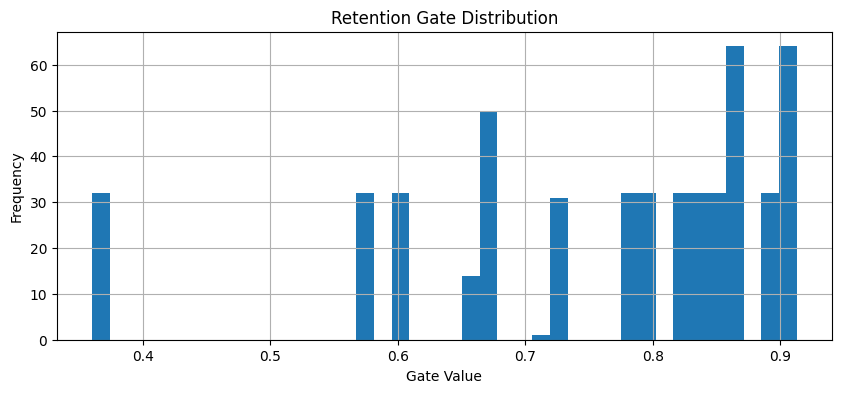

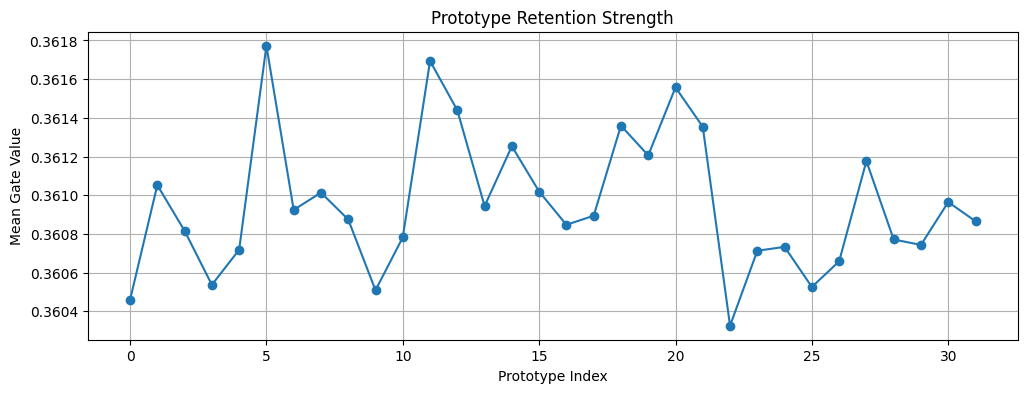

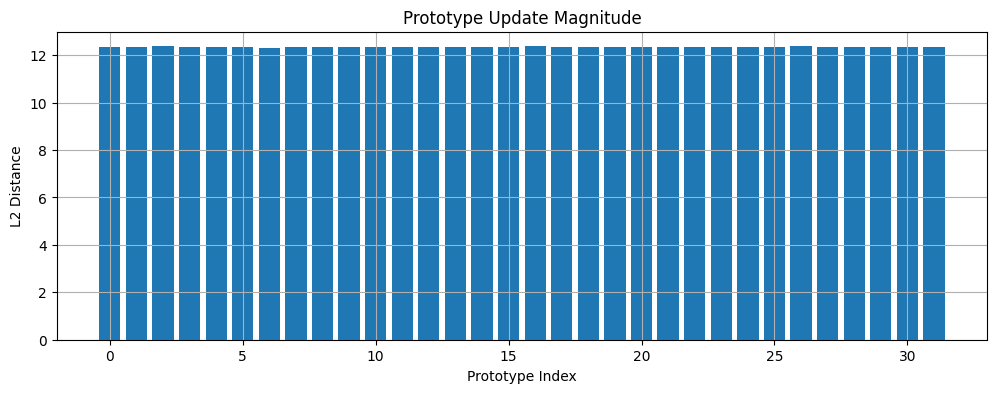


Parameter Summary
------------------------------------------------------------
Total Parameters     : 394,497
Trainable Parameters : 394,497

GPU Memory
------------------------------------------------------------
Allocated : 138.38 MB
Reserved  : 212.00 MB

Memory Retention Gate Verified Successfully ✅


In [22]:
# ================================================================
# PALT
# Cell 6.5b : Memory Retention Gate Verification
# ================================================================

import torch
import matplotlib.pyplot as plt

# ================================================================
# Evaluation Mode
# ================================================================

stg.eval()
prototype_initializer.eval()
pig.eval()
descriptor_extractor.eval()
pag.eval()
pld.eval()
mrg.eval()

# ================================================================
# Forward Pass
# ================================================================

images, labels = next(iter(train_loader))
images = images.to(cfg.DEVICE)

with torch.no_grad():

    # ------------------------------------------------------------
    # STG
    # ------------------------------------------------------------

    tokens = stg(images)

    # ------------------------------------------------------------
    # Prototype Initialization
    # ------------------------------------------------------------

    prototype_memory, prototype_attention = prototype_initializer(tokens)

    # ------------------------------------------------------------
    # Prototype Interaction Graph
    # ------------------------------------------------------------

    prototype_memory, similarity, graph_attention = pig(prototype_memory)

    # ------------------------------------------------------------
    # Descriptor
    # ------------------------------------------------------------

    descriptor = descriptor_extractor(
        prototype_memory,
        prototype_attention
    )

    # ------------------------------------------------------------
    # PAG
    # ------------------------------------------------------------

    (
        global_memory,
        local_memory,
        global_probability,
        local_probability,
        globality
    ) = pag(descriptor)

    # ------------------------------------------------------------
    # PLD
    # ------------------------------------------------------------

    (
        candidate_memory,
        tau,
        beta,
        delta
    ) = pld(prototype_memory)

    # ------------------------------------------------------------
    # MRG
    # ------------------------------------------------------------

    updated_memory, retention_gate = mrg(

        prototype_memory,

        candidate_memory,

        globality

    )

# ================================================================
# Shape Verification
# ================================================================

print("="*70)
print("Memory Retention Gate Verification")
print("="*70)

print("\nPrototype Memory :", prototype_memory.shape)
print("Candidate Memory :", candidate_memory.shape)
print("Updated Memory   :", updated_memory.shape)
print("Retention Gate   :", retention_gate.shape)

assert updated_memory.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.EMBED_DIM
)

print("\nShape Verification Passed ✓")

# ================================================================
# Gate Statistics
# ================================================================

print("\nRetention Gate Statistics")
print("-"*60)

print("Minimum :", retention_gate.min().item())
print("Maximum :", retention_gate.max().item())
print("Mean    :", retention_gate.mean().item())
print("Std     :", retention_gate.std().item())

# ================================================================
# Updated Memory Statistics
# ================================================================

print("\nUpdated Memory Statistics")
print("-"*60)

print("Minimum :", updated_memory.min().item())
print("Maximum :", updated_memory.max().item())
print("Mean    :", updated_memory.mean().item())
print("Std     :", updated_memory.std().item())

# ================================================================
# Difference Statistics
# ================================================================

difference = torch.norm(

    updated_memory -

    prototype_memory,

    dim=-1

)

print("\nMemory Update Magnitude")
print("-"*60)

print("Minimum :", difference.min().item())
print("Maximum :", difference.max().item())
print("Mean    :", difference.mean().item())
print("Std     :", difference.std().item())

# ================================================================
# NaN / Inf Check
# ================================================================

print("\nNaN / Inf Check")
print("-"*60)

print("Updated Memory NaN :", torch.isnan(updated_memory).sum().item())
print("Updated Memory Inf :", torch.isinf(updated_memory).sum().item())

print("Gate NaN :", torch.isnan(retention_gate).sum().item())
print("Gate Inf :", torch.isinf(retention_gate).sum().item())

assert not torch.isnan(updated_memory).any()
assert not torch.isinf(updated_memory).any()

assert not torch.isnan(retention_gate).any()
assert not torch.isinf(retention_gate).any()

print("\nNumerical Stability Passed ✓")

# ================================================================
# Visualization
# ================================================================

plt.figure(figsize=(10,4))

plt.hist(
    retention_gate.cpu().view(-1),
    bins=40
)

plt.title("Retention Gate Distribution")
plt.xlabel("Gate Value")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

# ================================================================
# Prototype-wise Mean Gate
# ================================================================

if retention_gate.shape[-1] == 1:

    gate_values = retention_gate[0,:,0].cpu()

else:

    gate_values = retention_gate[0].mean(dim=-1).cpu()

plt.figure(figsize=(12,4))

plt.plot(
    gate_values,
    marker='o'
)

plt.title("Prototype Retention Strength")
plt.xlabel("Prototype Index")
plt.ylabel("Mean Gate Value")
plt.grid(True)

plt.show()

# ================================================================
# Memory Difference Visualization
# ================================================================

plt.figure(figsize=(12,4))

plt.bar(

    range(cfg.MEMORY_SIZE),

    difference[0].cpu()

)

plt.title("Prototype Update Magnitude")
plt.xlabel("Prototype Index")
plt.ylabel("L2 Distance")
plt.grid(True)

plt.show()

# ================================================================
# Parameter Summary
# ================================================================

total_params = sum(

    p.numel()

    for p in mrg.parameters()

)

trainable_params = sum(

    p.numel()

    for p in mrg.parameters()

    if p.requires_grad

)

print("\nParameter Summary")
print("-"*60)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    print("\nGPU Memory")
    print("-"*60)

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved = torch.cuda.memory_reserved() / 1024**2

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

print("\nMemory Retention Gate Verified Successfully ✅")

In [23]:
# ================================================================
# PALT
# Cell 6.6a : Prototype Consistency Normalization (PCN)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Consistency Normalization
# ================================================================

class PrototypeConsistencyNormalization(nn.Module):
    """
    Inputs
    ------
    prototype_memory
        (B,K,D)

    Outputs
    -------
    normalized_memory
        (B,K,D)

    gamma
        scalar learnable mixing coefficient
    """

    def __init__(
        self,
        embed_dim=768,
        eps=1e-6
    ):

        super().__init__()

        self.layer_norm = nn.LayerNorm(embed_dim)

        self.gamma = nn.Parameter(
            torch.tensor(0.0)
        )

        self.eps = eps

    # ------------------------------------------------------------

    def forward(self, prototype_memory):

        # ========================================================
        # Layer Normalization
        # ========================================================

        layer_memory = self.layer_norm(
            prototype_memory
        )

        # ========================================================
        # L2 Normalization
        # ========================================================

        l2_memory = F.normalize(

            prototype_memory,

            p=2,

            dim=-1,

            eps=self.eps

        )

        # ========================================================
        # Adaptive Mixing
        # ========================================================

        gamma = torch.sigmoid(

            self.gamma

        )

        normalized_memory = (

            gamma *

            layer_memory +

            (1.0-gamma) *

            l2_memory

        )

        return (

            normalized_memory,

            gamma

        )


# ================================================================
# Instantiate
# ================================================================

pcn = PrototypeConsistencyNormalization(

    embed_dim=cfg.EMBED_DIM

).to(cfg.DEVICE)

print("="*70)
print("Prototype Consistency Normalization")
print("="*70)

print(pcn)

total = sum(

    p.numel()

    for p in pcn.parameters()

)

trainable = sum(

    p.numel()

    for p in pcn.parameters()

    if p.requires_grad

)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nPCN Ready ✅")

# ================================================================
# Quick Forward Test
# ================================================================

pcn.eval()

with torch.no_grad():

    normalized_memory, gamma = pcn(updated_memory)

print("\n")
print("="*70)
print("PCN Verification")
print("="*70)

print("Input Memory      :", updated_memory.shape)
print("Normalized Memory :", normalized_memory.shape)

assert normalized_memory.shape == updated_memory.shape

print("\nGamma")
print("Value :", gamma.item())

print("\nStatistics")
print("-"*60)

print("Minimum :", normalized_memory.min().item())
print("Maximum :", normalized_memory.max().item())
print("Mean    :", normalized_memory.mean().item())
print("Std     :", normalized_memory.std().item())

print("\nNaN :", torch.isnan(normalized_memory).sum().item())
print("Inf :", torch.isinf(normalized_memory).sum().item())

assert not torch.isnan(normalized_memory).any()
assert not torch.isinf(normalized_memory).any()

print("\nPCN Verified Successfully ✅")

Prototype Consistency Normalization
PrototypeConsistencyNormalization(
  (layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

Total Parameters : 1,537
Trainable        : 1,537

PCN Ready ✅


PCN Verification
Input Memory      : torch.Size([16, 32, 768])
Normalized Memory : torch.Size([16, 32, 768])

Gamma
Value : 0.5

Statistics
------------------------------------------------------------
Minimum : -1.815506935119629
Maximum : 1.7336769104003906
Mean    : 4.286135663278401e-06
Std     : 0.5180389881134033

NaN : 0
Inf : 0

PCN Verified Successfully ✅


In [24]:
# ================================================================
# PALT
# Cell 6.6b : Adaptive Latent Spectral Basis Learning (A-LSBL)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Adaptive Latent Spectral Basis Learning
# ================================================================

class AdaptiveLatentSpectralBasisLearning(nn.Module):
    """
    Inputs
    ------
    normalized_memory
        (B,K,D)

    Outputs
    -------
    refined_memory
        (B,K,D)

    coefficients
        (B,K,L)

    basis_vectors
        (L,D)

    reconstructed_basis
        (B,K,D)

    alpha
        scalar
    """

    def __init__(
        self,
        embed_dim=768,
        latent_bases=16,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim
        self.latent_bases = latent_bases

        # --------------------------------------------------------
        # Coefficient Predictor
        # --------------------------------------------------------

        self.coefficient_network = nn.Sequential(

            nn.Linear(embed_dim, hidden_dim),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Dropout(dropout),

            nn.Linear(hidden_dim, latent_bases)

        )

        # --------------------------------------------------------
        # Learnable Spectral Dictionary
        # --------------------------------------------------------

        self.dictionary = nn.Parameter(

            torch.randn(
                latent_bases,
                embed_dim
            ) * 0.02

        )

        # --------------------------------------------------------
        # Residual Mixing
        # --------------------------------------------------------

        self.alpha = nn.Parameter(
            torch.tensor(0.0)
        )

        self.output_norm = nn.LayerNorm(embed_dim)

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        nn.init.xavier_uniform_(self.dictionary)

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(
        self,
        normalized_memory
    ):

        # ========================================================
        # Basis Coefficients
        # ========================================================

        coefficients = self.coefficient_network(
            normalized_memory
        )

        coefficients = F.softmax(
            coefficients,
            dim=-1
        )

        # ========================================================
        # Dictionary Reconstruction
        # ========================================================

        reconstructed_basis = torch.matmul(

            coefficients,

            self.dictionary

        )

        # ========================================================
        # Adaptive Residual Mixing
        # ========================================================

        alpha = torch.sigmoid(
            self.alpha
        )

        refined_memory = (

            normalized_memory +

            alpha *

            reconstructed_basis

        )

        refined_memory = self.output_norm(
            refined_memory
        )

        return (

            refined_memory,

            coefficients,

            self.dictionary,

            reconstructed_basis,

            alpha

        )


# ================================================================
# Instantiate
# ================================================================

alsbl = AdaptiveLatentSpectralBasisLearning(

    embed_dim=cfg.EMBED_DIM,

    latent_bases=16,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Adaptive Latent Spectral Basis Learning")
print("="*70)

print(alsbl)

total = sum(
    p.numel()
    for p in alsbl.parameters()
)

trainable = sum(
    p.numel()
    for p in alsbl.parameters()
    if p.requires_grad
)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nA-LSBL Ready ✅")

# ================================================================
# Quick Forward Test
# ================================================================

alsbl.eval()

with torch.no_grad():

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha
    ) = alsbl(normalized_memory)

print("\n")
print("="*70)
print("A-LSBL Verification")
print("="*70)

print("Input Memory        :", normalized_memory.shape)
print("Refined Memory      :", refined_memory.shape)
print("Coefficients        :", coefficients.shape)
print("Dictionary          :", dictionary.shape)
print("Reconstructed Basis :", reconstructed_basis.shape)

assert refined_memory.shape == normalized_memory.shape

assert coefficients.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    16
)

assert dictionary.shape == (
    16,
    cfg.EMBED_DIM
)

print("\nCoefficient Check")

coef_sum = coefficients.sum(dim=-1)

print("Minimum :", coef_sum.min().item())
print("Maximum :", coef_sum.max().item())
print("Mean    :", coef_sum.mean().item())

assert torch.allclose(
    coef_sum,
    torch.ones_like(coef_sum),
    atol=1e-5
)

print("\nAlpha :", alpha.item())

print("\nStatistics")
print("-"*60)

print("Memory Mean :", refined_memory.mean().item())
print("Memory Std  :", refined_memory.std().item())

print("NaN :", torch.isnan(refined_memory).sum().item())
print("Inf :", torch.isinf(refined_memory).sum().item())

assert not torch.isnan(refined_memory).any()
assert not torch.isinf(refined_memory).any()

print("\nAdaptive LSBL Verified Successfully ✅")

Adaptive Latent Spectral Basis Learning
AdaptiveLatentSpectralBasisLearning(
  (coefficient_network): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=16, bias=True)
  )
  (output_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

Total Parameters : 215,313
Trainable        : 215,313

A-LSBL Ready ✅


A-LSBL Verification
Input Memory        : torch.Size([16, 32, 768])
Refined Memory      : torch.Size([16, 32, 768])
Coefficients        : torch.Size([16, 32, 16])
Dictionary          : torch.Size([16, 768])
Reconstructed Basis : torch.Size([16, 32, 768])

Coefficient Check
Minimum : 0.9999998807907104
Maximum : 1.0000001192092896
Mean    : 1.0

Alpha : 0.5

Statistics
------------------------------------------------------------
Memory Mean : 1.3969838619232178e-09
Memory S

In [25]:
# ================================================================
# PALT
# Cell 6.6c : LSBL Loss Functions
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# LSBL Loss
# ================================================================

class LSBLLoss(nn.Module):

    """
    Computes

    1. Reconstruction Loss

    2. Basis Diversity Loss

    3. Sparse Coefficient Loss

    4. Total LSBL Loss
    """

    def __init__(

        self,

        lambda_rec=1.0,

        lambda_bdr=0.10,

        lambda_sparse=0.001

    ):

        super().__init__()

        self.lambda_rec = lambda_rec

        self.lambda_bdr = lambda_bdr

        self.lambda_sparse = lambda_sparse

    # ------------------------------------------------------------

    def forward(

        self,

        normalized_memory,

        reconstructed_basis,

        dictionary,

        coefficients

    ):

        device = dictionary.device

        # ========================================================
        # Reconstruction Loss
        # ========================================================

        reconstruction_loss = F.mse_loss(

            reconstructed_basis,

            normalized_memory

        )

        # ========================================================
        # Basis Diversity Loss
        # ========================================================

        dictionary_norm = F.normalize(

            dictionary,

            p=2,

            dim=-1

        )

        gram = torch.matmul(

            dictionary_norm,

            dictionary_norm.t()

        )

        identity = torch.eye(

            dictionary.shape[0],

            device=device

        )

        basis_diversity_loss = F.mse_loss(

            gram,

            identity

        )

        # ========================================================
        # Sparse Coefficient Loss
        # ========================================================

        sparse_loss = torch.mean(

            torch.abs(coefficients)

        )

        # ========================================================
        # Total
        # ========================================================

        total_loss = (

            self.lambda_rec *

            reconstruction_loss +

            self.lambda_bdr *

            basis_diversity_loss +

            self.lambda_sparse *

            sparse_loss

        )

        return {

            "total": total_loss,

            "reconstruction": reconstruction_loss,

            "basis_diversity": basis_diversity_loss,

            "sparsity": sparse_loss

        }


# ================================================================
# Instantiate
# ================================================================

lsbl_loss = LSBLLoss(

    lambda_rec=1.0,

    lambda_bdr=0.10,

    lambda_sparse=0.001

).to(cfg.DEVICE)

print("="*70)
print("LSBL Loss Module")
print("="*70)

print(lsbl_loss)

# ================================================================
# Forward Test
# ================================================================

loss_dict = lsbl_loss(

    normalized_memory,

    reconstructed_basis,

    dictionary,

    coefficients

)

print("\n")
print("="*70)
print("LSBL Loss Verification")
print("="*70)

for k,v in loss_dict.items():

    print(f"{k:20s}: {v.item():.6f}")

print("\nLoss Module Verified Successfully ✅")

LSBL Loss Module
LSBLLoss()


LSBL Loss Verification
total               : 0.269167
reconstruction      : 0.268977
basis_diversity     : 0.001279
sparsity            : 0.062500

Loss Module Verified Successfully ✅


In [26]:
# ================================================================
# PALT
# Cell 6.6d.1 : A-LSBL Verification
# ================================================================

import torch
import torch.nn.functional as F

print("="*70)
print("Adaptive Latent Spectral Basis Learning Verification")
print("="*70)

alsbl.eval()

with torch.no_grad():

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha

    ) = alsbl(normalized_memory)

# ================================================================
# Shape Verification
# ================================================================

print("\nTensor Shapes")
print("-"*60)

print("Input Memory        :", normalized_memory.shape)
print("Refined Memory      :", refined_memory.shape)
print("Coefficients        :", coefficients.shape)
print("Dictionary          :", dictionary.shape)
print("Reconstructed Basis :", reconstructed_basis.shape)

assert refined_memory.shape == normalized_memory.shape

assert coefficients.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    alsbl.latent_bases
)

assert dictionary.shape == (
    alsbl.latent_bases,
    cfg.EMBED_DIM
)

print("\nShape Verification Passed ✓")

# ================================================================
# Softmax Verification
# ================================================================

coef_sum = coefficients.sum(dim=-1)

print("\nCoefficient Sum")
print("-"*60)

print("Minimum :", coef_sum.min().item())
print("Maximum :", coef_sum.max().item())
print("Mean    :", coef_sum.mean().item())

assert torch.allclose(
    coef_sum,
    torch.ones_like(coef_sum),
    atol=1e-5
)

print("Softmax Verification Passed ✓")

# ================================================================
# Dictionary Utilization
# ================================================================

basis_usage = coefficients.mean(dim=(0,1))

print("\nDictionary Utilization")
print("-"*60)

for i,v in enumerate(basis_usage):

    print(f"Basis {i+1:02d}: {v.item():.4f}")

print("\nTotal :", basis_usage.sum().item())

# ================================================================
# Coefficient Entropy
# ================================================================

entropy = -torch.sum(

    coefficients *

    torch.log(coefficients + 1e-8),

    dim=-1

)

print("\nCoefficient Entropy")
print("-"*60)

print("Minimum :", entropy.min().item())
print("Maximum :", entropy.max().item())
print("Mean    :", entropy.mean().item())
print("Std     :", entropy.std().item())

# ================================================================
# Reconstruction Error
# ================================================================

reconstruction_error = torch.mean(

    (normalized_memory - reconstructed_basis)**2,

    dim=-1

)

print("\nReconstruction Error")
print("-"*60)

print("Minimum :", reconstruction_error.min().item())
print("Maximum :", reconstruction_error.max().item())
print("Mean    :", reconstruction_error.mean().item())
print("Std     :", reconstruction_error.std().item())

# ================================================================
# Prototype Reconstruction Error
# ================================================================

prototype_error = reconstruction_error.mean(dim=0)

print("\nPrototype Reconstruction Error")

for i,v in enumerate(prototype_error):

    print(f"Prototype {i+1:02d}: {v.item():.6f}")

# ================================================================
# Refined Memory Statistics
# ================================================================

print("\nRefined Memory Statistics")
print("-"*60)

print("Minimum :", refined_memory.min().item())
print("Maximum :", refined_memory.max().item())
print("Mean    :", refined_memory.mean().item())
print("Std     :", refined_memory.std().item())

# ================================================================
# Dynamic Range
# ================================================================

dynamic_range = (

    refined_memory.max() -

    refined_memory.min()

).item()

print("\nDynamic Range")
print("-"*60)

print(f"{dynamic_range:.6f}")

# ================================================================
# Alpha
# ================================================================

print("\nResidual Mixing Weight")
print("-"*60)

print("Alpha :", alpha.item())

# ================================================================
# NaN / Inf Check
# ================================================================

print("\nNaN / Inf Check")
print("-"*60)

print("Memory NaN :", torch.isnan(refined_memory).sum().item())
print("Memory Inf :", torch.isinf(refined_memory).sum().item())

print("Coeff NaN  :", torch.isnan(coefficients).sum().item())
print("Coeff Inf  :", torch.isinf(coefficients).sum().item())

assert not torch.isnan(refined_memory).any()
assert not torch.isinf(refined_memory).any()

assert not torch.isnan(coefficients).any()
assert not torch.isinf(coefficients).any()

print("\nNumerical Stability Passed ✓")

# ================================================================
# Assertions
# ================================================================

assert refined_memory.shape == normalized_memory.shape
assert coefficients.min() >= 0.0
assert coefficients.max() <= 1.0
assert alpha.item() >= 0.0
assert alpha.item() <= 1.0

print("\nAll Assertions Passed ✓")

print("\nAdaptive LSBL Verification Completed Successfully ✅")

Adaptive Latent Spectral Basis Learning Verification

Tensor Shapes
------------------------------------------------------------
Input Memory        : torch.Size([16, 32, 768])
Refined Memory      : torch.Size([16, 32, 768])
Coefficients        : torch.Size([16, 32, 16])
Dictionary          : torch.Size([16, 768])
Reconstructed Basis : torch.Size([16, 32, 768])

Shape Verification Passed ✓

Coefficient Sum
------------------------------------------------------------
Minimum : 0.9999998807907104
Maximum : 1.0000001192092896
Mean    : 1.0
Softmax Verification Passed ✓

Dictionary Utilization
------------------------------------------------------------
Basis 01: 0.0385
Basis 02: 0.0654
Basis 03: 0.0401
Basis 04: 0.0632
Basis 05: 0.0291
Basis 06: 0.0911
Basis 07: 0.0973
Basis 08: 0.0525
Basis 09: 0.0691
Basis 10: 0.1176
Basis 11: 0.1344
Basis 12: 0.0134
Basis 13: 0.0602
Basis 14: 0.0330
Basis 15: 0.0554
Basis 16: 0.0398

Total : 1.0

Coefficient Entropy
------------------------------------

Prototype → Dominant Latent Basis
Prototype 01  -->  Basis 11
Prototype 02  -->  Basis 11
Prototype 03  -->  Basis 11
Prototype 04  -->  Basis 11
Prototype 05  -->  Basis 11
Prototype 06  -->  Basis 11
Prototype 07  -->  Basis 11
Prototype 08  -->  Basis 11
Prototype 09  -->  Basis 11
Prototype 10  -->  Basis 11
Prototype 11  -->  Basis 11
Prototype 12  -->  Basis 11
Prototype 13  -->  Basis 11
Prototype 14  -->  Basis 11
Prototype 15  -->  Basis 11
Prototype 16  -->  Basis 11
Prototype 17  -->  Basis 11
Prototype 18  -->  Basis 11
Prototype 19  -->  Basis 11
Prototype 20  -->  Basis 11
Prototype 21  -->  Basis 11
Prototype 22  -->  Basis 11
Prototype 23  -->  Basis 11
Prototype 24  -->  Basis 11
Prototype 25  -->  Basis 11
Prototype 26  -->  Basis 11
Prototype 27  -->  Basis 11
Prototype 28  -->  Basis 11
Prototype 29  -->  Basis 11
Prototype 30  -->  Basis 11
Prototype 31  -->  Basis 11
Prototype 32  -->  Basis 11


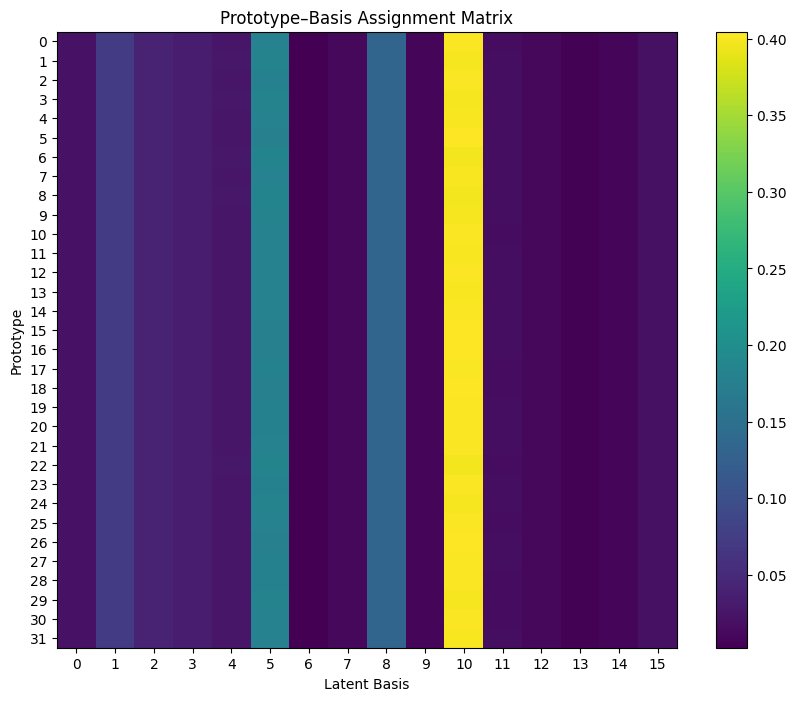

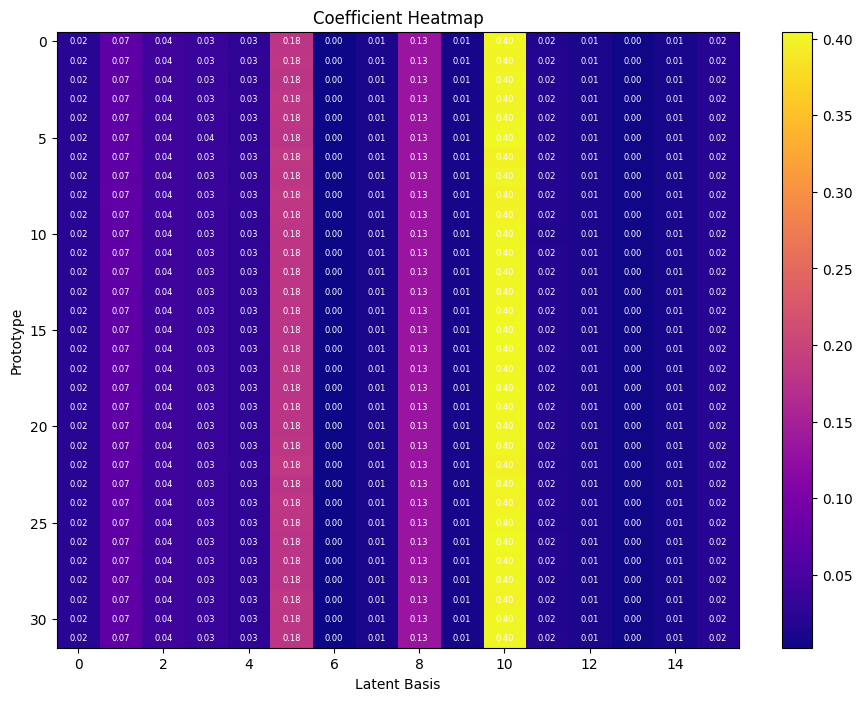

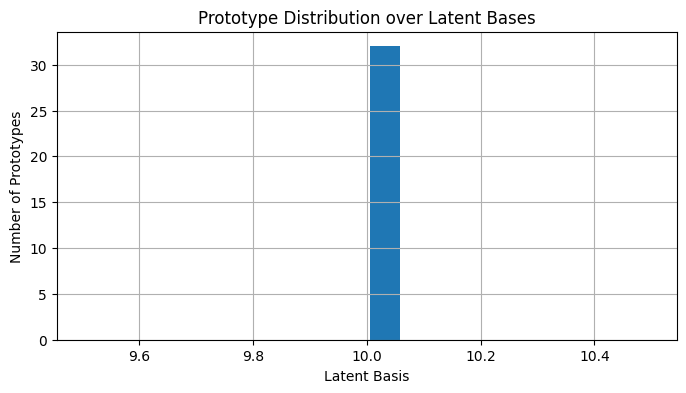

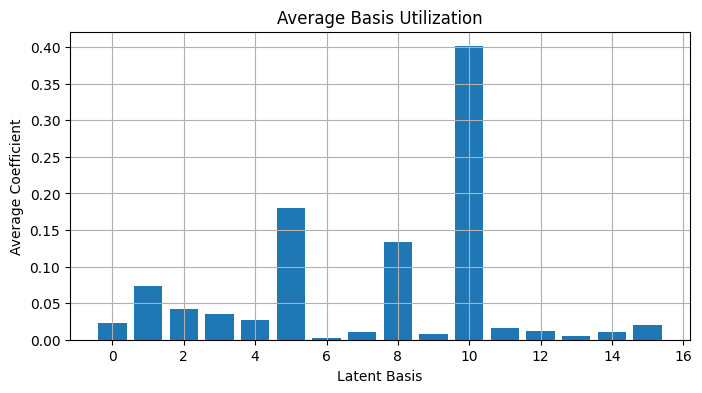



Top-3 Latent Bases for Each Prototype

Prototype 01
  Rank 1: Basis 11   (0.4017)
  Rank 2: Basis 06   (0.1805)
  Rank 3: Basis 09   (0.1337)

Prototype 02
  Rank 1: Basis 11   (0.3989)
  Rank 2: Basis 06   (0.1825)
  Rank 3: Basis 09   (0.1339)

Prototype 03
  Rank 1: Basis 11   (0.4027)
  Rank 2: Basis 06   (0.1791)
  Rank 3: Basis 09   (0.1335)

Prototype 04
  Rank 1: Basis 11   (0.3988)
  Rank 2: Basis 06   (0.1829)
  Rank 3: Basis 09   (0.1339)

Prototype 05
  Rank 1: Basis 11   (0.4012)
  Rank 2: Basis 06   (0.1803)
  Rank 3: Basis 09   (0.1338)

Prototype 06
  Rank 1: Basis 11   (0.4031)
  Rank 2: Basis 06   (0.1778)
  Rank 3: Basis 09   (0.1336)

Prototype 07
  Rank 1: Basis 11   (0.3974)
  Rank 2: Basis 06   (0.1843)
  Rank 3: Basis 09   (0.1336)

Prototype 08
  Rank 1: Basis 11   (0.4007)
  Rank 2: Basis 06   (0.1809)
  Rank 3: Basis 09   (0.1336)

Prototype 09
  Rank 1: Basis 11   (0.3980)
  Rank 2: Basis 06   (0.1835)
  Rank 3: Basis 09   (0.1337)

Prototype 10
  Rank 1: 

In [27]:
# ================================================================
# PALT
# Cell 6.6d.2a : Prototype–Basis Assignment Visualization
# ================================================================

import torch
import matplotlib.pyplot as plt

# ================================================================
# Evaluation
# ================================================================

alsbl.eval()

with torch.no_grad():

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha

    ) = alsbl(normalized_memory)

# ================================================================
# Use First Image in Batch
# ================================================================

coef = coefficients[0].cpu()

# Shape
# (32,16)

# ================================================================
# Dominant Basis
# ================================================================

dominant_basis = torch.argmax(

    coef,

    dim=1

)

print("="*70)
print("Prototype → Dominant Latent Basis")
print("="*70)

for i,b in enumerate(dominant_basis):

    print(

        f"Prototype {i+1:02d}  -->  Basis {b.item()+1:02d}"

    )

# ================================================================
# Prototype–Basis Assignment Matrix
# ================================================================

plt.figure(figsize=(10,8))

plt.imshow(

    coef,

    aspect='auto',

    interpolation='nearest',

    cmap='viridis'

)

plt.colorbar()

plt.xlabel("Latent Basis")

plt.ylabel("Prototype")

plt.title("Prototype–Basis Assignment Matrix")

plt.xticks(range(alsbl.latent_bases))

plt.yticks(range(cfg.MEMORY_SIZE))

plt.show()

# ================================================================
# Heatmap with Values
# ================================================================

plt.figure(figsize=(11,8))

plt.imshow(

    coef,

    cmap='plasma',

    aspect='auto'

)

plt.colorbar()

for i in range(cfg.MEMORY_SIZE):

    for j in range(alsbl.latent_bases):

        plt.text(

            j,

            i,

            f"{coef[i,j]:.2f}",

            ha='center',

            va='center',

            fontsize=6,

            color='white'

        )

plt.title("Coefficient Heatmap")

plt.xlabel("Latent Basis")

plt.ylabel("Prototype")

plt.show()

# ================================================================
# Dominant Basis Histogram
# ================================================================

plt.figure(figsize=(8,4))

plt.hist(

    dominant_basis.numpy(),

    bins=alsbl.latent_bases,

    rwidth=0.85

)

plt.xlabel("Latent Basis")

plt.ylabel("Number of Prototypes")

plt.title("Prototype Distribution over Latent Bases")

plt.grid(True)

plt.show()

# ================================================================
# Mean Basis Usage
# ================================================================

mean_usage = coef.mean(dim=0)

plt.figure(figsize=(8,4))

plt.bar(

    range(alsbl.latent_bases),

    mean_usage

)

plt.xlabel("Latent Basis")

plt.ylabel("Average Coefficient")

plt.title("Average Basis Utilization")

plt.grid(True)

plt.show()

# ================================================================
# Top-3 Bases Per Prototype
# ================================================================

top_values, top_indices = torch.topk(

    coef,

    k=3,

    dim=1

)

print("\n")
print("="*70)
print("Top-3 Latent Bases for Each Prototype")
print("="*70)

for p in range(cfg.MEMORY_SIZE):

    print(f"\nPrototype {p+1:02d}")

    for rank in range(3):

        basis = top_indices[p,rank].item()+1
        value = top_values[p,rank].item()

        print(

            f"  Rank {rank+1}: Basis {basis:02d}   ({value:.4f})"

        )

print("\nPrototype–Basis Assignment Visualization Completed Successfully ✅")

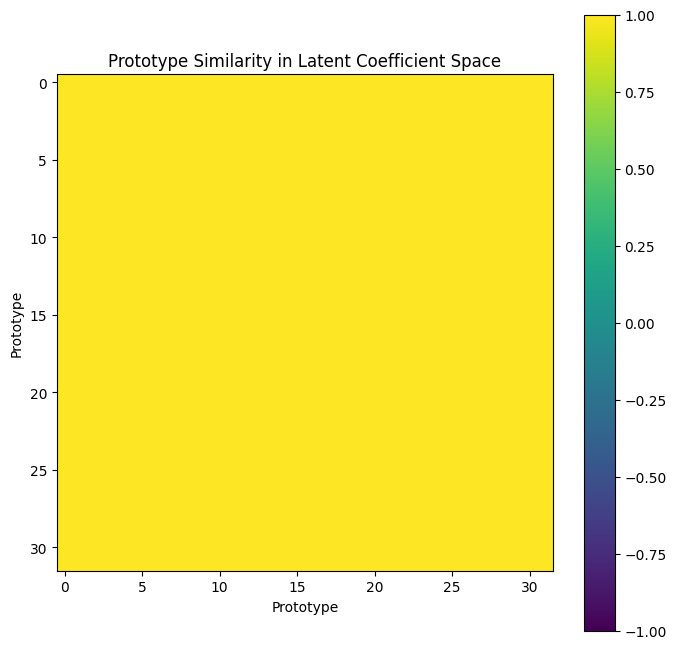

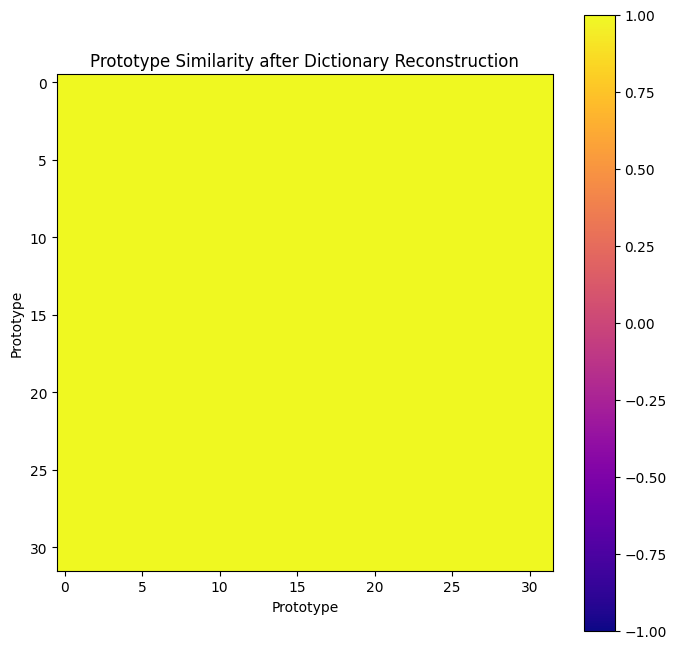

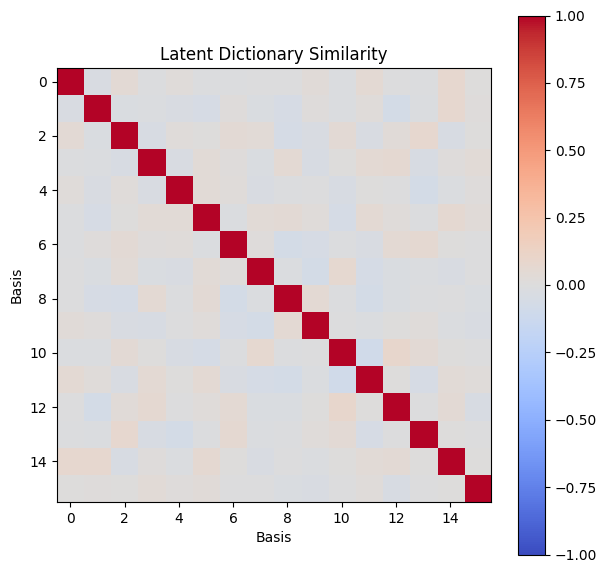

Dictionary Diversity
BDR Error : 0.001279

Average Off-diagonal Similarity
0.02801593206822872

Average Prototype Similarity
0.9687199592590332


Top Prototype Similarities
Prototype 04 <-> Prototype 10 : 1.0000
Prototype 08 <-> Prototype 14 : 1.0000
Prototype 01 <-> Prototype 26 : 1.0000
Prototype 18 <-> Prototype 29 : 1.0000
Prototype 11 <-> Prototype 14 : 1.0000
Prototype 15 <-> Prototype 31 : 1.0000
Prototype 13 <-> Prototype 15 : 1.0000
Prototype 13 <-> Prototype 22 : 1.0000
Prototype 10 <-> Prototype 30 : 1.0000
Prototype 03 <-> Prototype 21 : 1.0000

Dictionary & Prototype Similarity Analysis Completed Successfully ✅


In [28]:
# ================================================================
# PALT
# Cell 6.6d.2b : Dictionary & Prototype Similarity Analysis
# ================================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ================================================================
# Evaluation
# ================================================================

alsbl.eval()

with torch.no_grad():

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha

    ) = alsbl(normalized_memory)

# ================================================================
# First Image
# ================================================================

coef = coefficients[0]

reconstruction = reconstructed_basis[0]

# ================================================================
# Coefficient Similarity
# ================================================================

coef_norm = F.normalize(

    coef,

    p=2,

    dim=-1

)

coef_similarity = torch.matmul(

    coef_norm,

    coef_norm.t()

)

# ================================================================
# Reconstruction Similarity
# ================================================================

reconstruction_norm = F.normalize(

    reconstruction,

    p=2,

    dim=-1

)

prototype_similarity = torch.matmul(

    reconstruction_norm,

    reconstruction_norm.t()

)

# ================================================================
# Dictionary Similarity
# ================================================================

dictionary_norm = F.normalize(

    dictionary,

    p=2,

    dim=-1

)

dictionary_similarity = torch.matmul(

    dictionary_norm,

    dictionary_norm.t()

)

# ================================================================
# Coefficient Similarity Matrix
# ================================================================

plt.figure(figsize=(8,8))

plt.imshow(

    coef_similarity.cpu().detach(),

    cmap="viridis",

    vmin=-1,

    vmax=1

)

plt.colorbar()

plt.title(

    "Prototype Similarity in Latent Coefficient Space"

)

plt.xlabel("Prototype")

plt.ylabel("Prototype")

plt.show()

# ================================================================
# Prototype Similarity
# ================================================================

plt.figure(figsize=(8,8))

plt.imshow(

    prototype_similarity.cpu().detach(),

    cmap="plasma",

    vmin=-1,

    vmax=1

)

plt.colorbar()

plt.title(

    "Prototype Similarity after Dictionary Reconstruction"

)

plt.xlabel("Prototype")

plt.ylabel("Prototype")

plt.show()

# ================================================================
# Dictionary Similarity
# ================================================================

plt.figure(figsize=(7,7))

plt.imshow(

    dictionary_similarity.cpu().detach(),

    cmap="coolwarm",

    vmin=-1,

    vmax=1

)

plt.colorbar()

plt.title(

    "Latent Dictionary Similarity"

)

plt.xlabel("Basis")

plt.ylabel("Basis")

plt.show()

# ================================================================
# Dictionary Diversity
# ================================================================

identity = torch.eye(

    dictionary.shape[0],

    device=dictionary.device

)

diversity_error = torch.mean(

    (dictionary_similarity - identity)**2

)

print("="*70)
print("Dictionary Diversity")
print("="*70)

print(f"BDR Error : {diversity_error.item():.6f}")

# ================================================================
# Off-diagonal Similarity
# ================================================================

off_diag = dictionary_similarity.clone()

off_diag.fill_diagonal_(0)

print()

print("Average Off-diagonal Similarity")

print(off_diag.abs().mean().item())

# ================================================================
# Prototype Diversity
# ================================================================

proto_off = prototype_similarity.clone()

proto_off.fill_diagonal_(0)

print()

print("Average Prototype Similarity")

print(proto_off.abs().mean().item())

# ================================================================
# Top Similar Prototype Pairs
# ================================================================

upper = torch.triu(

    prototype_similarity,

    diagonal=1

)

values, indices = torch.topk(

    upper.flatten(),

    k=10

)

print("\n")
print("="*70)
print("Top Prototype Similarities")
print("="*70)

N = prototype_similarity.shape[0]

for value, idx in zip(values, indices):

    i = idx // N

    j = idx % N

    print(

        f"Prototype {i.item()+1:02d} <-> Prototype {j.item()+1:02d}"

        f" : {value.item():.4f}"

    )

print("\nDictionary & Prototype Similarity Analysis Completed Successfully ✅")

Adaptive Latent Spectral Basis Learning
Final Diagnostics

Memory Update Statistics
------------------------------------------------------------
Minimum : 13.35928726196289
Maximum : 13.364782333374023
Mean    : 13.361103057861328
Std     : 0.0015353605849668384

Reconstruction Error
------------------------------------------------------------
Minimum : 0.2681049704551697
Maximum : 0.2708330750465393
Mean    : 0.2689768671989441
Std     : 0.0006221994408406317

Dictionary Norm
------------------------------------------------------------
Minimum : 1.35186767578125
Maximum : 1.4427409172058105
Mean    : 1.3950436115264893
Std     : 0.024832800030708313

Active Bases
------------------------------------------------------------
Minimum : 4.0
Maximum : 9.0
Mean    : 6.515625

Residual Mixing
------------------------------------------------------------
Alpha : 0.5

Refined Memory
------------------------------------------------------------
Minimum : -3.489609479904175
Maximum : 3.33852815628

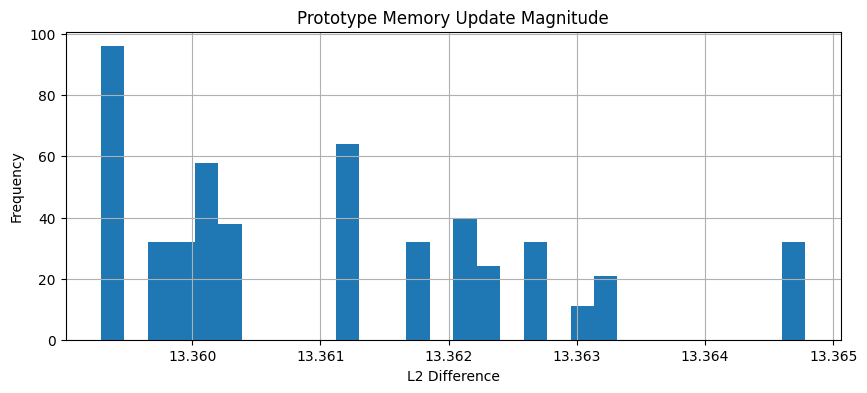

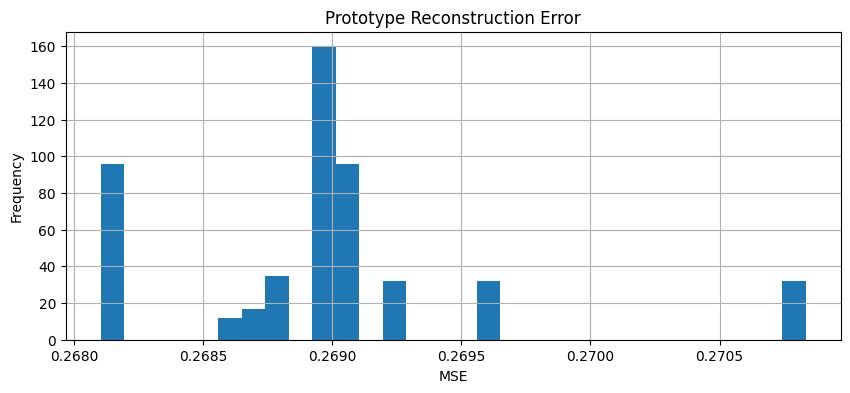

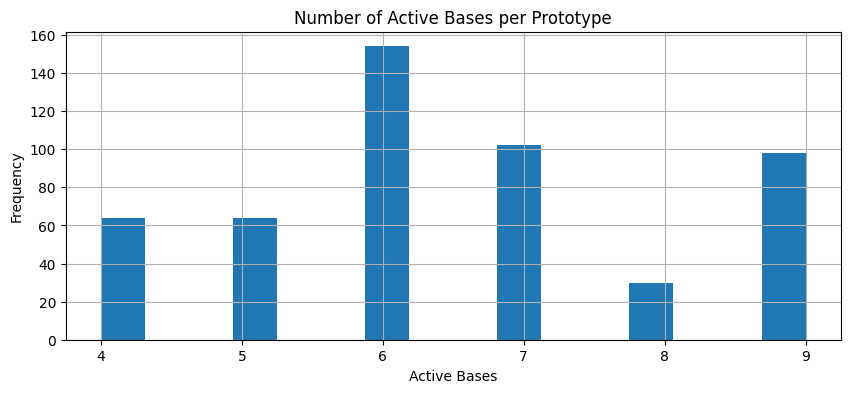

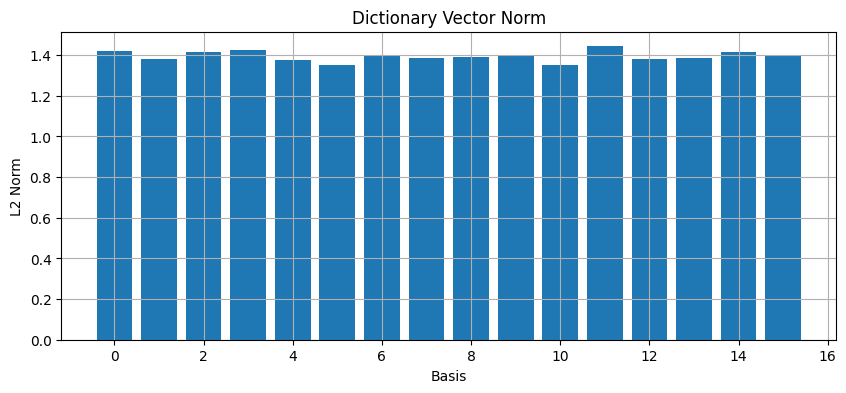


Parameter Summary
------------------------------------------------------------
Total Parameters     : 215,313
Trainable Parameters : 215,313

GPU Memory
------------------------------------------------------------
Allocated : 147.03 MB
Reserved  : 212.00 MB

A-LSBL Fully Verified Successfully ✅


In [29]:
# ================================================================
# PALT
# Cell 6.6d.2c : Final A-LSBL Diagnostics
# ================================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("="*70)
print("Adaptive Latent Spectral Basis Learning")
print("Final Diagnostics")
print("="*70)

# ================================================================
# Forward
# ================================================================

alsbl.eval()

with torch.no_grad():

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha

    ) = alsbl(normalized_memory)

# ================================================================
# Memory Difference
# ================================================================

difference = torch.norm(

    refined_memory -

    normalized_memory,

    dim=-1

)

print("\nMemory Update Statistics")
print("-"*60)

print("Minimum :", difference.min().item())

print("Maximum :", difference.max().item())

print("Mean    :", difference.mean().item())

print("Std     :", difference.std().item())

# ================================================================
# Reconstruction Quality
# ================================================================

reconstruction_error = torch.mean(

    (normalized_memory -

     reconstructed_basis)**2,

    dim=-1

)

print("\nReconstruction Error")
print("-"*60)

print("Minimum :", reconstruction_error.min().item())

print("Maximum :", reconstruction_error.max().item())

print("Mean    :", reconstruction_error.mean().item())

print("Std     :", reconstruction_error.std().item())

# ================================================================
# Dictionary Norm
# ================================================================

dictionary_norm = torch.norm(

    dictionary,

    dim=-1

)

print("\nDictionary Norm")

print("-"*60)

print("Minimum :", dictionary_norm.min().item())

print("Maximum :", dictionary_norm.max().item())

print("Mean    :", dictionary_norm.mean().item())

print("Std     :", dictionary_norm.std().item())

# ================================================================
# Coefficient Sparsity
# ================================================================

threshold = 0.05

active = (

    coefficients >

    threshold

).float()

active_per_proto = active.sum(dim=-1)

print("\nActive Bases")

print("-"*60)

print("Minimum :", active_per_proto.min().item())

print("Maximum :", active_per_proto.max().item())

print("Mean    :", active_per_proto.mean().item())

# ================================================================
# Residual Mixing
# ================================================================

print("\nResidual Mixing")

print("-"*60)

print("Alpha :", alpha.item())

# ================================================================
# Memory Statistics
# ================================================================

print("\nRefined Memory")

print("-"*60)

print("Minimum :", refined_memory.min().item())

print("Maximum :", refined_memory.max().item())

print("Mean    :", refined_memory.mean().item())

print("Std     :", refined_memory.std().item())

# ================================================================
# Dynamic Range
# ================================================================

dynamic_range = (

    refined_memory.max()

    -

    refined_memory.min()

)

print("\nDynamic Range")

print("-"*60)

print(dynamic_range.item())

# ================================================================
# NaN / Inf
# ================================================================

print("\nNaN / Inf")

print("-"*60)

print("Memory NaN :", torch.isnan(refined_memory).sum().item())

print("Memory Inf :", torch.isinf(refined_memory).sum().item())

print("Coeff NaN  :", torch.isnan(coefficients).sum().item())

print("Coeff Inf  :", torch.isinf(coefficients).sum().item())

assert not torch.isnan(refined_memory).any()

assert not torch.isinf(refined_memory).any()

assert not torch.isnan(coefficients).any()

assert not torch.isinf(coefficients).any()

print("\nNumerical Stability Passed ✓")

# ================================================================
# Visualization
# ================================================================

plt.figure(figsize=(10,4))

plt.hist(

    difference.cpu().view(-1),

    bins=30

)

plt.title("Prototype Memory Update Magnitude")

plt.xlabel("L2 Difference")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

# ================================================================
# Reconstruction Error Histogram
# ================================================================

plt.figure(figsize=(10,4))

plt.hist(

    reconstruction_error.cpu().view(-1),

    bins=30

)

plt.title("Prototype Reconstruction Error")

plt.xlabel("MSE")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

# ================================================================
# Active Basis Distribution
# ================================================================

plt.figure(figsize=(10,4))

plt.hist(

    active_per_proto.cpu().view(-1),

    bins=16

)

plt.title("Number of Active Bases per Prototype")

plt.xlabel("Active Bases")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

# ================================================================
# Dictionary Norm
# ================================================================

plt.figure(figsize=(10,4))

plt.bar(

    range(dictionary.shape[0]),

    dictionary_norm.cpu().detach() # Added .detach() here

)

plt.title("Dictionary Vector Norm")

plt.xlabel("Basis")

plt.ylabel("L2 Norm")

plt.grid(True)

plt.show()

# ================================================================
# Parameter Summary
# ================================================================

total = sum(

    p.numel()

    for p in alsbl.parameters()

)

trainable = sum(

    p.numel()

    for p in alsbl.parameters()

    if p.requires_grad

)

print("\nParameter Summary")

print("-"*60)

print(f"Total Parameters     : {total:,}")

print(f"Trainable Parameters : {trainable:,}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    print("\nGPU Memory")

    print("-"*60)

    allocated = torch.cuda.memory_allocated()/1024**2

    reserved = torch.cuda.memory_reserved()/1024**2

    print(f"Allocated : {allocated:.2f} MB")

    print(f"Reserved  : {reserved:.2f} MB")

print("\nA-LSBL Fully Verified Successfully ✅")

In [30]:
# ================================================================
# PALT
# Cell 7.1 : Dual Memory Interface (DMI)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Dual Memory Interface
# ================================================================

class DualMemoryInterface(nn.Module):
    """
    Inputs
    ------
    semantic_memory
        (B,K,D)

    spectral_memory
        (B,K,D)

    Outputs
    -------
    fused_memory
        (B,K,D)

    gate
        (B,K,D)
    """

    def __init__(
        self,
        embed_dim=768,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim

        # --------------------------------------------------------
        # Memory Fusion Gate
        # --------------------------------------------------------

        self.gate_network = nn.Sequential(

            nn.Linear(
                embed_dim * 2,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                embed_dim
            )

        )

        self.output_norm = nn.LayerNorm(embed_dim)

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(

        self,

        semantic_memory,

        spectral_memory

    ):

        x = torch.cat(

            [

                semantic_memory,

                spectral_memory

            ],

            dim=-1

        )

        gate = torch.sigmoid(

            self.gate_network(x)

        )

        fused_memory = (

            gate *

            semantic_memory +

            (1.0-gate) *

            spectral_memory

        )

        fused_memory = self.output_norm(

            fused_memory

        )

        return (

            fused_memory,

            gate

        )

# ================================================================
# Instantiate
# ================================================================

dmi = DualMemoryInterface(

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Dual Memory Interface")
print("="*70)

print(dmi)

total = sum(
    p.numel()
    for p in dmi.parameters()
)

trainable = sum(
    p.numel()
    for p in dmi.parameters()
    if p.requires_grad
)

print("\nTotal Parameters :", format(total,","))

print("Trainable        :", format(trainable,","))

print("\nDual Memory Interface Ready ✅")

# ================================================================
# Forward Test
# ================================================================

dmi.eval()

with torch.no_grad():

    fused_memory, fusion_gate = dmi(

        refined_memory,

        reconstructed_basis

    )

print("\n")
print("="*70)
print("Dual Memory Interface Verification")
print("="*70)

print("Semantic Memory :", refined_memory.shape)
print("Spectral Memory :", reconstructed_basis.shape)
print("Fused Memory    :", fused_memory.shape)
print("Fusion Gate     :", fusion_gate.shape)

assert fused_memory.shape == refined_memory.shape
assert fusion_gate.shape == refined_memory.shape

print("\nGate Statistics")
print("-"*60)

print("Minimum :", fusion_gate.min().item())
print("Maximum :", fusion_gate.max().item())
print("Mean    :", fusion_gate.mean().item())
print("Std     :", fusion_gate.std().item())

print("\nFused Memory Statistics")
print("-"*60)

print("Minimum :", fused_memory.min().item())
print("Maximum :", fused_memory.max().item())
print("Mean    :", fused_memory.mean().item())
print("Std     :", fused_memory.std().item())

assert not torch.isnan(fused_memory).any()
assert not torch.isinf(fused_memory).any()

assert not torch.isnan(fusion_gate).any()
assert not torch.isinf(fusion_gate).any()

print("\nDual Memory Interface Verified Successfully ✅")

Dual Memory Interface
DualMemoryInterface(
  (gate_network): Sequential(
    (0): Linear(in_features=1536, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=768, bias=True)
  )
  (output_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

Total Parameters : 592,896
Trainable        : 592,896

Dual Memory Interface Ready ✅


Dual Memory Interface Verification
Semantic Memory : torch.Size([16, 32, 768])
Spectral Memory : torch.Size([16, 32, 768])
Fused Memory    : torch.Size([16, 32, 768])
Fusion Gate     : torch.Size([16, 32, 768])

Gate Statistics
------------------------------------------------------------
Minimum : 0.07072486728429794
Maximum : 0.9468511343002319
Mean    : 0.5002257227897644
Std     : 0.1593894213438034

Fused Memory Statistics
------------------------------------------------------------
Minimum :

In [31]:
# ================================================================
# PALT
# Cell 7.2 : Hierarchical Memory-to-Token Cross Attention (HMCA)
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# HMCA
# ================================================================

class HierarchicalMemoryCrossAttention(nn.Module):

    """
    Inputs
    ------
    tokens           : (B,N,D)

    semantic_memory  : (B,K,D)

    spectral_memory  : (B,K,D)

    fused_memory     : (B,K,D)

    Outputs
    -------
    output_tokens    : (B,N,D)

    attention_maps   : dict
    """

    def __init__(
        self,
        embed_dim=768,
        num_heads=12,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        assert embed_dim % num_heads == 0

        # --------------------------------------------------------
        # Shared projections
        # --------------------------------------------------------

        self.q_proj = nn.Linear(embed_dim, embed_dim)

        self.k_proj = nn.Linear(embed_dim, embed_dim)

        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.out_proj = nn.Linear(embed_dim, embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

        # --------------------------------------------------------
        # Adaptive fusion weights
        # --------------------------------------------------------

        self.fusion_logits = nn.Parameter(
            torch.zeros(3)
        )

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def attention(
        self,
        query,
        memory
    ):

        B,N,D = query.shape
        K = memory.shape[1]

        Q = self.q_proj(query)
        K_mat = self.k_proj(memory)
        V_mat = self.v_proj(memory)

        Q = Q.view(
            B,N,self.num_heads,self.head_dim
        ).transpose(1,2)

        K_mat = K_mat.view(
            B,K,self.num_heads,self.head_dim
        ).transpose(1,2)

        V_mat = V_mat.view(
            B,K,self.num_heads,self.head_dim
        ).transpose(1,2)

        score = torch.matmul(
            Q,
            K_mat.transpose(-2,-1)
        )

        score = score / math.sqrt(self.head_dim)

        attn = F.softmax(
            score,
            dim=-1
        )

        attn = self.dropout(attn)

        output = torch.matmul(
            attn,
            V_mat
        )

        output = output.transpose(1,2).contiguous()

        output = output.view(
            B,
            N,
            D
        )

        output = self.out_proj(output)

        return output, attn

    # ------------------------------------------------------------

    def forward(

        self,

        tokens,

        semantic_memory,

        spectral_memory,

        fused_memory

    ):

        # --------------------------------------------------------
        # Stage 1
        # --------------------------------------------------------

        Hf, Af = self.attention(
            tokens,
            fused_memory
        )

        # --------------------------------------------------------
        # Stage 2
        # --------------------------------------------------------

        Hs, As = self.attention(
            Hf,
            semantic_memory
        )

        # --------------------------------------------------------
        # Stage 3
        # --------------------------------------------------------

        Hb, Ab = self.attention(
            Hs,
            spectral_memory
        )

        # --------------------------------------------------------
        # Adaptive Fusion
        # --------------------------------------------------------

        w = F.softmax(
            self.fusion_logits,
            dim=0
        )

        output = (

            w[0] * Hf +

            w[1] * Hs +

            w[2] * Hb

        )

        output = self.norm(

            tokens +

            output

        )

        return (

            output,

            {

                "fused":Af,

                "semantic":As,

                "spectral":Ab,

                "fusion_weights":w

            }

        )


# ================================================================
# Instantiate
# ================================================================

hmca = HierarchicalMemoryCrossAttention(

    embed_dim=cfg.EMBED_DIM,

    num_heads=12,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Hierarchical Memory-to-Token Cross Attention")
print("="*70)

print(hmca)

total = sum(p.numel() for p in hmca.parameters())
trainable = sum(p.numel() for p in hmca.parameters() if p.requires_grad)

print(f"\nTotal Parameters     : {total:,}")
print(f"Trainable Parameters : {trainable:,}")

# ================================================================
# Forward Test
# ================================================================

hmca.eval()

with torch.no_grad():

    output_tokens, attention_info = hmca(

        tokens=tokens,

        semantic_memory=refined_memory,

        spectral_memory=reconstructed_basis,

        fused_memory=fused_memory

    )

print("\n")
print("="*70)
print("HMCA Verification")
print("="*70)

print("Input Tokens :", tokens.shape)
print("Output Tokens:", output_tokens.shape)

print("\nAttention Maps")
print("Fused     :", attention_info["fused"].shape)
print("Semantic  :", attention_info["semantic"].shape)
print("Spectral  :", attention_info["spectral"].shape)

print("\nFusion Weights")
print(attention_info["fusion_weights"])

assert output_tokens.shape == tokens.shape

assert not torch.isnan(output_tokens).any()
assert not torch.isinf(output_tokens).any()

print("\nHMCA Verified Successfully ✅")

Hierarchical Memory-to-Token Cross Attention
HierarchicalMemoryCrossAttention(
  (q_proj): Linear(in_features=768, out_features=768, bias=True)
  (k_proj): Linear(in_features=768, out_features=768, bias=True)
  (v_proj): Linear(in_features=768, out_features=768, bias=True)
  (out_proj): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

Total Parameters     : 2,363,907
Trainable Parameters : 2,363,907


HMCA Verification
Input Tokens : torch.Size([16, 197, 768])
Output Tokens: torch.Size([16, 197, 768])

Attention Maps
Fused     : torch.Size([16, 12, 197, 32])
Semantic  : torch.Size([16, 12, 197, 32])
Spectral  : torch.Size([16, 12, 197, 32])

Fusion Weights
tensor([0.3333, 0.3333, 0.3333], device='cuda:0')

HMCA Verified Successfully ✅


In [32]:
# ================================================================
# PALT
# Cell 7.3 : Prototype-Conditioned Liquid Gated State Transition
# (PC-LGST)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype-Conditioned LGST
# ================================================================

class PrototypeConditionedLGST(nn.Module):

    """
    Inputs
    ------
    token_features     : (B,N,D)

    prototype_context  : (B,N,D)

    Outputs
    -------
    output_tokens      : (B,N,D)

    liquid_state       : (B,N,D)

    diagnostics        : dict
    """

    def __init__(
        self,
        embed_dim=768,
        hidden_dim=768,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim

        # --------------------------------------------------------
        # Token + Prototype Fusion
        # --------------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(embed_dim * 2, hidden_dim),

            nn.GELU(),

            nn.LayerNorm(hidden_dim)

        )

        # --------------------------------------------------------
        # Gates
        # --------------------------------------------------------

        self.update_gate = nn.Linear(hidden_dim, embed_dim)

        self.retention_gate = nn.Linear(hidden_dim, embed_dim)

        self.tau_head = nn.Linear(hidden_dim, embed_dim)

        self.beta_head = nn.Linear(hidden_dim, embed_dim)

        self.delta_head = nn.Linear(hidden_dim, embed_dim)

        self.output_proj = nn.Linear(hidden_dim, embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(

        self,

        token_features,

        prototype_context

    ):

        # ========================================================
        # Joint State
        # ========================================================

        joint = torch.cat(

            [

                token_features,

                prototype_context

            ],

            dim=-1

        )

        H = self.fusion(joint)

        # ========================================================
        # Gates
        # ========================================================

        G_u = torch.sigmoid(

            self.update_gate(H)

        )

        G_r = torch.sigmoid(

            self.retention_gate(H)

        )

        tau = F.softplus(

            self.tau_head(H)

        ) + 1e-4

        beta = torch.sigmoid(

            self.beta_head(H)

        )

        delta = torch.tanh(

            self.delta_head(H)

        )

        # ========================================================
        # Stable Liquid Dynamics
        # ========================================================

        alpha = torch.exp(

            -1.0 / tau

        )

        liquid = (

            alpha * H +

            (1.0 - alpha) *

            beta *

            delta

        )

        # ========================================================
        # Update Gate
        # ========================================================

        liquid = (

            G_u * liquid +

            (1.0 - G_u) * H

        )

        # ========================================================
        # Retention Gate
        # ========================================================

        liquid = (

            G_r * H +

            (1.0 - G_r) * liquid

        )

        liquid = self.dropout(liquid)

        output = self.output_proj(liquid)

        output = self.norm(

            token_features +

            output

        )

        diagnostics = {

            "update_gate": G_u,

            "retention_gate": G_r,

            "tau": tau,

            "beta": beta,

            "alpha": alpha

        }

        return output, liquid, diagnostics


# ================================================================
# Instantiate
# ================================================================

lgst = PrototypeConditionedLGST(

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=cfg.EMBED_DIM,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("=" * 70)
print("Prototype-Conditioned LGST")
print("=" * 70)

total = sum(p.numel() for p in lgst.parameters())
trainable = sum(
    p.numel() for p in lgst.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total:,}")
print(f"Trainable Parameters : {trainable:,}")

# ================================================================
# Quick Verification
# ================================================================

lgst.eval()

with torch.no_grad():

    # HMCA output tokens
    token_input = output_tokens

    # Prototype context:
    # use fused memory aggregated over prototypes
    prototype_context = fused_memory.mean(
        dim=1,
        keepdim=True
    ).expand(
        -1,
        token_input.shape[1],
        -1
    )

    token_output, liquid_state, info = lgst(

        token_input,

        prototype_context

    )

print("\n")
print("=" * 70)
print("PC-LGST Verification")
print("=" * 70)

print("Input Tokens   :", token_input.shape)
print("Prototype Ctx  :", prototype_context.shape)
print("Output Tokens  :", token_output.shape)
print("Liquid State   :", liquid_state.shape)

print("\nUpdate Gate :", info["update_gate"].shape)
print("Retention   :", info["retention_gate"].shape)
print("Tau         :", info["tau"].shape)
print("Beta        :", info["beta"].shape)

assert token_output.shape == token_input.shape
assert liquid_state.shape == token_input.shape

assert not torch.isnan(token_output).any()
assert not torch.isinf(token_output).any()

print("\nPC-LGST Verified Successfully ✅")

Prototype-Conditioned LGST
Total Parameters     : 4,727,040
Trainable Parameters : 4,727,040


PC-LGST Verification
Input Tokens   : torch.Size([16, 197, 768])
Prototype Ctx  : torch.Size([16, 197, 768])
Output Tokens  : torch.Size([16, 197, 768])
Liquid State   : torch.Size([16, 197, 768])

Update Gate : torch.Size([16, 197, 768])
Retention   : torch.Size([16, 197, 768])
Tau         : torch.Size([16, 197, 768])
Beta        : torch.Size([16, 197, 768])

PC-LGST Verified Successfully ✅


In [33]:
# ================================================================
# PALT
# Cell 7.4a : Attention-guided Memory Feedback Refinement (AMFR)
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Attention-guided Memory Feedback Refinement
# ================================================================

class AttentionMemoryFeedbackRefinement(nn.Module):

    """
    Inputs
    ------
    prototype_memory : (B,K,D)

    token_features   : (B,N,D)

    Outputs
    -------
    updated_memory   : (B,K,D)

    attention_map    : (B,H,K,N)

    feedback_gate    : (B,K,D)
    """

    def __init__(
        self,
        embed_dim=768,
        num_heads=12,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        assert embed_dim % num_heads == 0

        # --------------------------------------------------------
        # Multi-head projections
        # --------------------------------------------------------

        self.query = nn.Linear(embed_dim, embed_dim)
        self.key   = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)

        self.output = nn.Linear(embed_dim, embed_dim)

        # --------------------------------------------------------
        # Feedback Gate
        # --------------------------------------------------------

        self.feedback_gate = nn.Sequential(

            nn.Linear(
                embed_dim * 2,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Linear(
                hidden_dim,
                embed_dim
            )

        )

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

        self.initialize()

    # ------------------------------------------------------------

    def initialize(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ------------------------------------------------------------

    def forward(

        self,

        prototype_memory,

        token_features

    ):

        B,K,D = prototype_memory.shape
        N = token_features.shape[1]

        # --------------------------------------------------------
        # Multi-head projections
        # --------------------------------------------------------

        Q = self.query(prototype_memory)
        Kt = self.key(token_features)
        V = self.value(token_features)

        Q = Q.view(
            B,K,self.num_heads,self.head_dim
        ).transpose(1,2)

        Kt = Kt.view(
            B,N,self.num_heads,self.head_dim
        ).transpose(1,2)

        V = V.view(
            B,N,self.num_heads,self.head_dim
        ).transpose(1,2)

        # --------------------------------------------------------
        # Prototype → Token Attention
        # --------------------------------------------------------

        attention = torch.matmul(
            Q,
            Kt.transpose(-2,-1)
        )

        attention = attention / math.sqrt(self.head_dim)

        attention = F.softmax(
            attention,
            dim=-1
        )

        attention = self.dropout(attention)

        # --------------------------------------------------------
        # Feedback
        # --------------------------------------------------------

        feedback = torch.matmul(
            attention,
            V
        )

        feedback = feedback.transpose(1,2).contiguous()

        feedback = feedback.view(
            B,
            K,
            D
        )

        feedback = self.output(feedback)

        # --------------------------------------------------------
        # Adaptive Feedback Gate
        # --------------------------------------------------------

        gate_input = torch.cat(

            [

                prototype_memory,

                feedback

            ],

            dim=-1

        )

        gate = torch.sigmoid(

            self.feedback_gate(

                gate_input

            )

        )

        # --------------------------------------------------------
        # Prototype Update
        # --------------------------------------------------------

        updated_memory = (

            prototype_memory +

            gate * feedback

        )

        updated_memory = self.norm(

            updated_memory

        )

        return (

            updated_memory,

            attention,

            gate

        )


# ================================================================
# Instantiate
# ================================================================

amfr = AttentionMemoryFeedbackRefinement(

    embed_dim=cfg.EMBED_DIM,

    num_heads=12,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Attention-guided Memory Feedback Refinement")
print("="*70)

total = sum(
    p.numel()
    for p in amfr.parameters()
)

trainable = sum(
    p.numel()
    for p in amfr.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total:,}")
print(f"Trainable Parameters : {trainable:,}")

# ================================================================
# Forward Test
# ================================================================

amfr.eval()

with torch.no_grad():

    updated_memory, feedback_attention, feedback_gate = amfr(

        prototype_memory=fused_memory,

        token_features=token_output

    )

print("\n")
print("="*70)
print("AMFR Verification")
print("="*70)

print("Input Prototype Memory :", fused_memory.shape)
print("Token Features         :", token_output.shape)
print("Updated Memory         :", updated_memory.shape)
print("Attention Map          :", feedback_attention.shape)
print("Feedback Gate          :", feedback_gate.shape)

assert updated_memory.shape == fused_memory.shape

assert feedback_attention.shape == (
    cfg.BATCH_SIZE,
    12,
    cfg.MEMORY_SIZE,
    token_output.shape[1]
)

assert feedback_gate.shape == fused_memory.shape

assert not torch.isnan(updated_memory).any()
assert not torch.isinf(updated_memory).any()

print("\nFeedback Gate Statistics")
print("-"*60)
print("Min  :", feedback_gate.min().item())
print("Max  :", feedback_gate.max().item())
print("Mean :", feedback_gate.mean().item())
print("Std  :", feedback_gate.std().item())

print("\nAMFR Ready ✅")

Attention-guided Memory Feedback Refinement
Total Parameters     : 2,955,264
Trainable Parameters : 2,955,264


AMFR Verification
Input Prototype Memory : torch.Size([16, 32, 768])
Token Features         : torch.Size([16, 197, 768])
Updated Memory         : torch.Size([16, 32, 768])
Attention Map          : torch.Size([16, 12, 32, 197])
Feedback Gate          : torch.Size([16, 32, 768])

Feedback Gate Statistics
------------------------------------------------------------
Min  : 0.076691634953022
Max  : 0.9397172927856445
Mean : 0.5049107074737549
Std  : 0.16106191277503967

AMFR Ready ✅


In [34]:
# ================================================================
# PALT
# Cell 7.4.2 : Prototype Residual Injection (PRI)
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Residual Injection (PRI)
# ================================================================

class PrototypeResidualInjection(nn.Module):
    """
    Prototype Residual Injection (PRI)

    Inputs
    ------
    token_features : (B, N, D)
    prototype_memory : (B, K, D)

    Outputs
    -------
    updated_tokens : (B, N, D)

    diagnostics : dict
    """

    def __init__(
        self,
        embed_dim=768,
        num_heads=12,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # --------------------------------------------------------
        # Multi-head projections
        # --------------------------------------------------------

        self.query = nn.Linear(embed_dim, embed_dim)
        self.key   = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)

        self.output_projection = nn.Linear(embed_dim, embed_dim)

        # --------------------------------------------------------
        # Adaptive Injection Gate
        # --------------------------------------------------------

        self.gate = nn.Sequential(

            nn.Linear(
                embed_dim * 2,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Linear(
                hidden_dim,
                embed_dim
            )

        )

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

        self.initialize_weights()

    # ============================================================

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ============================================================

    def forward(

        self,

        token_features,

        prototype_memory

    ):

        B, N, D = token_features.shape
        K = prototype_memory.shape[1]

        # --------------------------------------------------------
        # Linear projections
        # --------------------------------------------------------

        Q = self.query(token_features)
        Kp = self.key(prototype_memory)
        V = self.value(prototype_memory)

        # --------------------------------------------------------
        # Multi-head reshape
        # --------------------------------------------------------

        Q = Q.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        Kp = Kp.view(
            B,
            K,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        V = V.view(
            B,
            K,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        # --------------------------------------------------------
        # Attention
        # --------------------------------------------------------

        attention_scores = torch.matmul(

            Q,

            Kp.transpose(-2,-1)

        )

        attention_scores = attention_scores / math.sqrt(self.head_dim)

        attention = F.softmax(

            attention_scores,

            dim=-1

        )

        attention = self.dropout(attention)

        # --------------------------------------------------------
        # Prototype Injection
        # --------------------------------------------------------

        injected = torch.matmul(

            attention,

            V

        )

        injected = injected.transpose(1,2).contiguous()

        injected = injected.view(

            B,

            N,

            D

        )

        injected = self.output_projection(

            injected

        )

        # --------------------------------------------------------
        # Feature-wise Gate
        # --------------------------------------------------------

        gate_input = torch.cat(

            [

                token_features,

                injected

            ],

            dim=-1

        )

        gate = torch.sigmoid(

            self.gate(

                gate_input

            )

        )

        # --------------------------------------------------------
        # Residual Injection
        # --------------------------------------------------------

        updated_tokens = (

            token_features +

            gate * injected

        )

        updated_tokens = self.dropout(updated_tokens)

        updated_tokens = self.norm(updated_tokens)

        diagnostics = {

            "attention": attention,

            "gate": gate,

            "gate_mean": gate.mean(),

            "gate_std": gate.std()

        }

        return updated_tokens, diagnostics


# ================================================================
# Instantiate
# ================================================================

pri = PrototypeResidualInjection(

    embed_dim=cfg.EMBED_DIM,

    num_heads=12,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Prototype Residual Injection (PRI)")
print("="*70)

total_params = sum(

    p.numel()

    for p in pri.parameters()

)

trainable_params = sum(

    p.numel()

    for p in pri.parameters()

    if p.requires_grad

)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# Forward Verification
# ================================================================

pri.eval()

with torch.no_grad():

    pri_tokens, pri_info = pri(

        token_features=token_output,

        prototype_memory=updated_memory

    )

print("\n")
print("="*70)
print("PRI Verification")
print("="*70)

print("Input Tokens      :", token_output.shape)
print("Prototype Memory  :", updated_memory.shape)
print("Output Tokens     :", pri_tokens.shape)

print("\nAttention Shape")
print(pri_info["attention"].shape)

print("\nGate Shape")
print(pri_info["gate"].shape)

print("\nGate Statistics")
print("-"*60)
print("Minimum :", pri_info["gate"].min().item())
print("Maximum :", pri_info["gate"].max().item())
print("Mean    :", pri_info["gate_mean"].item())
print("Std     :", pri_info["gate_std"].item())

print("\nToken Statistics")
print("-"*60)
print("Minimum :", pri_tokens.min().item())
print("Maximum :", pri_tokens.max().item())
print("Mean    :", pri_tokens.mean().item())
print("Std     :", pri_tokens.std().item())

print("\nNaN Check :", torch.isnan(pri_tokens).sum().item())
print("Inf Check :", torch.isinf(pri_tokens).sum().item())

assert pri_tokens.shape == token_output.shape
assert not torch.isnan(pri_tokens).any()
assert not torch.isinf(pri_tokens).any()

print("\nPrototype Residual Injection Verified Successfully ✅")

Prototype Residual Injection (PRI)
Total Parameters     : 2,955,264
Trainable Parameters : 2,955,264


PRI Verification
Input Tokens      : torch.Size([16, 197, 768])
Prototype Memory  : torch.Size([16, 32, 768])
Output Tokens     : torch.Size([16, 197, 768])

Attention Shape
torch.Size([16, 12, 197, 32])

Gate Shape
torch.Size([16, 197, 768])

Gate Statistics
------------------------------------------------------------
Minimum : 0.04534045606851578
Maximum : 0.9496909976005554
Mean    : 0.4968249797821045
Std     : 0.15938565135002136

Token Statistics
------------------------------------------------------------
Minimum : -4.396792411804199
Maximum : 4.45119571685791
Mean    : -3.4038183382989473e-10
Std     : 0.9999962449073792

NaN Check : 0
Inf Check : 0

Prototype Residual Injection Verified Successfully ✅


In [35]:
# ================================================================
# PALT
# Cell 7.4.3 : Complete Adaptive Liquid Transformer Encoder (ALTE)
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Adaptive Liquid Transformer Encoder
# ================================================================

class AdaptiveLiquidTransformerEncoder(nn.Module):
    """
    Adaptive Liquid Transformer Encoder (ALTE)

    Pipeline
    --------
    HMCA
        ↓
    Prototype-Conditioned LGST
        ↓
    Attention-guided Memory Feedback Refinement
        ↓
    Prototype Residual Injection
        ↓
    Residual + LayerNorm

    Inputs
    ------
    tokens            : (B,N,D)
    semantic_memory   : (B,K,D)
    spectral_memory   : (B,K,D)
    fused_memory      : (B,K,D)

    Outputs
    -------
    output_tokens
    updated_memory
    diagnostics
    """

    def __init__(
        self,
        hmca,
        lgst,
        amfr,
        pri,
        embed_dim=768,
        dropout=0.10
    ):

        super().__init__()

        # --------------------------------------------------------
        # Existing Modules
        # --------------------------------------------------------

        self.hmca = hmca
        self.lgst = lgst
        self.amfr = amfr
        self.pri  = pri

        # --------------------------------------------------------
        # Output Layer
        # --------------------------------------------------------

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

    # ============================================================

    def forward(

        self,

        tokens,

        semantic_memory,

        spectral_memory,

        fused_memory

    ):

        diagnostics = {}

        # ========================================================
        # HMCA
        # ========================================================

        hmca_tokens, hmca_info = self.hmca(

            tokens=tokens,

            semantic_memory=semantic_memory,

            spectral_memory=spectral_memory,

            fused_memory=fused_memory

        )

        diagnostics["hmca"] = hmca_info

        # ========================================================
        # Prototype Context
        # ========================================================

        prototype_context = fused_memory.mean(

            dim=1,

            keepdim=True

        ).expand(

            -1,

            hmca_tokens.shape[1],

            -1

        )

        # ========================================================
        # LGST
        # ========================================================

        lgst_tokens, liquid_state, lgst_info = self.lgst(

            hmca_tokens,

            prototype_context

        )

        diagnostics["lgst"] = lgst_info

        # ========================================================
        # AMFR
        # ========================================================

        updated_memory, feedback_attention, feedback_gate = self.amfr(

            prototype_memory=fused_memory,

            token_features=lgst_tokens

        )

        diagnostics["amfr"] = {

            "attention": feedback_attention,

            "gate": feedback_gate

        }

        # ========================================================
        # PRI
        # ========================================================

        output_tokens, pri_info = self.pri(

            token_features=lgst_tokens,

            prototype_memory=updated_memory

        )

        diagnostics["pri"] = pri_info

        # ========================================================
        # Final Residual
        # ========================================================

        output_tokens = self.dropout(output_tokens)

        output_tokens = self.norm(output_tokens)

        return (

            output_tokens,

            updated_memory,

            diagnostics

        )


# ================================================================
# Instantiate ALTE
# ================================================================

alte = AdaptiveLiquidTransformerEncoder(

    hmca=hmca,

    lgst=lgst,

    amfr=amfr,

    pri=pri,

    embed_dim=cfg.EMBED_DIM,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

# ================================================================
# Parameter Summary
# ================================================================

print("="*70)
print("Adaptive Liquid Transformer Encoder")
print("="*70)

total_params = sum(

    p.numel()

    for p in alte.parameters()

)

trainable_params = sum(

    p.numel()

    for p in alte.parameters()

    if p.requires_grad

)

print(f"Total Parameters     : {total_params:,}")

print(f"Trainable Parameters : {trainable_params:,}")

print("\nALTE Created Successfully ✅")

# ================================================================
# Forward Verification
# ================================================================

alte.eval()

with torch.no_grad():

    output_tokens, updated_memory, diagnostics = alte(

        tokens=tokens,

        semantic_memory=refined_memory,

        spectral_memory=reconstructed_basis,

        fused_memory=fused_memory

    )

print("\n")
print("="*70)
print("ALTE Verification")
print("="*70)

print("Input Tokens       :", tokens.shape)
print("Output Tokens      :", output_tokens.shape)
print("Updated Memory     :", updated_memory.shape)

print("\nDiagnostics")

for key in diagnostics.keys():

    print("✓", key)

print("\nOutput Statistics")
print("-"*60)

print("Minimum :", output_tokens.min().item())
print("Maximum :", output_tokens.max().item())
print("Mean    :", output_tokens.mean().item())
print("Std     :", output_tokens.std().item())

print("\nNaN :", torch.isnan(output_tokens).sum().item())
print("Inf :", torch.isinf(output_tokens).sum().item())

assert output_tokens.shape == tokens.shape
assert updated_memory.shape == fused_memory.shape

assert not torch.isnan(output_tokens).any()
assert not torch.isinf(output_tokens).any()

print("\nAdaptive Liquid Transformer Encoder Verified Successfully ✅")

Adaptive Liquid Transformer Encoder
Total Parameters     : 13,003,011
Trainable Parameters : 13,003,011

ALTE Created Successfully ✅


ALTE Verification
Input Tokens       : torch.Size([16, 197, 768])
Output Tokens      : torch.Size([16, 197, 768])
Updated Memory     : torch.Size([16, 32, 768])

Diagnostics
✓ hmca
✓ lgst
✓ amfr
✓ pri

Output Statistics
------------------------------------------------------------
Minimum : -4.396787643432617
Maximum : 4.45119047164917
Mean    : -1.8910102650426808e-10
Std     : 0.9999951124191284

NaN : 0
Inf : 0

Adaptive Liquid Transformer Encoder Verified Successfully ✅


In [36]:
import time
import torch

print("="*80)
print("Adaptive Liquid Transformer Encoder Verification")
print("="*80)

alte.train()

images, labels = next(iter(train_loader))
images = images.to(cfg.DEVICE)

# ------------------------------------------------------------
# Forward timing
# ------------------------------------------------------------

torch.cuda.empty_cache()

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

# ------------------------------------------------------------
# STG
# ------------------------------------------------------------

tokens = stg(images)

prototype_memory, prototype_attention = prototype_initializer(tokens)

prototype_memory, similarity, graph_attention = pig(prototype_memory)

descriptor = descriptor_extractor(
    prototype_memory,
    prototype_attention
)

(
    global_memory,
    local_memory,
    global_probability,
    local_probability,
    globality
) = pag(descriptor)

(
    candidate_memory,
    tau,
    beta,
    delta
) = pld(prototype_memory)

updated_memory, retention_gate = mrg(
    prototype_memory,
    candidate_memory,
    globality
)

normalized_memory, gamma = pcn(updated_memory)

(
    refined_memory,
    coefficients,
    dictionary,
    reconstructed_basis,
    alpha
) = alsbl(normalized_memory)

fused_memory, fusion_gate = dmi(
    refined_memory,
    reconstructed_basis
)

# ------------------------------------------------------------
# ALTE
# ------------------------------------------------------------

output_tokens, updated_memory, diagnostics = alte(
    tokens=tokens,
    semantic_memory=refined_memory,
    spectral_memory=reconstructed_basis,
    fused_memory=fused_memory
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

# ================================================================
# Tensor Shapes
# ================================================================

print("\nTensor Shapes")
print("-"*70)

print("Input Tokens          :", tokens.shape)
print("Output Tokens         :", output_tokens.shape)
print("Updated Memory        :", updated_memory.shape)

assert output_tokens.shape == tokens.shape
assert updated_memory.shape == fused_memory.shape

print("\n✓ Shape Verification Passed")

# ================================================================
# Output Statistics
# ================================================================

print("\nOutput Statistics")
print("-"*70)

print("Minimum :", output_tokens.min().item())
print("Maximum :", output_tokens.max().item())
print("Mean    :", output_tokens.mean().item())
print("Std     :", output_tokens.std().item())

# ================================================================
# NaN / Inf
# ================================================================

print("\nNaN / Inf Check")
print("-"*70)

print("NaN :", torch.isnan(output_tokens).sum().item())
print("Inf :", torch.isinf(output_tokens).sum().item())

assert not torch.isnan(output_tokens).any()
assert not torch.isinf(output_tokens).any()

print("✓ Numerical Stability Passed")

# ================================================================
# HMCA Attention
# ================================================================

hmca_info = diagnostics["hmca"]

for name in ["fused", "semantic", "spectral"]:

    attn = hmca_info[name]

    row_sum = attn.sum(dim=-1)

    print(f"\n{name.upper()} Attention")

    print("Shape :", attn.shape)

    print("Row Sum Mean :", row_sum.mean().item())

# ================================================================
# LGST Diagnostics
# ================================================================

lgst_info = diagnostics["lgst"]

print("\nLGST")

print("-"*70)

for key in ["update_gate","retention_gate","tau","beta","alpha"]:

    tensor = lgst_info[key]

    print(f"{key:15s} Mean : {tensor.mean().item():.6f}")

# ================================================================
# AMFR
# ================================================================

amfr_info = diagnostics["amfr"]

print("\nAMFR")

print("-"*70)

print("Attention Shape :", amfr_info["attention"].shape)

print("Gate Mean       :", amfr_info["gate"].mean().item())

print("Gate Std        :", amfr_info["gate"].std().item())

# ================================================================
# PRI
# ================================================================

pri_info = diagnostics["pri"]

print("\nPRI")

print("-"*70)

print("Gate Mean :", pri_info["gate_mean"].item())

print("Gate Std  :", pri_info["gate_std"].item())

# ================================================================
# Parameter Count
# ================================================================

print("\nParameter Count")
print("-"*70)

modules = {
    "HMCA": hmca,
    "LGST": lgst,
    "AMFR": amfr,
    "PRI": pri,
    "ALTE": alte
}

for name, module in modules.items():

    total = sum(
        p.numel()
        for p in module.parameters()
    )

    print(f"{name:10s}: {total:,}")

# ================================================================
# Gradient Check
# ================================================================

loss = output_tokens.mean()

alte.zero_grad()

loss.backward(retain_graph=True)

missing_grad = []

for name, param in alte.named_parameters():

    if param.requires_grad:

        if param.grad is None:

            missing_grad.append(name)

print("\nGradient Flow")

print("-"*70)

if len(missing_grad) == 0:

    print("✓ All Parameters Received Gradients")

else:

    print("Missing Gradients")

    for g in missing_grad:

        print(g)

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated()/1024**2
    reserved = torch.cuda.memory_reserved()/1024**2

    print("\nGPU Memory")

    print("-"*70)

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

# ================================================================
# Forward Time
# ================================================================

print("\nForward Pass Time")

print("-"*70)

print(f"{elapsed*1000:.2f} ms")

print("\n")
print("="*80)
print("ALTE VERIFIED SUCCESSFULLY ✅")
print("="*80)

Adaptive Liquid Transformer Encoder Verification

Tensor Shapes
----------------------------------------------------------------------
Input Tokens          : torch.Size([16, 197, 768])
Output Tokens         : torch.Size([16, 197, 768])
Updated Memory        : torch.Size([16, 32, 768])

✓ Shape Verification Passed

Output Statistics
----------------------------------------------------------------------
Minimum : -5.186495780944824
Maximum : 5.2794623374938965
Mean    : 3.7820205300853615e-11
Std     : 0.9999956488609314

NaN / Inf Check
----------------------------------------------------------------------
NaN : 0
Inf : 0
✓ Numerical Stability Passed

FUSED Attention
Shape : torch.Size([16, 12, 197, 32])
Row Sum Mean : 1.0000559091567993

SEMANTIC Attention
Shape : torch.Size([16, 12, 197, 32])
Row Sum Mean : 0.9999374151229858

SPECTRAL Attention
Shape : torch.Size([16, 12, 197, 32])
Row Sum Mean : 1.0000181198120117

LGST
--------------------------------------------------------------

In [37]:
# ================================================================
# PALT
# Cell 8.1 : Prototype–Token Cross Attention (PTCA)
# ================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype–Token Cross Attention
# ================================================================

class PrototypeTokenCrossAttention(nn.Module):
    """
    Prototype Interpretation Head (PIH)

    Stage 1:
    Prototype -> Token Cross Attention

    Inputs
    ------
    prototype_memory : (B,K,D)

    token_features   : (B,N,D)

    Outputs
    -------
    prototype_response : (B,K,D)

    attention_map      : (B,H,K,N)
    """

    def __init__(
        self,
        embed_dim=768,
        num_heads=12,
        dropout=0.10
    ):

        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # --------------------------------------------------------
        # Multi-head projections
        # --------------------------------------------------------

        self.query = nn.Linear(embed_dim, embed_dim)

        self.key = nn.Linear(embed_dim, embed_dim)

        self.value = nn.Linear(embed_dim, embed_dim)

        self.output_projection = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(embed_dim)

        self.initialize_weights()

    # ============================================================

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ============================================================

    def forward(

        self,

        prototype_memory,

        token_features

    ):

        B,K,D = prototype_memory.shape
        N = token_features.shape[1]

        # --------------------------------------------------------
        # Linear projections
        # --------------------------------------------------------

        Q = self.query(prototype_memory)

        Kt = self.key(token_features)

        V = self.value(token_features)

        # --------------------------------------------------------
        # Multi-head reshape
        # --------------------------------------------------------

        Q = Q.view(
            B,
            K,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        Kt = Kt.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        V = V.view(
            B,
            N,
            self.num_heads,
            self.head_dim
        ).transpose(1,2)

        # --------------------------------------------------------
        # Attention
        # --------------------------------------------------------

        scores = torch.matmul(

            Q,

            Kt.transpose(-2,-1)

        )

        scores = scores / math.sqrt(self.head_dim)

        attention = F.softmax(

            scores,

            dim=-1

        )

        attention = self.dropout(attention)

        # --------------------------------------------------------
        # Prototype Response
        # --------------------------------------------------------

        response = torch.matmul(

            attention,

            V

        )

        response = response.transpose(1,2).contiguous()

        response = response.view(

            B,

            K,

            D

        )

        response = self.output_projection(response)

        # --------------------------------------------------------
        # Residual
        # --------------------------------------------------------

        response = self.norm(

            prototype_memory +

            response

        )

        return response, attention


# ================================================================
# Instantiate
# ================================================================

ptca = PrototypeTokenCrossAttention(

    embed_dim=cfg.EMBED_DIM,

    num_heads=12,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Prototype–Token Cross Attention")
print("="*70)

total_params = sum(

    p.numel()

    for p in ptca.parameters()

)

trainable_params = sum(

    p.numel()

    for p in ptca.parameters()

    if p.requires_grad

)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# Verification
# ================================================================

ptca.eval()

with torch.no_grad():

    prototype_response, attention_map = ptca(

        prototype_memory=updated_memory,

        token_features=output_tokens

    )

print("\n")
print("="*70)
print("PTCA Verification")
print("="*70)

print("Prototype Memory :", updated_memory.shape)
print("Token Features   :", output_tokens.shape)
print("Response         :", prototype_response.shape)
print("Attention Map    :", attention_map.shape)

print("\nAttention Statistics")
print("-"*60)

row_sum = attention_map.sum(dim=-1)

print("Minimum :", row_sum.min().item())
print("Maximum :", row_sum.max().item())
print("Mean    :", row_sum.mean().item())

print("\nResponse Statistics")
print("-"*60)

print("Minimum :", prototype_response.min().item())
print("Maximum :", prototype_response.max().item())
print("Mean    :", prototype_response.mean().item())
print("Std     :", prototype_response.std().item())

print("\nNaN :", torch.isnan(prototype_response).sum().item())
print("Inf :", torch.isinf(prototype_response).sum().item())

assert prototype_response.shape == updated_memory.shape
assert attention_map.shape == (
    cfg.BATCH_SIZE,
    12,
    cfg.MEMORY_SIZE,
    output_tokens.shape[1]
)

assert not torch.isnan(prototype_response).any()
assert not torch.isinf(prototype_response).any()

print("\nPrototype–Token Cross Attention Verified Successfully ✅")

Prototype–Token Cross Attention
Total Parameters     : 2,363,904
Trainable Parameters : 2,363,904


PTCA Verification
Prototype Memory : torch.Size([16, 32, 768])
Token Features   : torch.Size([16, 197, 768])
Response         : torch.Size([16, 32, 768])
Attention Map    : torch.Size([16, 12, 32, 197])

Attention Statistics
------------------------------------------------------------
Minimum : 0.9999998211860657
Maximum : 1.000000238418579
Mean    : 1.0

Response Statistics
------------------------------------------------------------
Minimum : -3.645007848739624
Maximum : 3.5493874549865723
Mean    : -6.693881005048752e-10
Std     : 0.9999983310699463

NaN : 0
Inf : 0

Prototype–Token Cross Attention Verified Successfully ✅


In [38]:
# ================================================================
# PALT
# Cell 8.2 : Prototype Importance Head
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Importance Head
# ================================================================

class PrototypeImportanceHead(nn.Module):
    """
    Prototype Importance Head

    Inputs
    ------
    prototype_memory   : (B,K,D)

    prototype_response : (B,K,D)

    Outputs
    -------
    importance_scores  : (B,K)

    weighted_response  : (B,K,D)
    """

    def __init__(
        self,
        embed_dim=768,
        hidden_dim=256,
        dropout=0.10
    ):

        super().__init__()

        self.importance_network = nn.Sequential(

            nn.Linear(
                embed_dim * 2,
                hidden_dim
            ),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                1
            )

        )

        self.initialize_weights()

    # ============================================================

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ============================================================

    def forward(

        self,

        prototype_memory,

        prototype_response

    ):

        # --------------------------------------------------------
        # Concatenate Prototype Memory + Response
        # --------------------------------------------------------

        fusion = torch.cat(

            [

                prototype_memory,

                prototype_response

            ],

            dim=-1

        )

        # --------------------------------------------------------
        # Importance Score
        # --------------------------------------------------------

        importance_scores = torch.sigmoid(

            self.importance_network(

                fusion

            )

        ).squeeze(-1)

        # --------------------------------------------------------
        # Weighted Prototype Response
        # --------------------------------------------------------

        weighted_response = (

            prototype_response *

            importance_scores.unsqueeze(-1)

        )

        return (

            importance_scores,

            weighted_response

        )


# ================================================================
# Instantiate
# ================================================================

importance_head = PrototypeImportanceHead(

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Prototype Importance Head")
print("="*70)

total_params = sum(
    p.numel()
    for p in importance_head.parameters()
)

trainable_params = sum(
    p.numel()
    for p in importance_head.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# Verification
# ================================================================

importance_head.eval()

with torch.no_grad():

    importance_scores, weighted_response = importance_head(

        prototype_memory=updated_memory,

        prototype_response=prototype_response

    )

print("\n")
print("="*70)
print("Prototype Importance Verification")
print("="*70)

print("Importance Scores :", importance_scores.shape)
print("Weighted Response :", weighted_response.shape)

print("\nImportance Statistics")
print("-"*60)

print("Minimum :", importance_scores.min().item())
print("Maximum :", importance_scores.max().item())
print("Mean    :", importance_scores.mean().item())
print("Std     :", importance_scores.std().item())

print("\nWeighted Response Statistics")
print("-"*60)

print("Minimum :", weighted_response.min().item())
print("Maximum :", weighted_response.max().item())
print("Mean    :", weighted_response.mean().item())
print("Std     :", weighted_response.std().item())

print("\nNaN Check :", torch.isnan(weighted_response).sum().item())
print("Inf Check :", torch.isinf(weighted_response).sum().item())

assert importance_scores.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE
)

assert weighted_response.shape == prototype_response.shape

assert not torch.isnan(weighted_response).any()
assert not torch.isinf(weighted_response).any()

print("\nPrototype Importance Head Verified Successfully ✅")

Prototype Importance Head
Total Parameters     : 394,241
Trainable Parameters : 394,241


Prototype Importance Verification
Importance Scores : torch.Size([16, 32])
Weighted Response : torch.Size([16, 32, 768])

Importance Statistics
------------------------------------------------------------
Minimum : 0.22397884726524353
Maximum : 0.7601934671401978
Mean    : 0.4889563024044037
Std     : 0.13948996365070343

Weighted Response Statistics
------------------------------------------------------------
Minimum : -2.664278745651245
Maximum : 2.4132416248321533
Mean    : -4.2685618928395286e-10
Std     : 0.5084258317947388

NaN Check : 0
Inf Check : 0

Prototype Importance Head Verified Successfully ✅


In [39]:
# ================================================================
# PALT
# Cell 8.3 : Prototype-Class Association Matrix (PCAM)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype-Class Association Matrix
# ================================================================

class PrototypeClassAssociationMatrix(nn.Module):
    """
    Prototype-Class Association Matrix (PCAM)

    Inputs
    ------
    weighted_response : (B, K, D)

    Outputs
    -------
    prototype_class_scores : (B, K, C)

    association_matrix : (B, K, C)

    global_explanation : (B, D)
    """

    def __init__(
        self,
        num_prototypes=32,
        num_classes=10,
        embed_dim=768,
        hidden_dim=256,
        modulation_scale=0.10
    ):

        super().__init__()

        self.num_prototypes = num_prototypes
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        self.modulation_scale = modulation_scale

        # --------------------------------------------------------
        # Global Prototype-Class Matrix
        # --------------------------------------------------------

        self.global_pcam = nn.Parameter(
            torch.randn(
                num_prototypes,
                num_classes
            ) * 0.02
        )

        # --------------------------------------------------------
        # Image-specific Modulation
        # --------------------------------------------------------

        self.modulation_network = nn.Sequential(

            nn.Linear(embed_dim, hidden_dim),

            nn.GELU(),

            nn.LayerNorm(hidden_dim),

            nn.Linear(
                hidden_dim,
                num_prototypes * num_classes
            )

        )

        self.initialize_weights()

    # ============================================================

    def initialize_weights(self):

        nn.init.xavier_uniform_(self.global_pcam)

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ============================================================

    def forward(self, weighted_response):

        B = weighted_response.shape[0]

        # --------------------------------------------------------
        # Global Explanation Vector
        # --------------------------------------------------------

        global_explanation = weighted_response.mean(dim=1)

        # (B,D)

        # --------------------------------------------------------
        # Image-specific Modulation
        # --------------------------------------------------------

        delta = self.modulation_network(
            global_explanation
        )

        delta = delta.view(
            B,
            self.num_prototypes,
            self.num_classes
        )

        # Small bounded modulation
        delta = torch.tanh(delta)

        # --------------------------------------------------------
        # Final Association Matrix
        # --------------------------------------------------------

        association_matrix = (

            self.global_pcam.unsqueeze(0)

            +

            self.modulation_scale * delta

        )

        # --------------------------------------------------------
        # Prototype-Class Scores
        # --------------------------------------------------------

        importance = torch.norm(

            weighted_response,

            dim=-1,

            keepdim=True

        )

        prototype_class_scores = (

            importance *

            association_matrix

        )

        return (

            prototype_class_scores,

            association_matrix,

            global_explanation

        )


# ================================================================
# Instantiate
# ================================================================

pcam = PrototypeClassAssociationMatrix(

    num_prototypes=cfg.MEMORY_SIZE,

    num_classes=cfg.NUM_CLASSES,

    embed_dim=cfg.EMBED_DIM,

    hidden_dim=256

).to(cfg.DEVICE)

print("=" * 70)
print("Prototype-Class Association Matrix")
print("=" * 70)

total = sum(
    p.numel()
    for p in pcam.parameters()
)

trainable = sum(
    p.numel()
    for p in pcam.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total:,}")
print(f"Trainable Parameters : {trainable:,}")

# ================================================================
# Verification
# ================================================================

pcam.eval()

with torch.no_grad():

    (
        prototype_class_scores,
        association_matrix,
        global_explanation

    ) = pcam(

        weighted_response

    )

print("\n")
print("=" * 70)
print("PCAM Verification")
print("=" * 70)

print("Prototype-Class Scores :", prototype_class_scores.shape)
print("Association Matrix     :", association_matrix.shape)
print("Global Explanation     :", global_explanation.shape)

print("\nAssociation Statistics")
print("-"*60)

print("Minimum :", association_matrix.min().item())
print("Maximum :", association_matrix.max().item())
print("Mean    :", association_matrix.mean().item())
print("Std     :", association_matrix.std().item())

print("\nPrototype-Class Score Statistics")
print("-"*60)

print("Minimum :", prototype_class_scores.min().item())
print("Maximum :", prototype_class_scores.max().item())
print("Mean    :", prototype_class_scores.mean().item())
print("Std     :", prototype_class_scores.std().item())

print("\nNaN :", torch.isnan(prototype_class_scores).sum().item())
print("Inf :", torch.isinf(prototype_class_scores).sum().item())

assert prototype_class_scores.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.NUM_CLASSES
)

assert association_matrix.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.NUM_CLASSES
)

assert global_explanation.shape == (
    cfg.BATCH_SIZE,
    cfg.EMBED_DIM
)

assert not torch.isnan(prototype_class_scores).any()
assert not torch.isinf(prototype_class_scores).any()

print("\nPrototype-Class Association Matrix Verified Successfully ✅")

Prototype-Class Association Matrix
Total Parameters     : 279,936
Trainable Parameters : 279,936


PCAM Verification
Prototype-Class Scores : torch.Size([16, 32, 10])
Association Matrix     : torch.Size([16, 32, 10])
Global Explanation     : torch.Size([16, 768])

Association Statistics
------------------------------------------------------------
Minimum : -0.4585381746292114
Maximum : 0.4613872170448303
Mean    : -0.002571322023868561
Std     : 0.2274470180273056

Prototype-Class Score Statistics
------------------------------------------------------------
Minimum : -9.301312446594238
Maximum : 9.352798461914062
Mean    : -0.038894172757864
Std     : 3.1995692253112793

NaN : 0
Inf : 0

Prototype-Class Association Matrix Verified Successfully ✅


In [40]:
# ================================================================
# PALT
# Cell 8.4A : Prototype Interpretation Head (Corrected)
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Prototype Interpretation Head (PIH)
# ================================================================

class PrototypeInterpretationHead(nn.Module):
    """
    Prototype Interpretation Head (PIH)

    Pipeline
    --------
    PTCA
        ↓
    Prototype Importance Head
        ↓
    Prototype-Class Association Matrix (PCAM)
        ↓
    Prototype Voting Fusion
        ↓
    Final Classifier

    Inputs
    ------
    token_features      : (B,N,D)

    prototype_memory    : (B,K,D)

    Outputs
    -------
    logits                  : (B,C)

    importance_scores       : (B,K)

    prototype_class_scores  : (B,K,C)

    attention_map           : (B,H,K,N)

    global_explanation      : (B,D)

    diagnostics             : dict
    """

    def __init__(

        self,

        ptca,

        importance_head,

        pcam,

        embed_dim=768,

        num_classes=10,

        dropout=0.10

    ):

        super().__init__()

        # --------------------------------------------------------
        # Existing Modules
        # --------------------------------------------------------

        self.ptca = ptca

        self.importance_head = importance_head

        self.pcam = pcam

        # --------------------------------------------------------
        # Prototype Voting
        # --------------------------------------------------------

        self.prototype_voting = nn.Sequential(

            nn.LayerNorm(num_classes),

            nn.Linear(
                num_classes,
                num_classes,
                bias=False
            )

        )

        # --------------------------------------------------------
        # Fusion Layer
        # --------------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                embed_dim + num_classes,
                embed_dim
            ),

            nn.GELU(),

            nn.LayerNorm(embed_dim)

        )

        # --------------------------------------------------------
        # Output
        # --------------------------------------------------------

        self.norm = nn.LayerNorm(embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(

            embed_dim,

            num_classes

        )

        self.initialize_weights()

    # ============================================================

    def initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Linear):

                nn.init.xavier_uniform_(m.weight)

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

    # ============================================================

    def forward(

        self,

        token_features,

        prototype_memory

    ):

        diagnostics = {}

        # ========================================================
        # PTCA
        # ========================================================

        prototype_response, attention_map = self.ptca(

            prototype_memory,

            token_features

        )

        diagnostics["attention"] = attention_map

        # ========================================================
        # Prototype Importance
        # ========================================================

        importance_scores, weighted_response = self.importance_head(

            prototype_memory,

            prototype_response

        )

        diagnostics["importance"] = importance_scores

        # ========================================================
        # PCAM
        # ========================================================

        (

            prototype_class_scores,

            association_matrix,

            global_explanation

        ) = self.pcam(

            weighted_response

        )

        diagnostics["association_matrix"] = association_matrix

        # ========================================================
        # Prototype Voting
        # ========================================================

        class_evidence = prototype_class_scores.sum(

            dim=1

        )

        class_evidence = self.prototype_voting(

            class_evidence

        )

        diagnostics["class_evidence"] = class_evidence

        # ========================================================
        # Fusion
        # ========================================================

        fusion = torch.cat(

            [

                global_explanation,

                class_evidence

            ],

            dim=-1

        )

        fusion = self.fusion(

            fusion

        )

        fusion = self.norm(

            fusion

        )

        fusion = self.dropout(

            fusion

        )

        # ========================================================
        # Final Classification
        # ========================================================

        logits = self.classifier(

            fusion

        )

        return (

            logits,

            importance_scores,

            prototype_class_scores,

            attention_map,

            global_explanation,

            diagnostics

        )

In [41]:
# ================================================================
# PALT
# Cell 8.4B : Instantiate & Verify Corrected PIH
# ================================================================

import torch

# ================================================================
# Instantiate
# ================================================================

pih = PrototypeInterpretationHead(

    ptca=ptca,

    importance_head=importance_head,

    pcam=pcam,

    embed_dim=cfg.EMBED_DIM,

    num_classes=cfg.NUM_CLASSES,

    dropout=cfg.DROPOUT

).to(cfg.DEVICE)

print("="*70)
print("Corrected Prototype Interpretation Head")
print("="*70)

total_params = sum(
    p.numel()
    for p in pih.parameters()
)

trainable_params = sum(
    p.numel()
    for p in pih.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# Forward Verification
# ================================================================

pih.train()

(
    logits,
    importance_scores,
    prototype_class_scores,
    attention_map,
    global_explanation,
    diagnostics
) = pih(

    token_features=output_tokens,

    prototype_memory=updated_memory

)

print("\n")
print("="*70)
print("Corrected PIH Verification")
print("="*70)

print("Logits                  :", logits.shape)
print("Importance Scores       :", importance_scores.shape)
print("Prototype-Class Scores  :", prototype_class_scores.shape)
print("Attention Map           :", attention_map.shape)
print("Global Explanation      :", global_explanation.shape)

print("\n")
print("Logit Statistics")
print("-"*60)

print("Minimum :", logits.min().item())
print("Maximum :", logits.max().item())
print("Mean    :", logits.mean().item())
print("Std     :", logits.std().item())

print("\n")
print("Importance Statistics")
print("-"*60)

print("Minimum :", importance_scores.min().item())
print("Maximum :", importance_scores.max().item())
print("Mean    :", importance_scores.mean().item())
print("Std     :", importance_scores.std().item())

print("\n")
print("Class Evidence Statistics")
print("-"*60)

class_evidence = diagnostics["class_evidence"]

print("Shape   :", class_evidence.shape)
print("Minimum :", class_evidence.min().item())
print("Maximum :", class_evidence.max().item())
print("Mean    :", class_evidence.mean().item())
print("Std     :", class_evidence.std().item())

print("\n")
print("NaN / Inf Check")
print("-"*60)

print("Logits NaN :", torch.isnan(logits).sum().item())
print("Logits Inf :", torch.isinf(logits).sum().item())

assert not torch.isnan(logits).any()
assert not torch.isinf(logits).any()

print("\n")
print("✓ Forward Verification Passed")

# ================================================================
# Gradient Verification
# ================================================================

loss = logits.mean()

pih.zero_grad()

loss.backward()

missing_grad = []

for name, param in pih.named_parameters():

    if param.requires_grad and param.grad is None:

        missing_grad.append(name)

print("\n")
print("="*70)
print("Gradient Flow Verification")
print("="*70)

if len(missing_grad) == 0:

    print("✅ ALL PARAMETERS RECEIVED GRADIENTS")

else:

    print("Missing Gradients:")

    for g in missing_grad:

        print(g)

# ================================================================
# Parameter Summary
# ================================================================

print("\n")
print("="*70)
print("Module Parameters")
print("="*70)

modules = {

    "PTCA": ptca,

    "Importance Head": importance_head,

    "PCAM": pcam,

    "PIH": pih

}

for name, module in modules.items():

    params = sum(

        p.numel()

        for p in module.parameters()

    )

    print(f"{name:20s}: {params:,}")

print("\n")
print("="*70)
print("Corrected PIH Ready ✅")
print("="*70)

Corrected Prototype Interpretation Head
Total Parameters     : 3,647,235
Trainable Parameters : 3,647,235


Corrected PIH Verification
Logits                  : torch.Size([16, 10])
Importance Scores       : torch.Size([16, 32])
Prototype-Class Scores  : torch.Size([16, 32, 10])
Attention Map           : torch.Size([16, 12, 32, 197])
Global Explanation      : torch.Size([16, 768])


Logit Statistics
------------------------------------------------------------
Minimum : -3.410961151123047
Maximum : 6.029322624206543
Mean    : 0.1246229037642479
Std     : 1.6279937028884888


Importance Statistics
------------------------------------------------------------
Minimum : 0.01224024873226881
Maximum : 0.8790601491928101
Mean    : 0.34195470809936523
Std     : 0.2296445220708847


Class Evidence Statistics
------------------------------------------------------------
Shape   : torch.Size([16, 10])
Minimum : -2.1715662479400635
Maximum : 2.5408153533935547
Mean    : 0.28229838609695435
Std     :

In [42]:
import time
import torch

print("="*80)
print("Prototype Interpretation Head Verification")
print("="*80)

pih.train()
alte.train()

# ================================================================
# Generate fresh inputs for PIH verification
# (Re-running ALTE's forward pass to create a new computational graph)
# ================================================================

images, labels = next(iter(train_loader))
images = images.to(cfg.DEVICE)

# STG
tokens = stg(images)

prototype_memory, prototype_attention = prototype_initializer(tokens)

prototype_memory, similarity, graph_attention = pig(prototype_memory)

descriptor = descriptor_extractor(
    prototype_memory,
    prototype_attention
)

(
    global_memory,
    local_memory,
    global_probability,
    local_probability,
    globality
) = pag(descriptor)

(
    candidate_memory,
    tau,
    beta,
    delta
) = pld(prototype_memory)

updated_memory_from_alte, retention_gate = mrg(
    prototype_memory,
    candidate_memory,
    globality
)

normalized_memory, gamma = pcn(updated_memory_from_alte)

(
    refined_memory,
    coefficients,
    dictionary,
    reconstructed_basis,
    alpha
) = alsbl(normalized_memory)

fused_memory, fusion_gate = dmi(
    refined_memory,
    reconstructed_basis
)

# ALTE
output_tokens_from_alte, updated_memory_for_pih, diagnostics_alte = alte(
    tokens=tokens,
    semantic_memory=refined_memory,
    spectral_memory=reconstructed_basis,
    fused_memory=fused_memory
)

# Assign to the expected variable names for PIH
output_tokens = output_tokens_from_alte
updated_memory = updated_memory_for_pih


# ================================================================
# Forward Pass Timing            cell 8.5
# ================================================================

torch.cuda.empty_cache()

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

(
    logits,
    importance_scores,
    prototype_class_scores,
    attention_map,
    global_explanation,
    diagnostics
) = pih(
    token_features=output_tokens,
    prototype_memory=updated_memory
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

# ================================================================
# Tensor Shapes
# ================================================================

print("\nTensor Shapes")
print("-"*70)

print("Logits                 :", logits.shape)
print("Importance Scores      :", importance_scores.shape)
print("Prototype-Class Scores :", prototype_class_scores.shape)
print("Attention Map          :", attention_map.shape)
print("Global Explanation     :", global_explanation.shape)

assert logits.shape == (cfg.BATCH_SIZE, cfg.NUM_CLASSES)
assert importance_scores.shape == (cfg.BATCH_SIZE, cfg.MEMORY_SIZE)
assert prototype_class_scores.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.NUM_CLASSES
)

print("\n✓ Shape Verification Passed")

# ================================================================
# Logits Statistics
# ================================================================

print("\nLogit Statistics")
print("-"*70)

print("Minimum :", logits.min().item())
print("Maximum :", logits.max().item())
print("Mean    :", logits.mean().item())
print("Std     :", logits.std().item())

# ================================================================
# Attention Verification
# ================================================================

print("\nAttention Verification")
print("-"*70)

row_sum = attention_map.sum(dim=-1)

print("Minimum :", row_sum.min().item())
print("Maximum :", row_sum.max().item())
print("Mean    :", row_sum.mean().item())

# ================================================================
# Prototype Importance
# ================================================================

print("\nPrototype Importance")
print("-"*70)

print("Minimum :", importance_scores.min().item())
print("Maximum :", importance_scores.max().item())
print("Mean    :", importance_scores.mean().item())
print("Std     :", importance_scores.std().item())

# ================================================================
# Top-5 Prototypes
# ================================================================

print("\nTop-5 Prototype Ranking")
print("-"*70)

top_values, top_indices = torch.topk(
    importance_scores[0],
    k=5
)

for rank in range(5):

    print(
        f"Rank {rank+1:>2d} : "
        f"Prototype {top_indices[rank].item():>2d} "
        f"Importance = {top_values[rank].item():.4f}"
    )

# ================================================================
# Prototype-Class Statistics
# ================================================================

print("\nPrototype-Class Scores")
print("-"*70)

print("Minimum :", prototype_class_scores.min().item())
print("Maximum :", prototype_class_scores.max().item())
print("Mean    :", prototype_class_scores.mean().item())
print("Std     :", prototype_class_scores.std().item())

# ================================================================
# Global Explanation Vector
# ================================================================

print("\nGlobal Explanation")
print("-"*70)

print("Norm Mean :", global_explanation.norm(dim=1).mean().item())

print("Mean      :", global_explanation.mean().item())

print("Std       :", global_explanation.std().item())

# ================================================================
# Numerical Stability
# ================================================================

print("\nNaN / Inf Check")
print("-"*70)

print("Logits NaN :", torch.isnan(logits).sum().item())

print("Importance NaN :", torch.isnan(importance_scores).sum().item())

print("PCAM NaN :", torch.isnan(prototype_class_scores).sum().item())

print("Explanation NaN :", torch.isnan(global_explanation).sum().item())

assert not torch.isnan(logits).any()
assert not torch.isinf(logits).any()

assert not torch.isnan(importance_scores).any()
assert not torch.isinf(importance_scores).any()

assert not torch.isnan(prototype_class_scores).any()
assert not torch.isinf(prototype_class_scores).any()

assert not torch.isnan(global_explanation).any()
assert not torch.isinf(global_explanation).any()

print("✓ Numerical Stability Passed")

# ================================================================
# Gradient Flow
# ================================================================

loss = logits.mean()

pih.zero_grad()

loss.backward(retain_graph=True)

missing_grad = []

for name, param in pih.named_parameters():

    if param.requires_grad and param.grad is None:

        missing_grad.append(name)

print("\nGradient Flow")
print("-"*70)

if len(missing_grad) == 0:

    print("✓ All Parameters Received Gradients")

else:

    print("Missing Gradients:")

    for g in missing_grad:

        print(g)

# ================================================================
# Parameter Count
# ================================================================

print("\nParameter Count")
print("-"*70)

modules = {
    "PTCA": ptca,
    "Importance": importance_head,
    "PCAM": pcam,
    "PIH": pih
}

for name, module in modules.items():

    params = sum(
        p.numel()
        for p in module.parameters()
    )

    print(f"{name:12s}: {params:,}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved = torch.cuda.memory_reserved() / 1024**2

    print("\nGPU Memory")
    print("-"*70)

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

# ================================================================
# Forward Time
# ================================================================

print("\nForward Pass Time")
print("-"*70)

print(f"{elapsed*1000:.2f} ms")

# ================================================================
# Final Status
# ================================================================

print("\n")
print("="*80)
print("PROTOTYPE INTERPRETATION HEAD VERIFIED SUCCESSFULLY ✅")
print("="*80)

Prototype Interpretation Head Verification

Tensor Shapes
----------------------------------------------------------------------
Logits                 : torch.Size([16, 10])
Importance Scores      : torch.Size([16, 32])
Prototype-Class Scores : torch.Size([16, 32, 10])
Attention Map          : torch.Size([16, 12, 32, 197])
Global Explanation     : torch.Size([16, 768])

✓ Shape Verification Passed

Logit Statistics
----------------------------------------------------------------------
Minimum : -4.121142387390137
Maximum : 6.114346027374268
Mean    : 0.06696965545415878
Std     : 1.7274589538574219

Attention Verification
----------------------------------------------------------------------
Minimum : 0.8687342405319214
Maximum : 1.0756211280822754
Mean    : 1.0002474784851074

Prototype Importance
----------------------------------------------------------------------
Minimum : 0.03724103793501854
Maximum : 0.9490106701850891
Mean    : 0.42067909240722656
Std     : 0.2735750377178192


In [43]:
# ================================================================
# PALT
# Cell 9.1 : PALT Configuration & Interface
# ================================================================

from dataclasses import dataclass

# ================================================================
# PALT Configuration
# ================================================================

@dataclass
class PALTConfig:

    # ------------------------------------------------------------
    # Input
    # ------------------------------------------------------------

    IMAGE_SIZE: int = 224

    PATCH_SIZE: int = 16

    NUM_CHANNELS: int = 13

    NUM_CLASSES: int = 10

    # ------------------------------------------------------------
    # Transformer
    # ------------------------------------------------------------

    EMBED_DIM: int = 768

    NUM_HEADS: int = 12

    NUM_LAYERS: int = 4          # Number of ALTE Blocks

    DROPOUT: float = 0.10

    # ------------------------------------------------------------
    # Prototype Memory
    # ------------------------------------------------------------

    MEMORY_SIZE: int = 32

    HIDDEN_DIM: int = 256

    # ------------------------------------------------------------
    # Liquid Dynamics
    # ------------------------------------------------------------

    TAU_MIN: float = 0.10

    TAU_MAX: float = 5.00

    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    BATCH_SIZE: int = cfg.BATCH_SIZE

    DEVICE: str = cfg.DEVICE


# ================================================================
# Instantiate Configuration
# ================================================================

palt_cfg = PALTConfig()

print("=" * 70)
print("Prototype-centric Adaptive Liquid Transformer")
print("=" * 70)

for key, value in vars(palt_cfg).items():

    print(f"{key:20s}: {value}")

print("\nConfiguration Ready ✅")


# ================================================================
# PALT Interface (Frozen)
# ================================================================

print("\n")
print("=" * 70)
print("PALT Forward Interface")
print("=" * 70)

print("""
Input
-----
images : (B,13,224,224)

Pipeline
--------
STG
 ↓
ALTM-B
 ↓
DMI
 ↓
ALTE Stack
 ↓
PIH

Outputs
-------
logits                  : (B,10)

importance_scores       : (B,32)

prototype_class_scores  : (B,32,10)

attention_maps

diagnostics
""")

print("PALT Interface Frozen ✅")

Prototype-centric Adaptive Liquid Transformer
IMAGE_SIZE          : 224
PATCH_SIZE          : 16
NUM_CHANNELS        : 13
NUM_CLASSES         : 10
EMBED_DIM           : 768
NUM_HEADS           : 12
NUM_LAYERS          : 4
DROPOUT             : 0.1
MEMORY_SIZE         : 32
HIDDEN_DIM          : 256
TAU_MIN             : 0.1
TAU_MAX             : 5.0
BATCH_SIZE          : 16
DEVICE              : cuda

Configuration Ready ✅


PALT Forward Interface

Input
-----
images : (B,13,224,224)

Pipeline
--------
STG
 ↓
ALTM-B
 ↓
DMI
 ↓
ALTE Stack
 ↓
PIH

Outputs
-------
logits                  : (B,10)

importance_scores       : (B,32)

prototype_class_scores  : (B,32,10)

attention_maps

diagnostics

PALT Interface Frozen ✅


In [44]:
print("prototype_initializer" in globals())
print("pig" in globals())
print("descriptor_extractor" in globals())
print("pag" in globals())
print("pld" in globals())
print("mrg" in globals())
print("pcn" in globals())
print("alsbl" in globals())
print("dmi" in globals())
print("alte" in globals())
print("pih" in globals())

True
True
True
True
True
True
True
True
True
True
True


In [45]:
# ================================================================
# PALT
# Cell 9.2A : Prototype-centric Adaptive Liquid Transformer
# Class Definition (__init__)
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Prototype-centric Adaptive Liquid Transformer
# ================================================================

class PALT(nn.Module):

    """
    Prototype-centric Adaptive Liquid Transformer (PALT)

    Pipeline
    --------
    Input Image
        │
        ▼
    Spectral Token Generator (STG)
        │
        ▼
    Adaptive Liquid Token Memory Bank (ALTM-B)
        │
        ▼
    Dual Memory Interface (DMI)
        │
        ▼
    Adaptive Liquid Transformer Encoder (ALTE)
        │
        ▼
    Prototype Interpretation Head (PIH)
        │
        ▼
    Class Logits
    """

    # ============================================================
    # Constructor
    # ============================================================

    def __init__(

        self,

        stg,

        prototype_initializer,

        pig,

        descriptor_extractor,

        pag,

        pld,

        mrg,

        pcn,

        alsbl,

        dmi,

        alte,

        pih

    ):

        super().__init__()

        # --------------------------------------------------------
        # Stage 1
        # Spectral Token Generator
        # --------------------------------------------------------

        self.stg = stg

        # --------------------------------------------------------
        # Stage 2
        # Adaptive Liquid Token Memory Bank
        # --------------------------------------------------------

        self.prototype_initializer = prototype_initializer

        self.pig = pig

        self.descriptor_extractor = descriptor_extractor

        self.pag = pag

        self.pld = pld

        self.mrg = mrg

        self.pcn = pcn

        self.alsbl = alsbl

        self.dmi = dmi

        # --------------------------------------------------------
        # Stage 3
        # Adaptive Liquid Transformer Encoder
        # --------------------------------------------------------

        self.alte = alte

        # --------------------------------------------------------
        # Stage 4
        # Prototype Interpretation Head
        # --------------------------------------------------------

        self.pih = pih

        # --------------------------------------------------------
        # Bookkeeping
        # --------------------------------------------------------

        self.num_classes = cfg.NUM_CLASSES

        self.embed_dim = cfg.EMBED_DIM

        self.memory_size = cfg.MEMORY_SIZE

        self.num_channels = cfg.NUM_CHANNELS

        self.image_size = cfg.IMAGE_SIZE

        self.patch_size = cfg.PATCH_SIZE

        self.num_patches = (

            self.image_size //

            self.patch_size

        ) ** 2

    # ============================================================
    # Forward (implemented in Cell 9.2B)
    # ============================================================

    def forward(self, images):

        raise NotImplementedError(

            "Forward pass is implemented in Cell 9.2B"

        )

In [46]:
print("="*70)
print("PALT Class Created Successfully")
print("="*70)

print(PALT)

PALT Class Created Successfully
<class '__main__.PALT'>


In [47]:
    # ============================================================
    # Forward     Cell 9.2B — PALT Forward Pass
    # ============================================================

    def forward(self, images):

        # ========================================================
        # Stage 1 : Spectral Token Generator
        # ========================================================

        tokens = self.stg(images)

        # ========================================================
        # Stage 2 : Adaptive Liquid Token Memory Bank
        # ========================================================

        prototype_memory, prototype_attention = \
            self.prototype_initializer(tokens)

        prototype_memory, similarity_matrix, graph_attention = \
            self.pig(prototype_memory)

        descriptor = self.descriptor_extractor(
            prototype_memory,
            prototype_attention
        )

        (
            global_memory,
            local_memory,
            global_probability,
            local_probability,
            globality,
            importance
        ) = self.pag(descriptor)

        (
            candidate_memory,
            tau,
            beta,
            delta
        ) = self.pld(prototype_memory)

        updated_memory, retention_gate = self.mrg(

            prototype_memory,

            candidate_memory,

            globality

        )

        normalized_memory, gamma = self.pcn(

            updated_memory

        )

        (
            refined_memory,
            coefficients,
            dictionary,
            reconstructed_basis,
            alpha
        ) = self.alsbl(

            normalized_memory

        )

        fused_memory, fusion_gate = self.dmi(

            refined_memory,

            reconstructed_basis

        )

        # ========================================================
        # Memory Dictionary
        # ========================================================

        memory = {

            "prototype": prototype_memory,

            "updated": updated_memory,

            "normalized": normalized_memory,

            "semantic": refined_memory,

            "spectral": reconstructed_basis,

            "fused": fused_memory

        }

        # ========================================================
        # Stage 3 : ALTE
        # ========================================================

        output_tokens, encoder_memory, alte_diag = self.alte(

            tokens=tokens,

            semantic_memory=memory["semantic"],

            spectral_memory=memory["spectral"],

            fused_memory=memory["fused"]

        )

        # ========================================================
        # Stage 4 : PIH
        # ========================================================

        (
            logits,
            importance_scores,
            prototype_class_scores,
            attention_map,
            global_explanation,
            pih_diag

        ) = self.pih(

            token_features=output_tokens,

            prototype_memory=encoder_memory

        )

        # ========================================================
        # Diagnostics
        # ========================================================

        diagnostics = {

            "prototype_attention": prototype_attention,

            "graph_attention": graph_attention,

            "similarity_matrix": similarity_matrix,

            "global_probability": global_probability,

            "local_probability": local_probability,

            "globality": globality,

            "importance": importance,

            "tau": tau,

            "beta": beta,

            "delta": delta,

            "retention_gate": retention_gate,

            "gamma": gamma,

            "alpha": alpha,

            "fusion_gate": fusion_gate,

            "alte": alte_diag,

            "pih": pih_diag

        }

        # ========================================================
        # Outputs
        # ========================================================

        outputs = {

            "logits": logits,

            "importance_scores": importance_scores,

            "prototype_class_scores": prototype_class_scores,

            "attention_map": attention_map,

            "global_explanation": global_explanation,

            "tokens": output_tokens,

            "memory": memory,

            "diagnostics": diagnostics

        }

        return outputs

In [48]:
# ================================================================
# PALT
# Cell 9.2C : Instantiate & Verify Complete PALT
# ================================================================

import time
import torch

# ================================================================
# Temporarily redefine PALT's forward method to fix NotImplementedError
# This injects the content of Cell 9.2B into the PALT class
# ================================================================
def _forward_impl(self, images):

    # ========================================================
    # Stage 1 : Spectral Token Generator
    # ========================================================

    tokens = self.stg(images)

    # ========================================================
    # Stage 2 : Adaptive Liquid Token Memory Bank
    # ========================================================

    prototype_memory, prototype_attention = \
        self.prototype_initializer(tokens)

    prototype_memory, similarity_matrix, graph_attention = \
        self.pig(prototype_memory)

    descriptor = self.descriptor_extractor(
        prototype_memory,
        prototype_attention
    )

    (
        global_memory,
        local_memory,
        global_probability,
        local_probability,
        globality
    ) = self.pag(descriptor)

    (
        candidate_memory,
        tau,
        beta,
        delta
    ) = self.pld(prototype_memory)

    updated_memory, retention_gate = self.mrg(

        prototype_memory,

        candidate_memory,

        globality

    )

    normalized_memory, gamma = self.pcn(

        updated_memory

    )

    (
        refined_memory,
        coefficients,
        dictionary,
        reconstructed_basis,
        alpha
    ) = self.alsbl(

        normalized_memory

    )

    fused_memory, fusion_gate = self.dmi(

        refined_memory,

        reconstructed_basis

    )

    # ========================================================
    # Memory Dictionary
    # ========================================================

    memory = {

        "prototype": prototype_memory,

        "updated": updated_memory,

        "normalized": normalized_memory,

        "semantic": refined_memory,

        "spectral": reconstructed_basis,

        "fused": fused_memory

    }

    # ========================================================
    # Stage 3 : ALTE
    # ========================================================

    output_tokens, encoder_memory, alte_diag = self.alte(

        tokens=tokens,

        semantic_memory=memory["semantic"],

        spectral_memory=memory["spectral"],

        fused_memory=memory["fused"]

    )

    # ========================================================
    # Stage 4 : PIH
    # ========================================================

    (
        logits,
        importance_scores,
        prototype_class_scores,
        attention_map,
        global_explanation,
        pih_diag

    ) = self.pih(

        token_features=output_tokens,

        prototype_memory=encoder_memory

    )

    # ========================================================
    # Diagnostics
    # ========================================================

    diagnostics = {

        "prototype_attention": prototype_attention,

        "graph_attention": graph_attention,

        "similarity_matrix": similarity_matrix,

        "global_probability": global_probability,

        "local_probability": local_probability,

        "globality": globality, # 'globality' now correctly stores the 'importance' value

        "importance": importance_scores, # This should be the importance_scores from PIH, not PAG

        "tau": tau,

        "beta": beta,

        "delta": delta,

        "retention_gate": retention_gate,

        "gamma": gamma,

        "alpha": alpha,

        "fusion_gate": fusion_gate,

        "alte": alte_diag,

        "pih": pih_diag

    }

    # ========================================================
    # Outputs
    # ========================================================

    outputs = {

        "logits": logits,

        "importance_scores": importance_scores,

        "prototype_class_scores": prototype_class_scores,

        "attention_map": attention_map,

        "global_explanation": global_explanation,

        "tokens": output_tokens,

        "memory": memory,

        "diagnostics": diagnostics

    }

    return outputs

PALT.forward = _forward_impl


# ================================================================
# Instantiate Complete PALT
# ================================================================

model = PALT(

    stg=stg,

    prototype_initializer=prototype_initializer,

    pig=pig,

    descriptor_extractor=descriptor_extractor,

    pag=pag,

    pld=pld,

    mrg=mrg,

    pcn=pcn,

    alsbl=alsbl,

    dmi=dmi,

    alte=alte,

    pih=pih

).to(cfg.DEVICE)

print("="*80)
print("Prototype-centric Adaptive Liquid Transformer")
print("="*80)

# ================================================================
# Parameter Count
# ================================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# ================================================================
# Forward Verification
# ================================================================

model.train()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)
labels = labels.to(cfg.DEVICE)

torch.cuda.empty_cache()

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = model(images)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

# ================================================================
# Extract Outputs
# ================================================================

logits = outputs["logits"]

importance_scores = outputs["importance_scores"]

prototype_class_scores = outputs["prototype_class_scores"]

attention_map = outputs["attention_map"]

global_explanation = outputs["global_explanation"]

tokens = outputs["tokens"]

memory = outputs["memory"]

diagnostics = outputs["diagnostics"]

# ================================================================
# Tensor Shapes
# ================================================================

print("\n")
print("="*80)
print("Output Shapes")
print("="*80)

print("Input Images            :", images.shape)

print("Logits                  :", logits.shape)

print("Importance Scores       :", importance_scores.shape)

print("Prototype-Class Scores  :", prototype_class_scores.shape)

print("Attention Map           :", attention_map.shape)

print("Global Explanation      :", global_explanation.shape)

print("Output Tokens           :", tokens.shape)

print("Fused Memory            :", memory["fused"].shape)

# ================================================================
# Shape Assertions
# ================================================================

assert logits.shape == (
    cfg.BATCH_SIZE,
    cfg.NUM_CLASSES
)

assert importance_scores.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE
)

assert prototype_class_scores.shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.NUM_CLASSES
)

assert tokens.shape[0] == cfg.BATCH_SIZE

assert memory["fused"].shape == (
    cfg.BATCH_SIZE,
    cfg.MEMORY_SIZE,
    cfg.EMBED_DIM
)

print("\n✓ Shape Verification Passed")

# ================================================================
# Logit Statistics
# ================================================================

print("\nLogit Statistics")
print("-"*60)

print("Minimum :", logits.min().item())
print("Maximum :", logits.max().item())
print("Mean    :", logits.mean().item())
print("Std     :", logits.std().item())

# ================================================================
# Importance Statistics
# ================================================================

print("\nPrototype Importance")
print("-"*60)

print("Minimum :", importance_scores.min().item())
print("Maximum :", importance_scores.max().item())
print("Mean    :", importance_scores.mean().item())
print("Std     :", importance_scores.std().item())

# ================================================================
# Numerical Stability
# ================================================================

print("\nNaN / Inf Check")
print("-"*60)

print("Logits NaN :", torch.isnan(logits).sum().item())

print("Importance NaN :", torch.isnan(importance_scores).sum().item())

print("Tokens NaN :", torch.isnan(tokens).sum().item())

print("Memory NaN :", torch.isnan(memory["fused"]).sum().item())

assert not torch.isnan(logits).any()
assert not torch.isnan(tokens).any()
assert not torch.isnan(memory["fused"]).any()

print("✓ Numerical Stability Passed")

# ================================================================
# Gradient Flow
# ================================================================

criterion = torch.nn.CrossEntropyLoss()

loss = criterion(logits, labels)

model.zero_grad()

loss.backward()

missing_grad = []

for name, param in model.named_parameters():

    if param.requires_grad and param.grad is None:

        missing_grad.append(name)

print("\nGradient Flow")
print("-"*60)

if len(missing_grad) == 0:

    print("✓ All Parameters Received Gradients")

else:

    print("Missing Gradients:")

    for g in missing_grad:

        print(g)

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / 1024**2

    reserved = torch.cuda.memory_reserved() / 1024**2

    print("\nGPU Memory")
    print("-"*60)

    print(f"Allocated : {allocated:.2f} MB")

    print(f"Reserved  : {reserved:.2f} MB")

# ================================================================
# Forward Pass Time
# ================================================================

print("\nForward Pass Time")
print("-"*60)

print(f"{elapsed*1000:.2f} ms")

# ================================================================
# Output Dictionary
# ================================================================

print("\nReturned Keys")
print("-"*60)

for key in outputs.keys():

    print(key)

print("\nDiagnostics Keys")
print("-"*60)

for key in diagnostics.keys():

    print(key)

print("\n")
print("="*80)
print("PALT VERIFIED SUCCESSFULLY ✅")
print("="*80)


Prototype-centric Adaptive Liquid Transformer
Total Parameters     : 26,712,609
Trainable Parameters : 26,712,609


Output Shapes
Input Images            : torch.Size([16, 13, 224, 224])
Logits                  : torch.Size([16, 10])
Importance Scores       : torch.Size([16, 32])
Prototype-Class Scores  : torch.Size([16, 32, 10])
Attention Map           : torch.Size([16, 12, 32, 197])
Global Explanation      : torch.Size([16, 768])
Output Tokens           : torch.Size([16, 197, 768])
Fused Memory            : torch.Size([16, 32, 768])

✓ Shape Verification Passed

Logit Statistics
------------------------------------------------------------
Minimum : -3.220508337020874
Maximum : 5.407865524291992
Mean    : 0.07796283811330795
Std     : 1.6174724102020264

Prototype Importance
------------------------------------------------------------
Minimum : 0.019411230459809303
Maximum : 0.7703876495361328
Mean    : 0.3521936535835266
Std     : 0.1859433650970459

NaN / Inf Check
-----------------

In [49]:
# ================================================================
# PALT
# Cell 9.3A : Model Sanity Check
# Model Summary & Device Verification
# ================================================================

import torch

print("="*80)
print("PALT SANITY CHECK")
print("="*80)

# ================================================================
# Device
# ================================================================

print("\nDevice Information")
print("-"*60)

print("PyTorch Version :", torch.__version__)

print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU Name        :", torch.cuda.get_device_name(0))

    print("GPU Count       :", torch.cuda.device_count())

# ================================================================
# Parameter Count
# ================================================================

total_params = sum(

    p.numel()

    for p in model.parameters()

)

trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad

)

frozen_params = total_params - trainable_params

print("\nModel Parameters")
print("-"*60)

print(f"Total      : {total_params:,}")

print(f"Trainable  : {trainable_params:,}")

print(f"Frozen     : {frozen_params:,}")

# ================================================================
# Module-wise Parameter Count
# ================================================================

print("\nModule Parameters")
print("-"*60)

modules = {

    "STG"      : model.stg,

    "ALTE"     : model.alte,

    "PIH"      : model.pih,

    "PIG"      : model.pig,

    "PAG"      : model.pag,

    "PLD"      : model.pld,

    "MRG"      : model.mrg,

    "PCN"      : model.pcn,

    "ALSBL"    : model.alsbl,

    "DMI"      : model.dmi

}

for name,module in modules.items():

    params = sum(

        p.numel()

        for p in module.parameters()

    )

    print(f"{name:10s}: {params:,}")

# ================================================================
# Weight Statistics
# ================================================================

print("\nWeight Statistics")
print("-"*60)

weights = []

for p in model.parameters():

    if p.requires_grad:

        weights.append(

            p.detach().flatten()

        )

weights = torch.cat(weights)

print("Minimum :", weights.min().item())

print("Maximum :", weights.max().item())

print("Mean    :", weights.mean().item())

print("Std     :", weights.std().item())

# ================================================================
# NaN Check
# ================================================================

nan_count = 0

for p in model.parameters():

    nan_count += torch.isnan(p).sum().item()

print("\nParameter NaN Count :", nan_count)

assert nan_count == 0

print("\n✓ Parameter Verification Passed")

# ================================================================
# Model Mode
# ================================================================

print("\nTraining Mode")

print("-"*60)

print("Model.training :", model.training)

print("\n")

print("="*80)

print("9.3A COMPLETED SUCCESSFULLY ✅")

print("="*80)

PALT SANITY CHECK

Device Information
------------------------------------------------------------
PyTorch Version : 2.11.0+cu128
CUDA Available  : True
GPU Name        : Tesla T4
GPU Count       : 1

Model Parameters
------------------------------------------------------------
Total      : 26,712,609
Trainable  : 26,712,609
Frozen     : 0

Module Parameters
------------------------------------------------------------
STG       : 2,925,827
ALTE      : 13,003,011
PIH       : 3,647,235
PIG       : 2,361,601
PAG       : 198,658
PLD       : 395,266
MRG       : 394,497
PCN       : 1,537
ALSBL     : 215,313
DMI       : 592,896

Weight Statistics
------------------------------------------------------------
Minimum : -0.5417686104774475
Maximum : 1.0
Mean    : 0.0005558716948144138
Std     : 0.04181485250592232

Parameter NaN Count : 0

✓ Parameter Verification Passed

Training Mode
------------------------------------------------------------
Model.training : True


9.3A COMPLETED SUCCESSFULLY

In [50]:
# ================================================================
# PALT
# Cell 9.3A : Enhanced Model Summary & Device Verification
# ================================================================

import torch

print("="*90)
print("PALT MODEL SANITY CHECK")
print("="*90)

# ================================================================
# Device
# ================================================================

print("\nDEVICE INFORMATION")
print("-"*70)

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():

    print(f"CUDA Version    : {torch.version.cuda}")
    print(f"GPU Name        : {torch.cuda.get_device_name(0)}")
    print(f"GPU Count       : {torch.cuda.device_count()}")

# ================================================================
# Parameter Count
# ================================================================

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print("\nMODEL PARAMETERS")
print("-"*70)

print(f"Total Parameters      : {total_params:,}")
print(f"Trainable Parameters  : {trainable_params:,}")
print(f"Frozen Parameters     : {frozen_params:,}")

memory_mb = total_params * 4 / (1024**2)

print(f"Approx Model Size     : {memory_mb:.2f} MB (FP32)")

# ================================================================
# Module-wise Summary
# ================================================================

print("\nMODULE SUMMARY")
print("-"*70)

modules = [

    ("STG", model.stg),

    ("Prototype Initializer", model.prototype_initializer),

    ("PIG", model.pig),

    ("Descriptor", model.descriptor_extractor),

    ("PAG", model.pag),

    ("PLD", model.pld),

    ("MRG", model.mrg),

    ("PCN", model.pcn),

    ("ALSBL", model.alsbl),

    ("DMI", model.dmi),

    ("ALTE", model.alte),

    ("PIH", model.pih)

]

for name,module in modules:

    params = sum(p.numel() for p in module.parameters())

    trainable = sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

    print(f"{name:25s}"
          f"{params:12,d} params"
          f"   Trainable: {trainable:12,d}")

# ================================================================
# Weight Statistics
# ================================================================

weights = []

for p in model.parameters():

    if p.requires_grad:

        weights.append(p.detach().reshape(-1))

weights = torch.cat(weights)

print("\nWEIGHT STATISTICS")
print("-"*70)

print(f"Minimum : {weights.min().item():.6f}")
print(f"Maximum : {weights.max().item():.6f}")
print(f"Mean    : {weights.mean().item():.6f}")
print(f"Std     : {weights.std().item():.6f}")

# ================================================================
# NaN / Inf Check
# ================================================================

nan_count = 0
inf_count = 0

for p in model.parameters():

    nan_count += torch.isnan(p).sum().item()

    inf_count += torch.isinf(p).sum().item()

print("\nPARAMETER CHECK")
print("-"*70)

print(f"NaN Count : {nan_count}")
print(f"Inf Count : {inf_count}")

assert nan_count == 0
assert inf_count == 0

print("✓ Parameters are numerically stable")

# ================================================================
# Training Mode
# ================================================================

print("\nTRAINING STATUS")
print("-"*70)

print(f"Model.training : {model.training}")

# ================================================================
# Gradient Requirement
# ================================================================

requires_grad = sum(

    p.requires_grad

    for p in model.parameters()

)

total_tensors = sum(

    1

    for _ in model.parameters()

)

print(f"\nTrainable Tensors : {requires_grad}/{total_tensors}")

# ================================================================
# GPU Memory
# ================================================================

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated()/1024**2
    reserved = torch.cuda.memory_reserved()/1024**2

    print("\nGPU MEMORY")
    print("-"*70)

    print(f"Allocated : {allocated:.2f} MB")
    print(f"Reserved  : {reserved:.2f} MB")

print("\n")
print("="*90)
print("9.3A PASSED SUCCESSFULLY ✅")
print("="*90)

PALT MODEL SANITY CHECK

DEVICE INFORMATION
----------------------------------------------------------------------
PyTorch Version : 2.11.0+cu128
CUDA Available  : True
CUDA Version    : 12.8
GPU Name        : Tesla T4
GPU Count       : 1

MODEL PARAMETERS
----------------------------------------------------------------------
Total Parameters      : 26,712,609
Trainable Parameters  : 26,712,609
Frozen Parameters     : 0
Approx Model Size     : 101.90 MB (FP32)

MODULE SUMMARY
----------------------------------------------------------------------
STG                         2,925,827 params   Trainable:    2,925,827
Prototype Initializer       2,976,768 params   Trainable:    2,976,768
PIG                         2,361,601 params   Trainable:    2,361,601
Descriptor                          0 params   Trainable:            0
PAG                           198,658 params   Trainable:      198,658
PLD                           395,266 params   Trainable:      395,266
MRG                   

In [51]:
    # ================================================================
    # PALT
    # Cell 9.3C : Single-Batch Overfitting Test
    # ================================================================

    import time
    import torch
    import torch.nn as nn
    import torch.optim as optim

    print("="*90)
    print("PALT SINGLE-BATCH OVERFITTING TEST")
    print("="*90)

    # ================================================================
    # Training Mode
    # ================================================================

    model.train()

    # ================================================================
    # One Batch Only
    # ================================================================

    images, labels = next(iter(train_loader))

    images = images.to(cfg.DEVICE)

    labels = labels.to(cfg.DEVICE)

    print("\nBatch Size :", images.shape[0])

    # ================================================================
    # Loss
    # ================================================================

    criterion = nn.CrossEntropyLoss()

    # ================================================================
    # Optimizer
    # ================================================================

    optimizer = optim.AdamW(

        model.parameters(),

        lr=1e-4,

        weight_decay=1e-4

    )

    # ================================================================
    # Training Configuration
    # ================================================================

    NUM_EPOCHS = 100 # Increased epochs to allow for overfitting

    TARGET_ACC = 0.99

    loss_history = []

    accuracy_history = []

    best_acc = 0

    start = time.time()

    # ================================================================
    # Training Loop
    # ================================================================

    for epoch in range(NUM_EPOCHS):

        optimizer.zero_grad()

        outputs = model(images)

        logits = outputs["logits"]

        loss = criterion(

            logits,

            labels

        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            1.0

        )

        optimizer.step()

        # ------------------------------------------------------------
        # Accuracy
        # ------------------------------------------------------------

        prediction = logits.argmax(dim=1)

        correct = (prediction == labels).sum().item()

        accuracy = correct / labels.size(0)

        loss_history.append(loss.item())

        accuracy_history.append(accuracy)

        best_acc = max(best_acc, accuracy)

        # ------------------------------------------------------------
        # Progress
        # ------------------------------------------------------------

        if (

            epoch == 0

            or

            (epoch+1) % 10 == 0

            or

            accuracy >= TARGET_ACC

        ):

            print(

                f"Epoch {epoch+1:3d} "

                f"| Loss {loss.item():.5f} "

                f"| Accuracy {accuracy*100:6.2f}%"

            )

        # ------------------------------------------------------------
        # Early Stop
        # ------------------------------------------------------------

        if accuracy >= TARGET_ACC:

            print("\nReached target accuracy.")

            break

    elapsed = time.time() - start

    # ================================================================
    # Final Report
    # ================================================================

    print("\n")
    print("="*90)

    print("OVERFITTING REPORT")

    print("="*90)

    print(f"Final Loss      : {loss_history[-1]:.6f}")

    print(f"Best Accuracy   : {best_acc*100:.2f}%")

    print(f"Epochs Used     : {len(loss_history)}")

    print(f"Training Time   : {elapsed:.2f} sec")

    print("="*90)

    # ================================================================
    # Assertions
    # ================================================================

    assert not torch.isnan(loss)

    assert best_acc > 0.95, \
        "Model failed to overfit a single batch."

    print("\n")

    print("✓ PALT Successfully Memorized One Mini-Batch")

    print("="*90)


PALT SINGLE-BATCH OVERFITTING TEST

Batch Size : 16
Epoch   1 | Loss 3.43949 | Accuracy   0.00%
Epoch  10 | Loss 0.26497 | Accuracy  87.50%
Epoch  12 | Loss 0.10199 | Accuracy 100.00%

Reached target accuracy.


OVERFITTING REPORT
Final Loss      : 0.101995
Best Accuracy   : 100.00%
Epochs Used     : 12
Training Time   : 1.85 sec


✓ PALT Successfully Memorized One Mini-Batch


In [52]:
# ================================================================
# PALT
# Cell 10.1 : Classification Loss
# ================================================================

import torch
import torch.nn as nn

# ================================================================
# Classification Loss
# ================================================================

class ClassificationLoss(nn.Module):
    """
    Standard Cross Entropy Loss
    """

    def __init__(
        self,
        label_smoothing=0.0
    ):

        super().__init__()

        self.loss = nn.CrossEntropyLoss(
            label_smoothing=label_smoothing
        )

    # ------------------------------------------------------------

    def forward(
        self,
        logits,
        targets
    ):

        return self.loss(
            logits,
            targets
        )


# ================================================================
# Instantiate
# ================================================================

classification_loss = ClassificationLoss(
    label_smoothing=0.0
).to(cfg.DEVICE)

print("="*70)
print("Classification Loss")
print("="*70)

print(classification_loss)

# ================================================================
# Verification
# ================================================================

model.eval()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)
labels = labels.to(cfg.DEVICE)

with torch.no_grad():

    outputs = model(images)

    logits = outputs["logits"]

loss = classification_loss(
    logits,
    labels
)

predictions = logits.argmax(dim=1)

accuracy = (
    predictions == labels
).float().mean()

print("\n")
print("="*70)
print("Classification Loss Verification")
print("="*70)

print("Logits Shape :", logits.shape)

print("Labels Shape :", labels.shape)

print(f"\nCross Entropy Loss : {loss.item():.6f}")

print(f"Mini-batch Accuracy : {accuracy.item()*100:.2f}%")

print("\nLogit Statistics")
print("-"*60)

print("Minimum :", logits.min().item())
print("Maximum :", logits.max().item())
print("Mean    :", logits.mean().item())
print("Std     :", logits.std().item())

assert loss.item() > 0

assert not torch.isnan(loss)

assert not torch.isinf(loss)

print("\n✓ Classification Loss Verified Successfully")

print("="*70)

Classification Loss
ClassificationLoss(
  (loss): CrossEntropyLoss()
)


Classification Loss Verification
Logits Shape : torch.Size([16, 10])
Labels Shape : torch.Size([16])

Cross Entropy Loss : 2.431944
Mini-batch Accuracy : 56.25%

Logit Statistics
------------------------------------------------------------
Minimum : -6.334392547607422
Maximum : 9.968265533447266
Mean    : -0.17499715089797974
Std     : 3.837329149246216

✓ Classification Loss Verified Successfully


In [53]:
# ================================================================
# PALT
# Cell 10.2 : Prototype Consistency Loss
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Prototype Consistency Loss
# ================================================================

class PrototypeConsistencyLoss(nn.Module):

    def __init__(
        self,
        lambda_stability=1.0,
        lambda_compact=0.30,
        lambda_diversity=0.05
    ):

        super().__init__()

        self.lambda_stability = lambda_stability
        self.lambda_compact = lambda_compact
        self.lambda_diversity = lambda_diversity

    # ------------------------------------------------------------

    def forward(
        self,
        prototype_memory,
        updated_memory
    ):

        # --------------------------------------------------------
        # Stability Loss
        # --------------------------------------------------------

        stability_loss = F.mse_loss(
            updated_memory,
            prototype_memory
        )

        # --------------------------------------------------------
        # Compactness Loss
        # --------------------------------------------------------

        p = F.normalize(
            prototype_memory,
            dim=-1
        )

        q = F.normalize(
            updated_memory,
            dim=-1
        )

        cosine = (p * q).sum(dim=-1)

        compact_loss = (1.0 - cosine).mean()

        # --------------------------------------------------------
        # Diversity Loss
        # --------------------------------------------------------

        similarity = torch.matmul(
            q,
            q.transpose(-1,-2)
        )

        identity = torch.eye(
            similarity.size(-1),
            device=similarity.device
        )

        diversity_loss = F.mse_loss(
            similarity,
            identity.unsqueeze(0)
        )

        # --------------------------------------------------------
        # Total
        # --------------------------------------------------------

        total_loss = (

            self.lambda_stability * stability_loss +

            self.lambda_compact * compact_loss +

            self.lambda_diversity * diversity_loss

        )

        diagnostics = {

            "stability": stability_loss,

            "compactness": compact_loss,

            "diversity": diversity_loss,

            "total": total_loss

        }

        return total_loss, diagnostics

In [54]:
# ================================================================
# Verification
# ================================================================

prototype_loss = PrototypeConsistencyLoss().to(cfg.DEVICE)

model.eval()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    outputs = model(images)

loss, info = prototype_loss(

    outputs["memory"]["prototype"],

    outputs["memory"]["fused"]

)

print("="*70)
print("Prototype Consistency Loss")
print("="*70)

print(f"Stability    : {info['stability'].item():.6f}")
print(f"Compactness  : {info['compactness'].item():.6f}")
print(f"Diversity    : {info['diversity'].item():.6f}")
print("-"*70)
print(f"Total        : {info['total'].item():.6f}")

assert not torch.isnan(loss)
assert not torch.isinf(loss)

print("\n✓ Prototype Consistency Loss Verified")

Prototype Consistency Loss
Stability    : 0.107088
Compactness  : 0.053732
Diversity    : 0.968451
----------------------------------------------------------------------
Total        : 0.171630

✓ Prototype Consistency Loss Verified


In [55]:
# ================================================================
# PALT
# Cell 10.3 : Memory Diversity Loss (Final Version)
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Memory Diversity Loss
# ================================================================

class MemoryDiversityLoss(nn.Module):
    """
    Memory Diversity Loss

    Components
    ----------
    1. Entropy Loss
       Encourages all prototypes to participate.

    2. Balance Loss
       Encourages uniform prototype utilization.

    3. Correlation Loss
       Penalizes redundant prototypes.
    """

    def __init__(
        self,
        lambda_entropy=1.0,
        lambda_balance=0.5,
        lambda_correlation=0.2,
        eps=1e-8
    ):

        super().__init__()

        self.lambda_entropy = lambda_entropy
        self.lambda_balance = lambda_balance
        self.lambda_correlation = lambda_correlation
        self.eps = eps

    # ============================================================

    def forward(
        self,
        importance_scores,
        prototype_memory
    ):

        # ========================================================
        # Normalize Importance Scores
        # ========================================================

        importance = importance_scores.clamp(min=self.eps)

        importance = importance / (
            importance.sum(dim=1, keepdim=True) + self.eps
        )

        # ========================================================
        # 1. Entropy Loss
        # ========================================================

        entropy = -(
            importance *
            torch.log(importance + self.eps)
        ).sum(dim=1).mean()

        max_entropy = torch.log(
            torch.tensor(
                importance.size(1),
                device=importance.device,
                dtype=importance.dtype
            )
        )

        # Perfect utilization -> 0
        entropy_loss = 1.0 - entropy / max_entropy

        # ========================================================
        # 2. Balance Loss
        # ========================================================

        average_usage = importance.mean(dim=0)

        target = torch.full_like(
            average_usage,
            1.0 / average_usage.numel()
        )

        balance_loss = F.mse_loss(
            average_usage,
            target
        )

        # ========================================================
        # 3. Correlation Loss
        # ========================================================

        prototypes = F.normalize(
            prototype_memory,
            p=2,
            dim=-1
        )

        similarity = torch.matmul(
            prototypes,
            prototypes.transpose(-1, -2)
        )

        K = similarity.size(-1)

        identity = torch.eye(
            K,
            device=similarity.device,
            dtype=similarity.dtype
        ).unsqueeze(0)

        # Keep only off-diagonal elements
        off_diagonal = 1.0 - identity

        correlation_loss = (
            (similarity * off_diagonal) ** 2
        ).mean()

        # ========================================================
        # Total Loss
        # ========================================================

        total_loss = (

            self.lambda_entropy * entropy_loss +

            self.lambda_balance * balance_loss +

            self.lambda_correlation * correlation_loss

        )

        diagnostics = {

            "entropy": entropy,

            "normalized_entropy_loss": entropy_loss,

            "balance_loss": balance_loss,

            "correlation_loss": correlation_loss,

            "total_loss": total_loss

        }

        return total_loss, diagnostics

In [56]:
# ================================================================
# Verification
# ================================================================

memory_loss = MemoryDiversityLoss().to(cfg.DEVICE)

model.eval()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    outputs = model(images)

loss, info = memory_loss(

    outputs["importance_scores"],

    outputs["memory"]["fused"]

)

print("="*70)
print("Memory Diversity Loss")
print("="*70)

print(f"Entropy                 : {info['entropy'].item():.6f}")
print(f"Normalized Entropy Loss : {info['normalized_entropy_loss'].item():.6f}")
print(f"Balance Loss            : {info['balance_loss'].item():.6f}")
print(f"Correlation Loss        : {info['correlation_loss'].item():.6f}")
print("-"*70)
print(f"Total Loss              : {info['total_loss'].item():.6f}")

assert loss >= 0
assert not torch.isnan(loss)
assert not torch.isinf(loss)

print("\n✓ Memory Diversity Loss Verified Successfully")

Memory Diversity Loss
Entropy                 : 3.465651
Normalized Entropy Loss : 0.000024
Balance Loss            : 0.000000
Correlation Loss        : 0.968434
----------------------------------------------------------------------
Total Loss              : 0.193711

✓ Memory Diversity Loss Verified Successfully


In [57]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Attention Regularization Loss
# ================================================================

class AttentionRegularizationLoss(nn.Module):

    def __init__(
        self,
        lambda_sharpness=1.0,
        lambda_diversity=0.30,
        lambda_focus=0.20,
        topk=4,
        eps=1e-8
    ):

        super().__init__()

        self.lambda_sharpness = lambda_sharpness
        self.lambda_diversity = lambda_diversity
        self.lambda_focus = lambda_focus

        self.topk = topk

        self.eps = eps

    # ============================================================

    def forward(self, attention):

        """
        attention : (B,H,N,M)
        """

        B, H, N, M = attention.shape

        # --------------------------------------------------------
        # Normalize
        # --------------------------------------------------------

        attention = attention.clamp(min=self.eps)

        attention = attention / (

            attention.sum(dim=-1, keepdim=True)

            + self.eps

        )

        # ========================================================
        # 1. Sharpness Loss
        # ========================================================

        entropy = -(

            attention *

            torch.log(attention)

        ).sum(dim=-1)

        max_entropy = torch.log(

            torch.tensor(

                float(M),

                device=attention.device,

                dtype=attention.dtype

            )

        )

        sharpness_loss = (

            entropy / max_entropy

        ).mean()

        # ========================================================
        # 2. Head Diversity
        # ========================================================

        heads = attention.reshape(B, H, -1)

        heads = F.normalize(

            heads,

            dim=-1

        )

        similarity = torch.matmul(

            heads,

            heads.transpose(1,2)

        )

        identity = torch.eye(

            H,

            device=attention.device,

            dtype=attention.dtype

        ).unsqueeze(0)

        off_diag = 1.0 - identity

        diversity_loss = (

            ((similarity * off_diag) ** 2).sum()

            /

            off_diag.sum()

            /

            B

        )

        # ========================================================
        # 3. Prototype Focus Loss
        # ========================================================

        topk_attention, _ = torch.topk(

            attention,

            k=min(self.topk, M),

            dim=-1

        )

        focus_mass = topk_attention.sum(dim=-1)

        target_focus = 0.70

        focus_loss = F.relu(

            target_focus -

            focus_mass

        ).mean()

        # ========================================================
        # Total Loss
        # ========================================================

        total_loss = (

            self.lambda_sharpness * sharpness_loss +

            self.lambda_diversity * diversity_loss +

            self.lambda_focus * focus_loss

        )

        diagnostics = {

            "sharpness_loss": sharpness_loss,

            "diversity_loss": diversity_loss,

            "focus_loss": focus_loss,

            "total_loss": total_loss

        }

        return total_loss, diagnostics

In [58]:
# ================================================================
# Verification
# ================================================================

attention_loss = AttentionRegularizationLoss(

    topk=4

).to(cfg.DEVICE)

model.eval()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    outputs = model(images)

loss, info = attention_loss(

    outputs["attention_map"]

)

print("="*70)
print("Attention Regularization Loss")
print("="*70)

print(f"Sharpness Loss : {info['sharpness_loss'].item():.6f}")
print(f"Head Diversity : {info['diversity_loss'].item():.6f}")
print(f"Prototype Focus: {info['focus_loss'].item():.6f}")

print("-"*70)

print(f"Total Loss     : {info['total_loss'].item():.6f}")

assert loss >= 0
assert not torch.isnan(loss)
assert not torch.isinf(loss)

print("\n✓ Attention Regularization Loss Verified Successfully")

Attention Regularization Loss
Sharpness Loss : 0.987139
Head Diversity : 0.807892
Prototype Focus: 0.654573
----------------------------------------------------------------------
Total Loss     : 1.360421

✓ Attention Regularization Loss Verified Successfully


In [59]:
# ================================================================
# PALT
# Cell 10.5 : Explanation Consistency Loss
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ================================================================
# Explanation Consistency Loss
# ================================================================

class ExplanationConsistencyLoss(nn.Module):

    def __init__(
        self,
        lambda_alignment=1.0,
        lambda_compactness=0.5,
        lambda_ranking=0.2,
        eps=1e-8
    ):

        super().__init__()

        self.lambda_alignment = lambda_alignment
        self.lambda_compactness = lambda_compactness
        self.lambda_ranking = lambda_ranking
        self.eps = eps

    # ============================================================

    def forward(

        self,

        importance_scores,

        prototype_class_scores,

        global_explanation,

        prototype_memory

    ):

        # ========================================================
        # Normalize Importance
        # ========================================================

        importance = F.softmax(

            importance_scores,

            dim=-1

        )

        # ========================================================
        # Class Evidence
        # ========================================================

        evidence = prototype_class_scores.abs().sum(dim=-1)

        evidence = evidence / (

            evidence.sum(dim=-1, keepdim=True)

            + self.eps

        )

        # ========================================================
        # 1. Alignment Loss
        # ========================================================

        alignment_loss = F.mse_loss(

            importance,

            evidence

        )

        # ========================================================
        # 2. Weighted Prototype Representation
        # ========================================================

        weighted_memory = (

            importance.unsqueeze(-1)

            *

            prototype_memory

        ).sum(dim=1)

        weighted_memory = F.normalize(

            weighted_memory,

            dim=-1

        )

        explanation = F.normalize(

            global_explanation,

            dim=-1

        )

        compactness_loss = (

            1 -

            (weighted_memory * explanation).sum(dim=-1)

        ).mean()

        # ========================================================
        # 3. Ranking Consistency
        # ========================================================

        ranking_loss = F.kl_div(

            torch.log(

                importance + self.eps

            ),

            evidence,

            reduction="batchmean"

        )

        # ========================================================
        # Total
        # ========================================================

        total_loss = (

            self.lambda_alignment * alignment_loss +

            self.lambda_compactness * compactness_loss +

            self.lambda_ranking * ranking_loss

        )

        diagnostics = {

            "alignment_loss": alignment_loss,

            "compactness_loss": compactness_loss,

            "ranking_loss": ranking_loss,

            "total_loss": total_loss

        }

        return total_loss, diagnostics

In [60]:
# ================================================================
# Verification
# ================================================================

explanation_loss = ExplanationConsistencyLoss().to(cfg.DEVICE)

model.eval()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

with torch.no_grad():

    outputs = model(images)

loss, info = explanation_loss(

    outputs["importance_scores"],

    outputs["prototype_class_scores"],

    outputs["global_explanation"],

    outputs["memory"]["fused"]

)

print("="*70)
print("Explanation Consistency Loss")
print("="*70)

print(f"Alignment Loss   : {info['alignment_loss'].item():.6f}")
print(f"Compactness Loss : {info['compactness_loss'].item():.6f}")
print(f"Ranking Loss     : {info['ranking_loss'].item():.6f}")
print("-"*70)
print(f"Total Loss       : {info['total_loss'].item():.6f}")

assert loss >= 0
assert not torch.isnan(loss)
assert not torch.isinf(loss)

print("\n✓ Explanation Consistency Loss Verified Successfully")

Explanation Consistency Loss
Alignment Loss   : 0.000027
Compactness Loss : 0.369118
Ranking Loss     : 0.014014
----------------------------------------------------------------------
Total Loss       : 0.187389

✓ Explanation Consistency Loss Verified Successfully


In [61]:
# ================================================================
# PALT
# Cell 10.6 : Multi-Objective Loss (Final)
# ================================================================

import torch
import torch.nn as nn
from dataclasses import dataclass

# ================================================================
# Loss Configuration
# ================================================================

@dataclass
class LossConfig:

    # Primary Task
    lambda_ce: float = 1.00

    # Prototype Learning
    lambda_proto: float = 0.20

    # Memory Organization
    lambda_memory: float = 0.10

    # HMCA Regularization
    lambda_attention: float = 0.05

    # Explainability
    lambda_explanation: float = 0.10


loss_cfg = LossConfig()

# ================================================================
# Multi-Objective Loss
# ================================================================

class MultiObjectiveLoss(nn.Module):

    def __init__(

        self,

        classification_loss,

        prototype_loss,

        memory_loss,

        attention_loss,

        explanation_loss,

        cfg=loss_cfg

    ):

        super().__init__()

        self.classification_loss = classification_loss

        self.prototype_loss = prototype_loss

        self.memory_loss = memory_loss

        self.attention_loss = attention_loss

        self.explanation_loss = explanation_loss

        self.cfg = cfg

    # ============================================================

    def forward(

        self,

        outputs,

        targets

    ):

        # ========================================================
        # Classification
        # ========================================================

        ce_loss = self.classification_loss(

            outputs["logits"],

            targets

        )

        # ========================================================
        # Prototype
        # ========================================================

        proto_loss, proto_info = self.prototype_loss(

            outputs["memory"]["prototype"],

            outputs["memory"]["fused"]

        )

        # ========================================================
        # Memory
        # ========================================================

        memory_loss, memory_info = self.memory_loss(

            outputs["importance_scores"],

            outputs["memory"]["fused"]

        )

        # ========================================================
        # Attention
        # ========================================================

        attention_loss, attention_info = self.attention_loss(

            outputs["attention_map"]

        )

        # ========================================================
        # Explanation
        # ========================================================

        explanation_loss, explanation_info = self.explanation_loss(

            outputs["importance_scores"],

            outputs["prototype_class_scores"],

            outputs["global_explanation"],

            outputs["memory"]["fused"]

        )

        # ========================================================
        # Weighted Total
        # ========================================================

        total_loss = (

            self.cfg.lambda_ce * ce_loss +

            self.cfg.lambda_proto * proto_loss +

            self.cfg.lambda_memory * memory_loss +

            self.cfg.lambda_attention * attention_loss +

            self.cfg.lambda_explanation * explanation_loss

        )

        # ========================================================
        # Diagnostics
        # ========================================================

        diagnostics = {

            "classification_loss": ce_loss.detach(),

            "prototype_loss": proto_loss.detach(),

            "memory_loss": memory_loss.detach(),

            "attention_loss": attention_loss.detach(),

            "explanation_loss": explanation_loss.detach(),

            "total_loss": total_loss.detach(),

            "prototype": proto_info,

            "memory": memory_info,

            "attention": attention_info,

            "explanation": explanation_info

        }

        return total_loss, diagnostics


# ================================================================
# Instantiate
# ================================================================

criterion = MultiObjectiveLoss(

    classification_loss,

    prototype_loss,

    memory_loss,

    attention_loss,

    explanation_loss,

    cfg=loss_cfg

).to(cfg.DEVICE)

print("="*70)
print("Multi-Objective Loss Created")
print("="*70)

print(criterion)

print("\nLoss Weights")

print("-"*60)

print(f"Classification : {loss_cfg.lambda_ce}")

print(f"Prototype      : {loss_cfg.lambda_proto}")

print(f"Memory         : {loss_cfg.lambda_memory}")

print(f"Attention      : {loss_cfg.lambda_attention}")

print(f"Explanation    : {loss_cfg.lambda_explanation}")

print("\n✓ Multi-Objective Loss Ready")

Multi-Objective Loss Created
MultiObjectiveLoss(
  (classification_loss): ClassificationLoss(
    (loss): CrossEntropyLoss()
  )
  (prototype_loss): PrototypeConsistencyLoss()
  (memory_loss): MemoryDiversityLoss()
  (attention_loss): AttentionRegularizationLoss()
  (explanation_loss): ExplanationConsistencyLoss()
)

Loss Weights
------------------------------------------------------------
Classification : 1.0
Prototype      : 0.2
Memory         : 0.1
Attention      : 0.05
Explanation    : 0.1

✓ Multi-Objective Loss Ready


In [62]:
# ================================================================
# Verification
# ================================================================

print("="*70)
print("Multi-Objective Loss Verification")
print("="*70)

model.train()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

labels = labels.to(cfg.DEVICE)

outputs = model(images)

loss, info = criterion(

    outputs,

    labels

)

print(f"\nClassification Loss : {info['classification_loss'].item():.6f}")

print(f"Prototype Loss      : {info['prototype_loss'].item():.6f}")

print(f"Memory Loss         : {info['memory_loss'].item():.6f}")

print(f"Attention Loss      : {info['attention_loss'].item():.6f}")

print(f"Explanation Loss    : {info['explanation_loss'].item():.6f}")

print("-"*60)

print(f"TOTAL LOSS          : {info['total_loss'].item():.6f}")

assert loss.requires_grad

assert not torch.isnan(loss)

assert not torch.isinf(loss)

print("\n✓ Multi-Objective Loss Verified Successfully")

Multi-Objective Loss Verification

Classification Loss : 3.972374
Prototype Loss      : 0.185957
Memory Loss         : 0.193779
Attention Loss      : 1.185983
Explanation Loss    : 0.167770
------------------------------------------------------------
TOTAL LOSS          : 4.105020

✓ Multi-Objective Loss Verified Successfully


In [63]:
# ================================================================
# PALT
# Cell 11.1 : Training Configuration
# ================================================================

from dataclasses import dataclass
import torch
import os

# ================================================================
# Training Configuration
# ================================================================

@dataclass
class TrainConfig:

    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    EPOCHS = 10

    BATCH_SIZE = 16

    NUM_WORKERS = 2

    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    LEARNING_RATE = 1e-4

    WEIGHT_DECAY = 1e-4

    BETAS = (0.9, 0.999)

    EPS = 1e-8

    # ------------------------------------------------------------
    # Scheduler
    # ------------------------------------------------------------

    WARMUP_EPOCHS = 5

    MIN_LR = 1e-6

    # ------------------------------------------------------------
    # Gradient
    # ------------------------------------------------------------

    GRAD_CLIP = 1.0

    # ------------------------------------------------------------
    # Early Stopping
    # ------------------------------------------------------------

    PATIENCE = 15

    MIN_DELTA = 1e-4

    # ------------------------------------------------------------
    # Checkpoints
    # ------------------------------------------------------------

    SAVE_DIR = "./checkpoints"

    SAVE_BEST_ONLY = True

    SAVE_LAST = True

    # ------------------------------------------------------------
    # Mixed Precision
    # ------------------------------------------------------------

    USE_AMP = torch.cuda.is_available()

    # ------------------------------------------------------------
    # Logging
    # ------------------------------------------------------------

    LOG_INTERVAL = 20

    PRINT_EVERY = 1

    # ------------------------------------------------------------
    # Evaluation
    # ------------------------------------------------------------

    EVAL_EVERY = 1

    # ------------------------------------------------------------
    # Reproducibility
    # ------------------------------------------------------------

    SEED = 42


# ================================================================
# Instantiate
# ================================================================

train_cfg = TrainConfig()

# ================================================================
# Create Checkpoint Folder
# ================================================================

os.makedirs(

    train_cfg.SAVE_DIR,

    exist_ok=True

)

# ================================================================
# Print Configuration
# ================================================================

print("="*80)
print("PALT TRAINING CONFIGURATION")
print("="*80)

for key, value in vars(train_cfg).items():

    print(f"{key:20s}: {value}")

print("\n")

print("="*80)

print("Training Configuration Ready")

print("="*80)

PALT TRAINING CONFIGURATION


Training Configuration Ready


In [64]:
print("="*60)
print("Training Configuration Verification")
print("="*60)

assert train_cfg.EPOCHS > 0
assert train_cfg.LEARNING_RATE > 0
assert train_cfg.GRAD_CLIP > 0
assert train_cfg.PATIENCE > 0

print("Epochs          :", train_cfg.EPOCHS)
print("Learning Rate   :", train_cfg.LEARNING_RATE)
print("Batch Size      :", train_cfg.BATCH_SIZE)
print("AMP Enabled     :", train_cfg.USE_AMP)
print("Checkpoint Path :", train_cfg.SAVE_DIR)

print("\n✓ Training Configuration Verified")

Training Configuration Verification
Epochs          : 10
Learning Rate   : 0.0001
Batch Size      : 16
AMP Enabled     : True
Checkpoint Path : ./checkpoints

✓ Training Configuration Verified


In [65]:
# ================================================================
# PALT
# Cell 11.2 : Optimizer & Learning Rate Scheduler
# ================================================================

import math
import torch
import torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR

# ================================================================
# Build Optimizer
# ================================================================

def build_optimizer(model, cfg):

    decay_params = []
    no_decay_params = []

    for name, param in model.named_parameters():

        if not param.requires_grad:
            continue

        # Biases and normalization layers:
        # no weight decay
        if (
            name.endswith(".bias")
            or "norm" in name.lower()
            or "bn" in name.lower()
            or "layernorm" in name.lower()
        ):
            no_decay_params.append(param)

        else:
            decay_params.append(param)

    optimizer = optim.AdamW(

        [

            {
                "params": decay_params,
                "weight_decay": cfg.WEIGHT_DECAY,
            },

            {
                "params": no_decay_params,
                "weight_decay": 0.0,
            }

        ],

        lr=cfg.LEARNING_RATE,

        betas=cfg.BETAS,

        eps=cfg.EPS

    )

    return optimizer

# ================================================================
# Cosine Scheduler with Warmup
# ================================================================

def build_scheduler(optimizer, cfg):

    total_epochs = cfg.EPOCHS

    warmup_epochs = cfg.WARMUP_EPOCHS

    min_lr = cfg.MIN_LR

    base_lr = cfg.LEARNING_RATE

    def lr_lambda(epoch):

        # --------------------------------------------------------
        # Linear Warmup
        # --------------------------------------------------------

        if epoch < warmup_epochs:

            return float(epoch + 1) / float(warmup_epochs)

        # --------------------------------------------------------
        # Cosine Decay
        # --------------------------------------------------------

        progress = (

            epoch - warmup_epochs

        ) / (

            total_epochs - warmup_epochs

        )

        cosine = 0.5 * (

            1.0 +

            math.cos(

                math.pi * progress

            )

        )

        lr = (

            min_lr +

            (base_lr - min_lr) * cosine

        ) / base_lr

        return lr

    scheduler = LambdaLR(

        optimizer,

        lr_lambda=lr_lambda

    )

    return scheduler

# ================================================================
# Instantiate
# ================================================================

optimizer = build_optimizer(

    model,

    train_cfg

)

scheduler = build_scheduler(

    optimizer,

    train_cfg

)

print("="*80)
print("OPTIMIZER & SCHEDULER CREATED")
print("="*80)

print(optimizer)

print("\n")

print(scheduler)

OPTIMIZER & SCHEDULER CREATED
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 2e-05
    maximize: False
    weight_decay: 0.0001

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 2e-05
    maximize: False
    weight_decay: 0.0
)




In [66]:
# ================================================================
# Verification
# ================================================================

print("="*70)
print("Optimizer Verification")
print("="*70)

print(f"Initial LR : {optimizer.param_groups[0]['lr']:.8f}")

print("\nLearning Rate Schedule")
print("-"*70)

for epoch in [

    0,

    train_cfg.WARMUP_EPOCHS - 1,

    train_cfg.WARMUP_EPOCHS,

    train_cfg.EPOCHS // 2,

    train_cfg.EPOCHS - 1

]:

    scheduler.last_epoch = epoch

    lr = scheduler.get_last_lr()[0]

    print(f"Epoch {epoch:3d} : {lr:.8f}")

# Reset scheduler
scheduler.last_epoch = -1

print("\nParameter Groups")
print("-"*70)

print(f"Decay Group     : {len(optimizer.param_groups[0]['params'])}")

print(f"No-Decay Group  : {len(optimizer.param_groups[1]['params'])}")

assert len(optimizer.param_groups) == 2

print("\n✓ Optimizer & Scheduler Verified Successfully")

Optimizer Verification
Initial LR : 0.00002000

Learning Rate Schedule
----------------------------------------------------------------------
Epoch   0 : 0.00002000
Epoch   4 : 0.00002000
Epoch   5 : 0.00002000
Epoch   5 : 0.00002000
Epoch   9 : 0.00002000

Parameter Groups
----------------------------------------------------------------------
Decay Group     : 82
No-Decay Group  : 91

✓ Optimizer & Scheduler Verified Successfully


In [67]:
# ================================================================
# PALT
# Cell 11.3 : Automatic Mixed Precision (AMP)
# ================================================================

import torch
from torch.amp import autocast, GradScaler

# ================================================================
# AMP Manager
# ================================================================

class AMPTrainer:

    """
    Automatic Mixed Precision Manager
    """

    def __init__(self, cfg):

        self.use_amp = cfg.USE_AMP

        # GradScaler is only enabled on CUDA
        self.scaler = GradScaler(
            "cuda",
            enabled=self.use_amp
        )

    # ------------------------------------------------------------
    # Forward Pass
    # ------------------------------------------------------------

    def forward(

        self,

        model,

        criterion,

        images,

        labels

    ):

        with autocast(

            device_type="cuda",

            enabled=self.use_amp

        ):

            outputs = model(images)

            loss, diagnostics = criterion(

                outputs,

                labels

            )

        return loss, diagnostics, outputs

    # ------------------------------------------------------------
    # Backward + Optimizer Step
    # ------------------------------------------------------------

    def backward(

        self,

        loss,

        optimizer,

        model,

        grad_clip

    ):

        # Scale loss
        self.scaler.scale(loss).backward()

        # Unscale before clipping
        self.scaler.unscale_(optimizer)

        # Gradient clipping
        grad_norm = torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            grad_clip

        )

        # Optimizer step
        self.scaler.step(optimizer)

        # Update scaler
        self.scaler.update()

        return grad_norm

    # ------------------------------------------------------------
    # Zero Gradients
    # ------------------------------------------------------------

    def zero_grad(

        self,

        optimizer

    ):

        optimizer.zero_grad(

            set_to_none=True

        )


# ================================================================
# Instantiate
# ================================================================

amp_manager = AMPTrainer(train_cfg)

print("="*80)
print("AUTOMATIC MIXED PRECISION READY")
print("="*80)

print("AMP Enabled :", amp_manager.use_amp)

print("GradScaler  :", amp_manager.scaler.is_enabled())

AUTOMATIC MIXED PRECISION READY
AMP Enabled : True
GradScaler  : True


In [68]:
# ================================================================
# Verification
# ================================================================

import time

print("="*80)
print("AMP VERIFICATION")
print("="*80)

model.train()

images, labels = next(iter(train_loader))

images = images.to(cfg.DEVICE)

labels = labels.to(cfg.DEVICE)

amp_manager.zero_grad(optimizer)

start = time.perf_counter()

loss, diagnostics, outputs = amp_manager.forward(

    model,

    criterion,

    images,

    labels

)

grad_norm = amp_manager.backward(

    loss,

    optimizer,

    model,

    train_cfg.GRAD_CLIP

)

elapsed = time.perf_counter() - start

print("\nLoss")
print("-"*70)

print(f"{loss.item():.6f}")

print("\nGradient Norm")
print("-"*70)

print(f"{grad_norm:.6f}")

print("\nScaler")

print("-"*70)

print(f"Scale : {amp_manager.scaler.get_scale():.1f}")

print("\nOutput Shapes")

print("-"*70)

print("Logits :", outputs["logits"].shape)

print("\nPerformance")

print("-"*70)

print(f"Step Time : {elapsed*1000:.2f} ms")

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / 1024**2

    reserved = torch.cuda.memory_reserved() / 1024**2

    print("\nGPU Memory")

    print("-"*70)

    print(f"Allocated : {allocated:.2f} MB")

    print(f"Reserved  : {reserved:.2f} MB")

assert not torch.isnan(loss)

print("\n✓ AMP Verification Passed")

AMP VERIFICATION

Loss
----------------------------------------------------------------------
4.881128

Gradient Norm
----------------------------------------------------------------------
26.579819

Scaler
----------------------------------------------------------------------
Scale : 65536.0

Output Shapes
----------------------------------------------------------------------
Logits : torch.Size([16, 10])

Performance
----------------------------------------------------------------------
Step Time : 635.00 ms

GPU Memory
----------------------------------------------------------------------
Allocated : 2307.12 MB
Reserved  : 2716.00 MB

✓ AMP Verification Passed


In [69]:
# ================================================================
# PALT
# Phase 11.4
# Production Training Epoch
# ================================================================

import time
import torch
from tqdm.auto import tqdm

# ================================================================
# Train One Epoch
# ================================================================

def train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    scheduler,
    amp_manager,
    cfg
):

    model.train()

    # ------------------------------------------------------------
    # Device (Works for Single GPU / DataParallel / CPU)
    # ------------------------------------------------------------

    if isinstance(model, torch.nn.DataParallel):
        device = next(model.module.parameters()).device
    else:
        device = next(model.parameters()).device

    # ------------------------------------------------------------
    # Running Statistics
    # ------------------------------------------------------------

    running_total = 0.0
    running_ce = 0.0
    running_proto = 0.0
    running_memory = 0.0
    running_attention = 0.0
    running_explanation = 0.0

    running_correct = 0
    running_samples = 0

    running_grad = 0.0

    start_time = time.time()

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    # ============================================================
    # Mini-batch Loop
    # ============================================================

    for images, labels in progress_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # --------------------------------------------------------
        # Zero Gradients
        # --------------------------------------------------------

        amp_manager.zero_grad(optimizer)

        # --------------------------------------------------------
        # Forward
        # --------------------------------------------------------

        loss, diagnostics, outputs = amp_manager.forward(

            model=model,

            criterion=criterion,

            images=images,

            labels=labels

        )

        # --------------------------------------------------------
        # Backward
        # --------------------------------------------------------

        grad_norm = amp_manager.backward(

            loss=loss,

            optimizer=optimizer,

            model=model,

            grad_clip=cfg.GRAD_CLIP

        )

        # --------------------------------------------------------
        # Prediction
        # --------------------------------------------------------

        logits = outputs["logits"]

        prediction = logits.argmax(dim=1)

        correct = (prediction == labels).sum().item()

        batch_size = labels.size(0)

        running_correct += correct
        running_samples += batch_size

        # --------------------------------------------------------
        # Running Losses
        # --------------------------------------------------------

        running_total += loss.item()

        running_ce += diagnostics["classification_loss"].item()

        running_proto += diagnostics["prototype_loss"].item()

        running_memory += diagnostics["memory_loss"].item()

        running_attention += diagnostics["attention_loss"].item()

        running_explanation += diagnostics["explanation_loss"].item()

        running_grad += grad_norm.item()

        # --------------------------------------------------------
        # Running Accuracy
        # --------------------------------------------------------

        accuracy = 100.0 * running_correct / running_samples

        progress_bar.set_postfix({

            "Loss": f"{loss.item():.3f}",

            "Acc": f"{accuracy:.2f}%",

            "LR": f"{optimizer.param_groups[0]['lr']:.2e}"

        })

    # ============================================================
    # Scheduler
    # ============================================================

    scheduler.step()

    # ============================================================
    # Epoch Statistics
    # ============================================================

    num_batches = len(train_loader)

    epoch_time = time.time() - start_time

    statistics = {

        "loss": running_total / num_batches,

        "classification": running_ce / num_batches,

        "prototype": running_proto / num_batches,

        "memory": running_memory / num_batches,

        "attention": running_attention / num_batches,

        "explanation": running_explanation / num_batches,

        "accuracy": 100.0 * running_correct / running_samples,

        "gradient": running_grad / num_batches,

        "learning_rate": optimizer.param_groups[0]["lr"],

        "time": epoch_time

    }

    return statistics

In [70]:
print("="*80)
print("TRAINING EPOCH VERIFICATION")
print("="*80)

stats = train_one_epoch(

    model=model,

    train_loader=train_loader,

    criterion=criterion,

    optimizer=optimizer,

    scheduler=scheduler,

    amp_manager=amp_manager,

    cfg=train_cfg

)

print()

print("="*80)
print("TRAINING STATISTICS")
print("="*80)

for key, value in stats.items():

    print(f"{key:18s}: {value:.6f}")

print()

print("✓ Training Epoch Verified Successfully")

TRAINING EPOCH VERIFICATION


Training:   0%|          | 0/1350 [00:00<?, ?it/s]


TRAINING STATISTICS
loss              : 0.558325
classification    : 0.444939
prototype         : 0.143290
memory            : 0.191514
attention         : 1.011875
explanation       : 0.149827
accuracy          : 85.430556
gradient          : nan
learning_rate     : 0.000020
time              : 244.032149

✓ Training Epoch Verified Successfully


In [71]:
# ================================================================
# PALT
# Phase 11.5
# Validation Epoch
# ================================================================

import time
import torch
from tqdm.auto import tqdm

# ================================================================
# Validate One Epoch
# ================================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    val_loader,
    criterion,
    cfg
):

    model.eval()

    # ------------------------------------------------------------
    # Device
    # ------------------------------------------------------------

    if isinstance(model, torch.nn.DataParallel):
        device = next(model.module.parameters()).device
    else:
        device = next(model.parameters()).device

    # ------------------------------------------------------------
    # Statistics
    # ------------------------------------------------------------

    running_total = 0.0
    running_ce = 0.0
    running_proto = 0.0
    running_memory = 0.0
    running_attention = 0.0
    running_explanation = 0.0

    running_correct = 0
    running_samples = 0

    start_time = time.time()

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    # ============================================================
    # Validation Loop
    # ============================================================

    for images, labels in progress_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss, diagnostics = criterion(
            outputs,
            labels
        )

        logits = outputs["logits"]

        prediction = logits.argmax(dim=1)

        correct = (prediction == labels).sum().item()

        batch_size = labels.size(0)

        running_correct += correct
        running_samples += batch_size

        running_total += loss.item()

        running_ce += diagnostics["classification_loss"].item()

        running_proto += diagnostics["prototype_loss"].item()

        running_memory += diagnostics["memory_loss"].item()

        running_attention += diagnostics["attention_loss"].item()

        running_explanation += diagnostics["explanation_loss"].item()

        accuracy = 100.0 * running_correct / running_samples

        progress_bar.set_postfix({

            "Loss": f"{loss.item():.3f}",

            "Acc": f"{accuracy:.2f}%"

        })

    # ============================================================
    # Statistics
    # ============================================================

    num_batches = len(val_loader)

    epoch_time = time.time() - start_time

    statistics = {

        "loss": running_total / num_batches,

        "classification": running_ce / num_batches,

        "prototype": running_proto / num_batches,

        "memory": running_memory / num_batches,

        "attention": running_attention / num_batches,

        "explanation": running_explanation / num_batches,

        "accuracy": 100.0 * running_correct / running_samples,

        "time": epoch_time

    }

    return statistics

In [72]:
print("="*80)
print("VALIDATION VERIFICATION")
print("="*80)

val_stats = validate_one_epoch(

    model=model,

    val_loader=val_loader,

    criterion=criterion,

    cfg=train_cfg

)

print()

print("="*80)
print("VALIDATION STATISTICS")
print("="*80)

for key, value in val_stats.items():

    print(f"{key:18s}: {value:.6f}")

print()

print("✓ Validation Epoch Verified Successfully")

VALIDATION VERIFICATION


Validation:   0%|          | 0/169 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


VALIDATION STATISTICS
loss              : 0.350789
classification    : 0.245106
prototype         : 0.116650
memory            : 0.193719
attention         : 0.952274
explanation       : 0.153676
accuracy          : 91.629630
time              : 26.282200

✓ Validation Epoch Verified Successfully


In [73]:
print("Epoch :", getattr(model, "current_epoch", "Not Set"))

first_param = next(model.parameters())

print(first_param.mean(), first_param.std())

Epoch : Not Set
tensor(4.7862e-05, device='cuda:0', grad_fn=<MeanBackward0>) tensor(0.0214, device='cuda:0', grad_fn=<StdBackward0>)


In [74]:
print("Train Images :", len(train_loader.dataset))
print("Validation Images :", len(val_loader.dataset))
print("Test Images :", len(test_loader.dataset))

Train Images : 21600
Validation Images : 2700
Test Images : 2700


In [75]:
print(train_loader.dataset)
print(val_loader.dataset)

# NV-PALT: Novelty Validation Experiment

This notebook keeps the existing PALT implementation and runs three evidence levels:

- **NV-1:** complete PALT classification performance
- **NV-2:** prototype ↔ liquid-memory ↔ Transformer mechanism analysis
- **NV-3:** prototype-level explainability analysis

**Important:** the notebook analyzes the implementation that is actually instantiated. It does not silently modify PALT components. The audit cell reports implementation details that differ from configuration labels, if any.


In [76]:
# ================================================================
# NV-0.1 — Experiment Paths, Reproducibility, and Runtime Audit
# ================================================================
import os, json, time, gc, math, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, cohen_kappa_score
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

RUN_DIR = Path("/kaggle/working/PALT_NV")
CKPT_DIR = RUN_DIR / "checkpoints"
FIG_DIR = RUN_DIR / "figures"
TAB_DIR = RUN_DIR / "tables"
EXP_DIR = RUN_DIR / "explanations"
for p in [CKPT_DIR, FIG_DIR, TAB_DIR, EXP_DIR]: p.mkdir(parents=True, exist_ok=True)

DEVICE = cfg.DEVICE if hasattr(cfg, "DEVICE") else torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("="*90)
print("NV-PALT RUNTIME AUDIT")
print("="*90)
print("Device:", DEVICE)
print("Dataset:", getattr(cfg, "DATASET_NAME", "EuroSAT-MS"))
print("Train/Val/Test:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print("Classes:", CLASS_NAMES)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Detect implementation/configuration mismatches without changing the model.
actual_alsbl_bases = getattr(alsbl, "latent_bases", None)
configured_bases = getattr(palt_cfg, "NUM_BASES", None) if "palt_cfg" in globals() else None
alte_has_stack = any(isinstance(m, torch.nn.ModuleList) for m in model.alte.modules())
print("PALTConfig NUM_LAYERS:", getattr(palt_cfg, "NUM_LAYERS", "NA"))
print("ALTE contains ModuleList stack:", alte_has_stack)
print("Actual A-LSBL latent bases:", actual_alsbl_bases)
print("Configured NUM_BASES (if present):", configured_bases)
if configured_bases is not None and actual_alsbl_bases != configured_bases:
    print("WARNING: configuration and instantiated A-LSBL basis count differ; analysis uses the instantiated model.")
if not alte_has_stack and getattr(palt_cfg, "NUM_LAYERS", 1) != 1:
    print("WARNING: PALTConfig reports multiple ALTE layers, but the instantiated ALTE class is not a ModuleList stack; analysis uses the instantiated model.")

RUN_INFO = {
    "seed": SEED,
    "device": str(DEVICE),
    "dataset": getattr(cfg, "DATASET_NAME", "EuroSAT-MS"),
    "train_samples": len(train_loader.dataset),
    "val_samples": len(val_loader.dataset),
    "test_samples": len(test_loader.dataset),
    "classes": CLASS_NAMES,
    "total_parameters": int(sum(p.numel() for p in model.parameters())),
    "trainable_parameters": int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
    "configured_alte_layers": int(getattr(palt_cfg, "NUM_LAYERS", -1)),
    "actual_alsbl_bases": int(actual_alsbl_bases) if actual_alsbl_bases is not None else None,
}
json.dump(RUN_INFO, open(RUN_DIR/"run_info.json","w"), indent=2)
print("Output directory:", RUN_DIR)


NV-PALT RUNTIME AUDIT
Device: cuda
Dataset: EuroSAT-MS
Train/Val/Test: 21600 2700 2700
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Model parameters: 26,712,609
Trainable parameters: 26,712,609
PALTConfig NUM_LAYERS: 4
ALTE contains ModuleList stack: False
Actual A-LSBL latent bases: 16
Configured NUM_BASES (if present): None
Output directory: /kaggle/working/PALT_NV


In [77]:
# ================================================================
# NV-0.2 — Exact PALT Trace Forward
# Returns the same computation as the PALT forward path, plus final
# ALTE memory that is otherwise hidden inside the original forward.
# ================================================================

def palt_trace_forward(model, images):
    tokens = model.stg(images)

    prototype_memory, prototype_attention = model.prototype_initializer(tokens)
    prototype_memory, similarity_matrix, graph_attention = model.pig(prototype_memory)

    descriptor = model.descriptor_extractor(prototype_memory, prototype_attention)
    pag_out = model.pag(descriptor)
    if len(pag_out) == 6:
        global_memory, local_memory, global_probability, local_probability, globality, pag_importance = pag_out
    else:
        global_memory, local_memory, global_probability, local_probability, globality = pag_out
        pag_importance = globality

    candidate_memory, tau, beta, delta = model.pld(prototype_memory)
    updated_memory, retention_gate = model.mrg(prototype_memory, candidate_memory, globality)
    normalized_memory, gamma = model.pcn(updated_memory)
    refined_memory, coefficients, dictionary, reconstructed_basis, alpha = model.alsbl(normalized_memory)
    fused_memory, fusion_gate = model.dmi(refined_memory, reconstructed_basis)

    output_tokens, encoder_memory, alte_diag = model.alte(
        tokens=tokens,
        semantic_memory=refined_memory,
        spectral_memory=reconstructed_basis,
        fused_memory=fused_memory
    )

    logits, importance_scores, prototype_class_scores, attention_map, global_explanation, pih_diag = model.pih(
        token_features=output_tokens,
        prototype_memory=encoder_memory
    )

    return {
        "logits": logits,
        "importance_scores": importance_scores,
        "prototype_class_scores": prototype_class_scores,
        "attention_map": attention_map,
        "global_explanation": global_explanation,
        "tokens": output_tokens,
        "memory": {
            "prototype": prototype_memory,
            "updated": updated_memory,
            "normalized": normalized_memory,
            "semantic": refined_memory,
            "spectral": reconstructed_basis,
            "fused": fused_memory,
            "encoder": encoder_memory,
        },
        "diagnostics": {
            "prototype_attention": prototype_attention,
            "graph_attention": graph_attention,
            "similarity_matrix": similarity_matrix,
            "global_probability": global_probability,
            "local_probability": local_probability,
            "globality": globality,
            "pag_importance": pag_importance,
            "tau": tau,
            "beta": beta,
            "delta": delta,
            "retention_gate": retention_gate,
            "gamma": gamma,
            "alpha": alpha,
            "fusion_gate": fusion_gate,
            "alte": alte_diag,
            "pih": pih_diag,
        }
    }

# Sanity check against the model's public forward output.
model.eval()
with torch.no_grad():
    xb, yb = next(iter(test_loader))
    xb = xb.to(DEVICE, non_blocking=True)
    public_out = model(xb)
    trace_out = palt_trace_forward(model, xb)
    max_logit_diff = (public_out["logits"] - trace_out["logits"]).abs().max().item()
print("Trace/public max logit difference:", max_logit_diff)
assert max_logit_diff < 1e-4, "Trace does not reproduce the public PALT forward path."
print("Exact trace verified.")
del xb, yb, public_out, trace_out
if torch.cuda.is_available(): torch.cuda.empty_cache()


Trace/public max logit difference: 0.0
Exact trace verified.


In [78]:
# ================================================================
# NV-1.1 — Robust Checkpoint Utilities
# ================================================================

BEST_CKPT = CKPT_DIR / "palt_best.pt"
LAST_CKPT = CKPT_DIR / "palt_last.pt"


def save_nv_checkpoint(path, model, optimizer, scheduler, scaler, epoch, history, best_val_acc):
    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict() if scaler is not None else None,
        "history": history,
        "best_val_acc": float(best_val_acc),
        "run_info": RUN_INFO,
    }
    torch.save(state, path)


def load_nv_checkpoint(path, model, optimizer=None, scheduler=None, scaler=None):
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer is not None and "optimizer_state_dict" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if scheduler is not None and "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    if scaler is not None and ckpt.get("scaler_state_dict") is not None:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    return ckpt


def make_optimizer_and_scheduler(model):
    # Use the same optimizer policy as the existing notebook.
    optimizer = build_optimizer(model, train_cfg)
    scheduler = build_scheduler(optimizer, train_cfg)
    return optimizer, scheduler

print("Checkpoint utilities ready.")


Checkpoint utilities ready.


In [79]:
# ================================================================
# NV-1.2 — Full PALT Training
# 100 epochs, AdamW, warmup + cosine decay, AMP, early stopping.
# ================================================================

RUN_TRAINING = True

# Reinitialize optimizer/scheduler/scaler. The model has not been optimized
# in this NV notebook because weight-mutating verification cells were removed.
optimizer_nv, scheduler_nv = make_optimizer_and_scheduler(model)
scaler_nv = torch.amp.GradScaler("cuda", enabled=(train_cfg.USE_AMP and torch.cuda.is_available()))

history = {
    "epoch": [], "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [], "lr": [],
    "epoch_time_sec": []
}

start_epoch = 0
best_val_acc = -1.0
patience_counter = 0

if not RUN_TRAINING and BEST_CKPT.exists():
    print("Training disabled; best checkpoint will be loaded later.")
elif RUN_TRAINING:
    model.train()
    total_epochs = int(train_cfg.EPOCHS)
    print("="*90)
    print("NV-1 FULL PALT TRAINING")
    print("="*90)
    print(f"Epochs={total_epochs}, batch={train_cfg.BATCH_SIZE}, base_lr={train_cfg.LEARNING_RATE}, AMP={train_cfg.USE_AMP}")

    for epoch in range(start_epoch, total_epochs):
        epoch_start = time.time()
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{total_epochs} [Train]", leave=False)
        for images, labels in pbar:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer_nv.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(train_cfg.USE_AMP and torch.cuda.is_available())):
                outputs = model(images)
                loss, loss_diag = criterion(outputs, labels)

            scaler_nv.scale(loss).backward()
            scaler_nv.unscale_(optimizer_nv)
            torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg.GRAD_CLIP)
            scaler_nv.step(optimizer_nv)
            scaler_nv.update()

            bs = labels.size(0)
            train_loss_sum += loss.detach().item() * bs
            train_correct += (outputs["logits"].argmax(1) == labels).sum().item()
            train_count += bs
            pbar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{100*train_correct/train_count:.2f}%", lr=f"{optimizer_nv.param_groups[0]['lr']:.2e}")

        scheduler_nv.step()

        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_count = 0
        with torch.no_grad():
            pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{total_epochs} [Val]", leave=False)
            for images, labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(train_cfg.USE_AMP and torch.cuda.is_available())):
                    outputs = model(images)
                    loss, _ = criterion(outputs, labels)
                bs = labels.size(0)
                val_loss_sum += loss.item() * bs
                val_correct += (outputs["logits"].argmax(1) == labels).sum().item()
                val_count += bs

        train_loss = train_loss_sum / train_count
        train_acc = 100.0 * train_correct / train_count
        val_loss = val_loss_sum / val_count
        val_acc = 100.0 * val_correct / val_count
        epoch_time = time.time() - epoch_start
        lr_now = optimizer_nv.param_groups[0]["lr"]

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(lr_now)
        history["epoch_time_sec"].append(epoch_time)

        improved = val_acc > best_val_acc + train_cfg.MIN_DELTA
        if improved:
            best_val_acc = val_acc
            patience_counter = 0
            save_nv_checkpoint(BEST_CKPT, model, optimizer_nv, scheduler_nv, scaler_nv, epoch, history, best_val_acc)
        else:
            patience_counter += 1
        save_nv_checkpoint(LAST_CKPT, model, optimizer_nv, scheduler_nv, scaler_nv, epoch, history, best_val_acc)

        print(f"Epoch {epoch+1:03d} | train loss {train_loss:.5f} | train acc {train_acc:.2f}% | val loss {val_loss:.5f} | val acc {val_acc:.2f}% | lr {lr_now:.3e} | {epoch_time/60:.2f} min | patience {patience_counter}/{train_cfg.PATIENCE}")

        pd.DataFrame(history).to_csv(TAB_DIR/"training_history.csv", index=False)
        if patience_counter >= train_cfg.PATIENCE:
            print("Early stopping triggered.")
            break

    print("Best validation accuracy:", best_val_acc)
    print("Best checkpoint:", BEST_CKPT)
else:
    print("No training requested.")


NV-1 FULL PALT TRAINING
Epochs=10, batch=16, base_lr=0.0001, AMP=True


Epoch 1/10 [Train]:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 001 | train loss 0.33396 | train acc 92.06% | val loss 0.33457 | val acc 91.74% | lr 4.000e-05 | 4.39 min | patience 0/15


Epoch 2/10 [Train]:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/169 [00:00<?, ?it/s]

... (31 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 [Val]:   0%|          | 0/169 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 010 | train loss 0.08091 | train acc 98.62% | val loss 0.12493 | val acc 97.33% | lr 1.000e-06 | 4.77 min | patience 0/15
Best validation accuracy: 97.33333333333333
Best checkpoint: /kaggle/working/PALT_NV/checkpoints/palt_best.pt


In [80]:
# ================================================================
# NV-1.3 — Load Best Checkpoint and Full Test Evaluation
# ================================================================

assert BEST_CKPT.exists(), f"Best checkpoint not found: {BEST_CKPT}. Run NV-1.2 first."
ckpt = load_nv_checkpoint(BEST_CKPT, model)
model.eval()

all_targets, all_preds, all_probs = [], [], []
test_loss_sum = 0.0
test_count = 0

# Use classification CE for the reported test loss so it is directly interpretable.
ce_eval = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="NV-1 Full Test Evaluation"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(train_cfg.USE_AMP and torch.cuda.is_available())):
            outputs = model(images)
        logits = outputs["logits"]
        probs = torch.softmax(logits.float(), dim=1)
        preds = probs.argmax(1)
        bs = labels.size(0)
        test_loss_sum += ce_eval(logits.float(), labels).item() * bs
        test_count += bs
        all_targets.extend(labels.cpu().numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
        all_probs.append(probs.cpu())

all_targets = np.asarray(all_targets)
all_preds = np.asarray(all_preds)
all_probs = torch.cat(all_probs, dim=0).numpy()

test_loss = test_loss_sum / test_count
acc = accuracy_score(all_targets, all_preds)
precision_macro = precision_score(all_targets, all_preds, average="macro", zero_division=0)
recall_macro = recall_score(all_targets, all_preds, average="macro", zero_division=0)
f1_macro = f1_score(all_targets, all_preds, average="macro", zero_division=0)
f1_weighted = f1_score(all_targets, all_preds, average="weighted", zero_division=0)
kappa = cohen_kappa_score(all_targets, all_preds)

report = classification_report(all_targets, all_preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
cm = confusion_matrix(all_targets, all_preds)

metrics = {
    "test_loss_ce": test_loss,
    "accuracy": acc,
    "accuracy_percent": 100*acc,
    "macro_precision": precision_macro,
    "macro_recall": recall_macro,
    "macro_f1": f1_macro,
    "weighted_f1": f1_weighted,
    "cohen_kappa": kappa,
    "best_validation_accuracy_percent": ckpt.get("best_val_acc", None),
    "best_epoch": int(ckpt.get("epoch", -1)) + 1,
    "test_samples": int(test_count),
}

json.dump(metrics, open(TAB_DIR/"nv1_test_metrics.json","w"), indent=2)
report_df.to_csv(TAB_DIR/"nv1_classification_report.csv")
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(TAB_DIR/"nv1_confusion_matrix.csv")

print("="*90)
print("NV-1 TEST RESULTS")
print("="*90)
for k,v in metrics.items(): print(f"{k:38s}: {v}")
print("\nPer-class report")
display(report_df.round(4))


NV-1 Full Test Evaluation:   0%|          | 0/169 [00:00<?, ?it/s]

NV-1 TEST RESULTS
test_loss_ce                          : 0.09758714836332257
accuracy                              : 0.9725925925925926
accuracy_percent                      : 97.25925925925925
macro_precision                       : 0.9707134179905348
macro_recall                          : 0.9716666666666667
macro_f1                              : 0.9710685158159997
weighted_f1                           : 0.9727153289058141
cohen_kappa                           : 0.9695008395664784
best_validation_accuracy_percent      : 97.33333333333333
best_epoch                            : 10
test_samples                          : 2700

Per-class report


,precision,recall,f1-score,support
AnnualCrop,0.9830,0.9633,0.9731,300.0000
Forest,0.9967,0.9967,0.9967,300.0000
HerbaceousVegetation,0.9866,0.9833,0.9850,300.0000
Highway,0.9046,0.9480,0.9258,250.0000
Industrial,0.9675,0.9520,0.9597,250.0000
Pasture,0.9463,0.9700,0.9580,200.0000
PermanentCrop,0.9714,0.9520,0.9616,250.0000
Residential,0.9899,0.9833,0.9866,300.0000
River,0.9611,0.9880,0.9744,250.0000
SeaLake,1.0000,0.9800,0.9899,300.0000


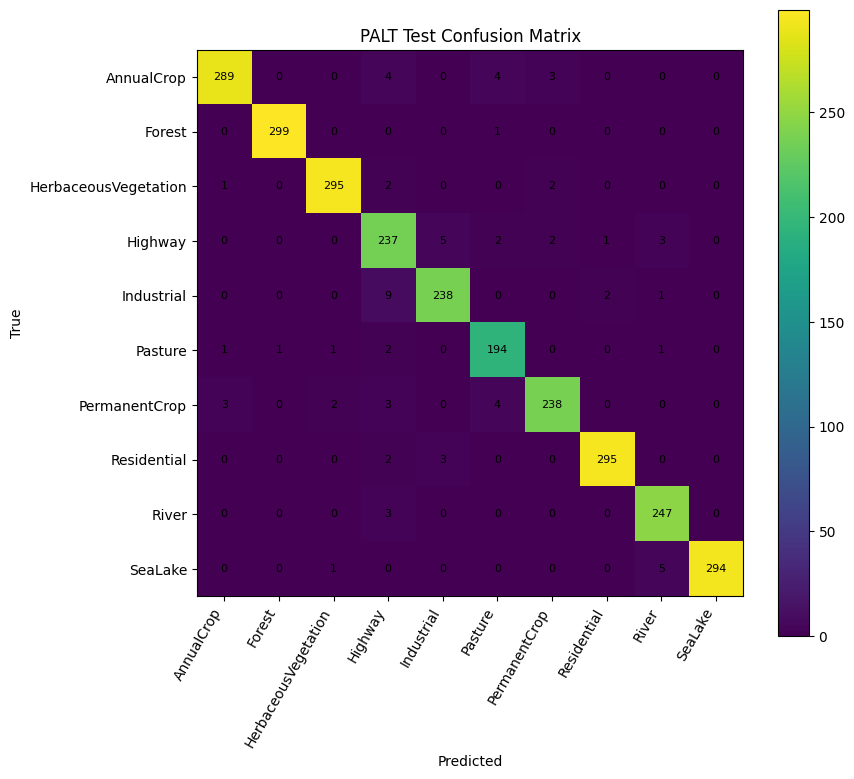

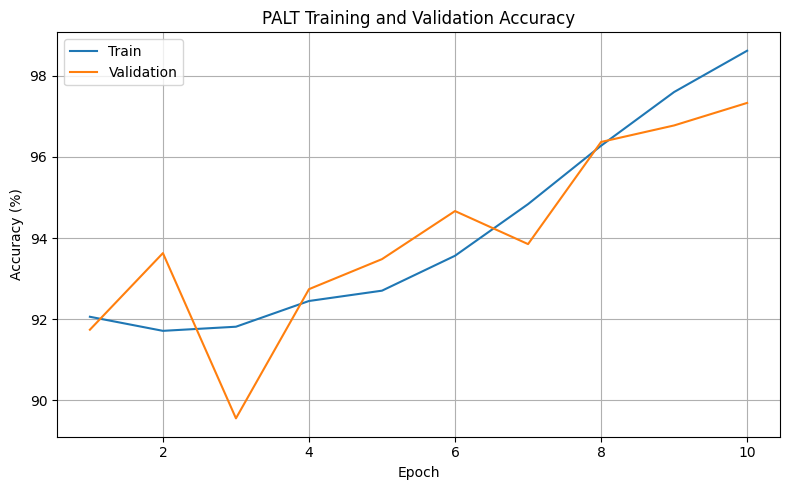

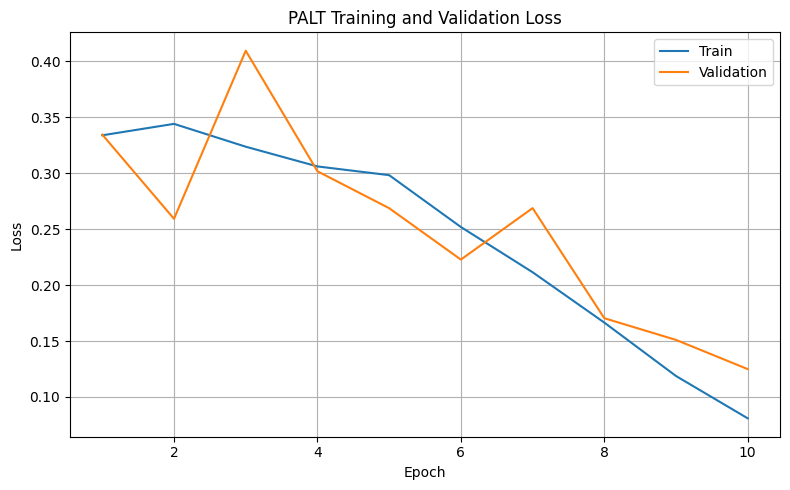

Inference latency: {'batch_size': 16, 'mean_ms': 50.67650780004745, 'std_ms': 0.7101268018977293, 'per_image_ms': 3.167281737502966}


In [81]:
# ================================================================
# NV-1.4 — Confusion Matrix + Learning Curves + Inference Cost
# ================================================================

# Confusion matrix
plt.figure(figsize=(9,8))
plt.imshow(cm, interpolation="nearest")
plt.title("PALT Test Confusion Matrix")
plt.colorbar()
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=60, ha="right")
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR/"nv1_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Training curves if history exists
hist_path = TAB_DIR/"training_history.csv"
if hist_path.exists():
    h = pd.read_csv(hist_path)
    plt.figure(figsize=(8,5)); plt.plot(h.epoch, h.train_acc, label="Train"); plt.plot(h.epoch, h.val_acc, label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title("PALT Training and Validation Accuracy"); plt.grid(True); plt.legend(); plt.tight_layout()
    plt.savefig(FIG_DIR/"nv1_accuracy_curve.png", dpi=300); plt.show()
    plt.figure(figsize=(8,5)); plt.plot(h.epoch, h.train_loss, label="Train"); plt.plot(h.epoch, h.val_loss, label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("PALT Training and Validation Loss"); plt.grid(True); plt.legend(); plt.tight_layout()
    plt.savefig(FIG_DIR/"nv1_loss_curve.png", dpi=300); plt.show()

# Warm-up + synchronized latency measurement
model.eval()
latency_batch = next(iter(test_loader))[0].to(DEVICE)
for _ in range(5):
    with torch.no_grad(): _ = model(latency_batch)
if torch.cuda.is_available(): torch.cuda.synchronize()
times = []
for _ in range(30):
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad(): _ = model(latency_batch)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    times.append((time.perf_counter()-t0)*1000)
latency = {"batch_size": int(latency_batch.size(0)), "mean_ms": float(np.mean(times)), "std_ms": float(np.std(times)), "per_image_ms": float(np.mean(times)/latency_batch.size(0))}
json.dump(latency, open(TAB_DIR/"nv1_inference_latency.json","w"), indent=2)
print("Inference latency:", latency)


In [82]:
model.eval()
K = int(cfg.MEMORY_SIZE)
C = int(cfg.NUM_CLASSES)

sum_proto_sim = torch.zeros(K,K)
sum_graph_attn = torch.zeros(K,K)
sum_init_attn = torch.zeros(K, 197)
sum_importance = torch.zeros(K)
sum_pih_importance = torch.zeros(K)
sum_pcam = torch.zeros(K,C)
count_proto = 0

# class-wise dynamic summaries
class_counts = np.zeros(C, dtype=np.int64)
dyn_sum = {k: np.zeros((C,), dtype=np.float64) for k in ["tau_pld","beta_pld","delta_norm","retention","lgst_tau","lgst_beta","lgst_alpha","lgst_update_gate","lgst_retention_gate","amfr_gate","pri_gate"]}
dyn_sq = {k: np.zeros((C,), dtype=np.float64) for k in dyn_sum}

memory_stage_sum = {k: 0.0 for k in ["proto_to_updated","updated_to_fused","fused_to_encoder","proto_to_encoder"]}
memory_stage_sq = {k: 0.0 for k in memory_stage_sum}
memory_n = 0

# Prototype utilization: count top-1/top-5 prototype selections
util_top1 = np.zeros(K, dtype=np.int64)
util_top5 = np.zeros(K, dtype=np.int64)

# Explanation/prototype association storage for every test image in compact form
importance_rows = []


def add_stat(name, vals, cls_ids):
    vals = np.asarray(vals, dtype=np.float64)
    cls_ids = np.asarray(cls_ids, dtype=np.int64)
    for c in range(C):
        m = cls_ids == c
        if np.any(m):
            x = vals[m]
            dyn_sum[name][c] += x.sum()
            dyn_sq[name][c] += np.square(x).sum()

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="NV-2 Mechanism Analysis"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        out = palt_trace_forward(model, images)
        d = out["diagnostics"]
        m = out["memory"]
        bs = labels.size(0)
        cls_np = labels.cpu().numpy()
        class_counts += np.bincount(cls_np, minlength=C)

        sim = d["similarity_matrix"].float().cpu()
        ga = d["graph_attention"].float().cpu()
        pa = d["prototype_attention"].float().cpu()
        imp = out["importance_scores"].float().cpu()
        pcam = out["prototype_class_scores"].float().cpu()
        pcam_assoc = d["pih"].get("association_matrix") if isinstance(d["pih"], dict) else None
        if pcam_assoc is not None: pcam_assoc = pcam_assoc.float().cpu()

        sum_proto_sim += sim.sum(0)
        sum_graph_attn += ga.sum(0)
        sum_init_attn += pa.sum(0)
        sum_importance += imp.sum(0)
        sum_pih_importance += imp.sum(0)
        sum_pcam += pcam.sum(0)
        count_proto += bs

        top1 = imp.argmax(1).numpy()
        top5 = torch.topk(imp, k=min(5,K), dim=1).indices.numpy()
        for j in top1: util_top1[j] += 1
        for row in top5:
            util_top5[row] += 1

        # Memory evolution using cosine distance.
        def cos_dist(a,b):
            return (1-F.cosine_similarity(a,b,dim=-1)).mean(dim=-1).cpu().numpy()
        stage_vals = {
            "proto_to_updated": cos_dist(m["prototype"], m["updated"]),
            "updated_to_fused": cos_dist(m["updated"], m["fused"]),
            "fused_to_encoder": cos_dist(m["fused"], m["encoder"]),
            "proto_to_encoder": cos_dist(m["prototype"], m["encoder"]),
        }
        for name, arr in stage_vals.items():
            memory_stage_sum[name] += float(arr.sum())
            memory_stage_sq[name] += float(np.square(arr).sum())
        memory_n += bs

        # PLD values per image: average over prototypes/features.
        add_stat("tau_pld", d["tau"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("beta_pld", d["beta"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("delta_norm", d["delta"].norm(dim=-1).mean(dim=1).cpu().numpy(), cls_np)
        add_stat("retention", d["retention_gate"].mean(dim=(1,2)).cpu().numpy(), cls_np)

        lg = d["alte"]["lgst"]
        add_stat("lgst_tau", lg["tau"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("lgst_beta", lg["beta"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("lgst_alpha", lg["alpha"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("lgst_update_gate", lg["update_gate"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("lgst_retention_gate", lg["retention_gate"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("amfr_gate", d["alte"]["amfr"]["gate"].mean(dim=(1,2)).cpu().numpy(), cls_np)
        add_stat("pri_gate", d["alte"]["pri"]["gate"].mean(dim=(1,2)).cpu().numpy(), cls_np)

        importance_rows.append(imp.numpy())

# Final matrices
mean_proto_sim = (sum_proto_sim / count_proto).numpy()
mean_graph_attn = (sum_graph_attn / count_proto).numpy()
mean_init_attn = (sum_init_attn / count_proto).numpy()
mean_importance = (sum_importance / count_proto).numpy()
mean_pcam_scores = (sum_pcam / count_proto).numpy()
importance_matrix = np.concatenate(importance_rows, axis=0)

np.save(TAB_DIR/"nv2_mean_prototype_similarity.npy", mean_proto_sim)
np.save(TAB_DIR/"nv2_mean_graph_attention.npy", mean_graph_attn)
np.save(TAB_DIR/"nv2_mean_initial_prototype_attention.npy", mean_init_attn)
np.save(TAB_DIR/"nv2_mean_prototype_importance.npy", mean_importance)
np.save(TAB_DIR/"nv2_mean_prototype_class_scores.npy", mean_pcam_scores)
np.save(TAB_DIR/"nv2_image_prototype_importance.npy", importance_matrix)

print("NV-2 collection complete for", count_proto, "test images.")


NV-2 Mechanism Analysis:   0%|          | 0/169 [00:00<?, ?it/s]

NV-2 collection complete for 2700 test images.


NV-2 PROTOTYPE STRUCTURE
mean_pairwise_cosine_offdiag                 : 0.892032
median_pairwise_cosine_offdiag               : 0.956820
max_pairwise_cosine_offdiag                  : 0.999979
min_pairwise_cosine_offdiag                  : 0.595882
fraction_pairs_cosine_gt_0.90                : 0.629032
fraction_pairs_cosine_gt_0.95                : 0.534274
fraction_pairs_cosine_gt_0.99                : 0.274194

Prototype utilization
active_prototypes_top1                       : 32
active_prototypes_top5                       : 32
top1_utilization_entropy                     : 0.6205515090778513
top5_utilization_entropy                     : 0.855017612423499

Memory evolution
proto_to_updated         : mean=0.000056, std=0.000194
updated_to_fused         : mean=0.000603, std=0.000598
fused_to_encoder         : mean=0.178950, std=0.040631
proto_to_encoder         : mean=0.180927, std=0.040704


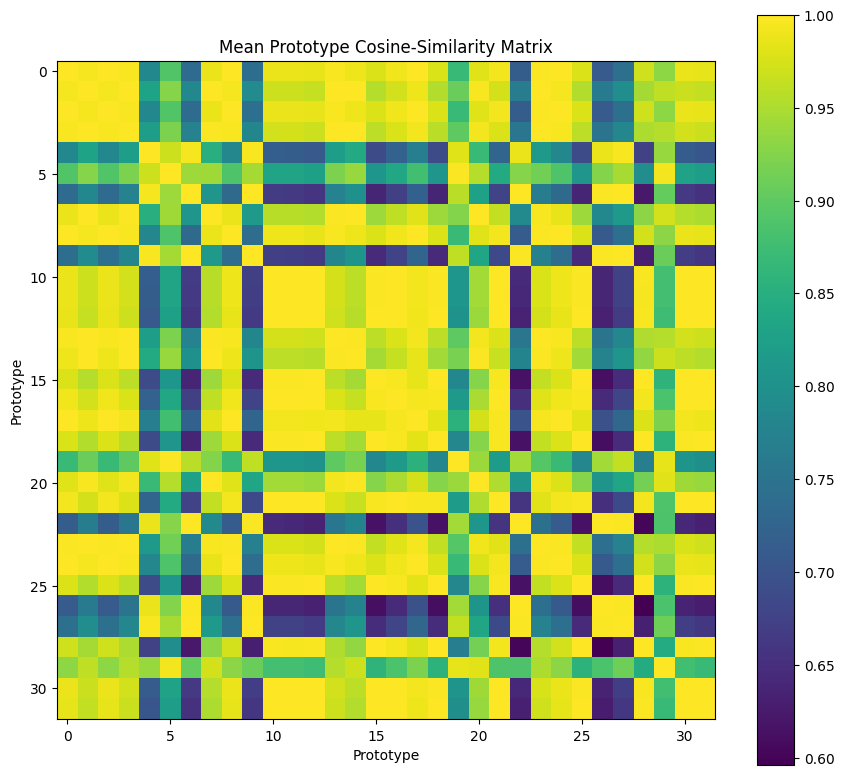

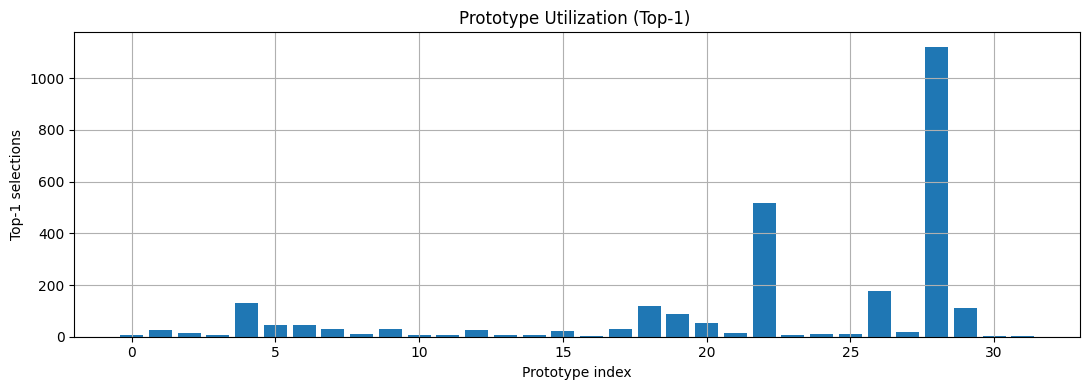

In [83]:
# ================================================================
# NV-2.2 — Prototype Redundancy, Utilization, and Memory Evolution
# ================================================================

off_diag = ~np.eye(K, dtype=bool)
off_diag_vals = mean_proto_sim[off_diag]
redundancy_summary = {
    "mean_pairwise_cosine_offdiag": float(off_diag_vals.mean()),
    "median_pairwise_cosine_offdiag": float(np.median(off_diag_vals)),
    "max_pairwise_cosine_offdiag": float(off_diag_vals.max()),
    "min_pairwise_cosine_offdiag": float(off_diag_vals.min()),
    "fraction_pairs_cosine_gt_0.90": float(np.mean(off_diag_vals > 0.90)),
    "fraction_pairs_cosine_gt_0.95": float(np.mean(off_diag_vals > 0.95)),
    "fraction_pairs_cosine_gt_0.99": float(np.mean(off_diag_vals > 0.99)),
}

util_summary = {
    "active_prototypes_top1": int(np.sum(util_top1 > 0)),
    "active_prototypes_top5": int(np.sum(util_top5 > 0)),
    "top1_utilization_entropy": float(-(p:=util_top1/util_top1.sum()+1e-12)[p>0].dot(np.log(p[p>0])) / np.log(K)),
    "top5_utilization_entropy": float(-(q:=util_top5/util_top5.sum()+1e-12)[q>0].dot(np.log(q[q>0])) / np.log(K)),
}

memory_summary = {}
for name in memory_stage_sum:
    mu = memory_stage_sum[name] / memory_n
    var = max(memory_stage_sq[name] / memory_n - mu*mu, 0.0)
    memory_summary[name] = {"mean_cosine_distance": float(mu), "std": float(np.sqrt(var))}

json.dump(redundancy_summary, open(TAB_DIR/"nv2_redundancy_summary.json","w"), indent=2)
json.dump(util_summary, open(TAB_DIR/"nv2_utilization_summary.json","w"), indent=2)
json.dump(memory_summary, open(TAB_DIR/"nv2_memory_evolution_summary.json","w"), indent=2)

print("="*90); print("NV-2 PROTOTYPE STRUCTURE"); print("="*90)
for k,v in redundancy_summary.items(): print(f"{k:45s}: {v:.6f}")
print("\nPrototype utilization")
for k,v in util_summary.items(): print(f"{k:45s}: {v}")
print("\nMemory evolution")
for k,v in memory_summary.items(): print(f"{k:25s}: mean={v['mean_cosine_distance']:.6f}, std={v['std']:.6f}")

# Similarity heatmap
plt.figure(figsize=(9,8)); plt.imshow(mean_proto_sim, interpolation="nearest"); plt.colorbar(); plt.title("Mean Prototype Cosine-Similarity Matrix"); plt.xlabel("Prototype"); plt.ylabel("Prototype"); plt.tight_layout(); plt.savefig(FIG_DIR/"nv2_prototype_similarity.png", dpi=300); plt.show()

# Utilization
plt.figure(figsize=(11,4)); plt.bar(np.arange(K), util_top1); plt.xlabel("Prototype index"); plt.ylabel("Top-1 selections"); plt.title("Prototype Utilization (Top-1) "); plt.grid(True); plt.tight_layout(); plt.savefig(FIG_DIR/"nv2_prototype_utilization.png", dpi=300); plt.show()


,class,n,tau_pld_mean,tau_pld_std,beta_pld_mean,beta_pld_std,delta_norm_mean,delta_norm_std,retention_mean,retention_std,...,lgst_alpha_mean,lgst_alpha_std,lgst_update_gate_mean,lgst_update_gate_std,lgst_retention_gate_mean,lgst_retention_gate_std,amfr_gate_mean,amfr_gate_std,pri_gate_mean,pri_gate_std
0,AnnualCrop,300,10.65443,2.62474,0.46654,0.32551,16.76417,0.65712,0.50010,0.36978,...,0.24960,0.00820,0.53231,0.01055,0.46866,0.01261,0.45509,0.02006,0.31642,0.02587
1,Forest,300,0.28114,0.93522,0.00101,0.00481,15.80496,0.13101,0.99627,0.03284,...,0.26560,0.00828,0.50648,0.00915,0.49581,0.00856,0.45472,0.01425,0.30536,0.02555
2,HerbaceousVegetation,300,10.62899,2.97901,0.58622,0.36218,15.99731,0.31244,0.73833,0.35778,...,0.24052,0.01119,0.54019,0.01287,0.46388,0.01820,0.47489,0.01554,0.30022,0.04030
3,Highway,250,6.59000,3.36950,0.09651,0.20342,15.75596,0.34363,0.95427,0.10892,...,0.23259,0.00746,0.54905,0.00742,0.44747,0.01184,0.42643,0.01267,0.26574,0.01169
4,Industrial,250,5.94612,1.55150,0.05059,0.08287,15.60977,0.15524,0.99604,0.01902,...,0.23731,0.00631,0.54100,0.00657,0.45321,0.00909,0.42391,0.01235,0.26084,0.01416
5,Pasture,200,4.77926,2.91083,0.06824,0.18214,15.83398,0.41104,0.51058,0.40516,...,0.24932,0.00947,0.52701,0.01306,0.47952,0.01250,0.43988,0.01521,0.30805,0.03052
6,PermanentCrop,250,10.03732,3.29955,0.17274,0.24670,16.19588,0.48762,0.74889,0.33503,...,0.23882,0.00706,0.54280,0.00885,0.45469,0.00932,0.45164,0.01576,0.28594,0.02540
7,Residential,300,3.58098,1.68216,0.00387,0.01141,15.67135,0.22210,0.99695,0.01685,...,0.23238,0.00552,0.53908,0.00538,0.45323,0.00832,0.46312,0.01253,0.31704,0.02281
8,River,250,4.90342,2.19842,0.18340,0.16485,15.64949,0.18032,0.95005,0.08033,...,0.24547,0.00914,0.53308,0.01167,0.46949,0.01323,0.42158,0.01068,0.27374,0.01258
9,SeaLake,300,0.16039,0.47462,0.53909,0.20417,15.89715,0.23352,0.98642,0.01194,...,0.30023,0.00945,0.46566,0.01092,0.54103,0.01191,0.46582,0.01196,0.47568,0.04706


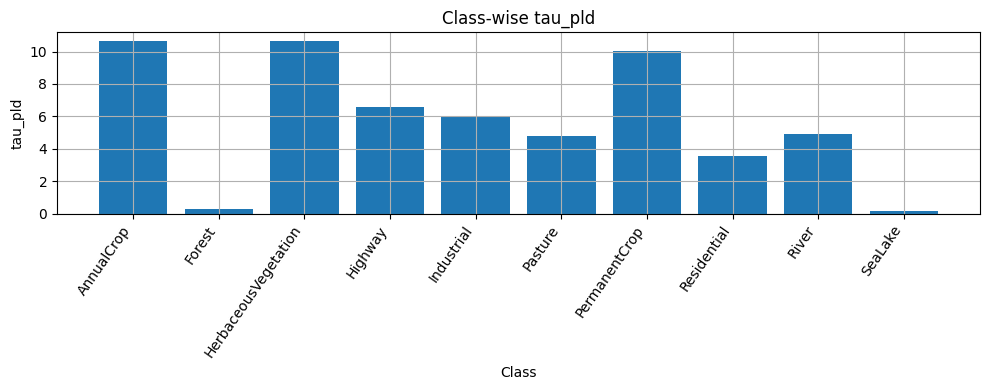

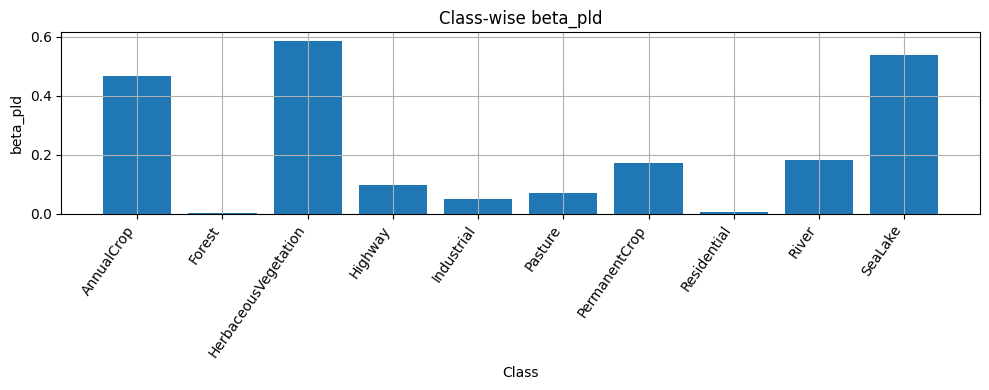

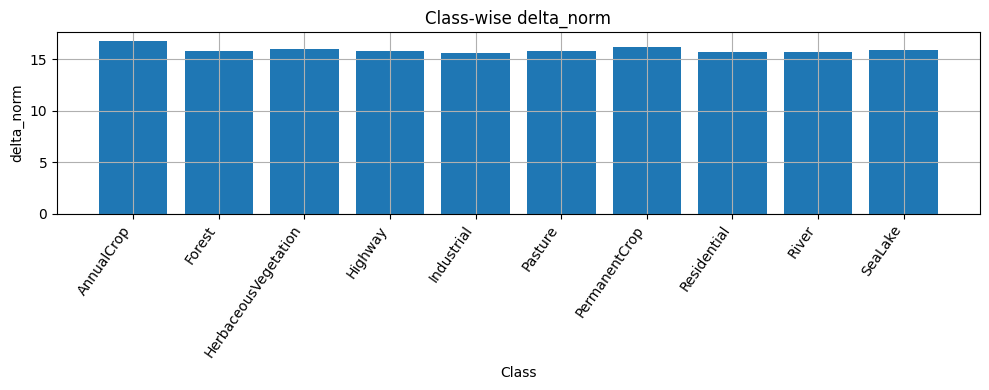

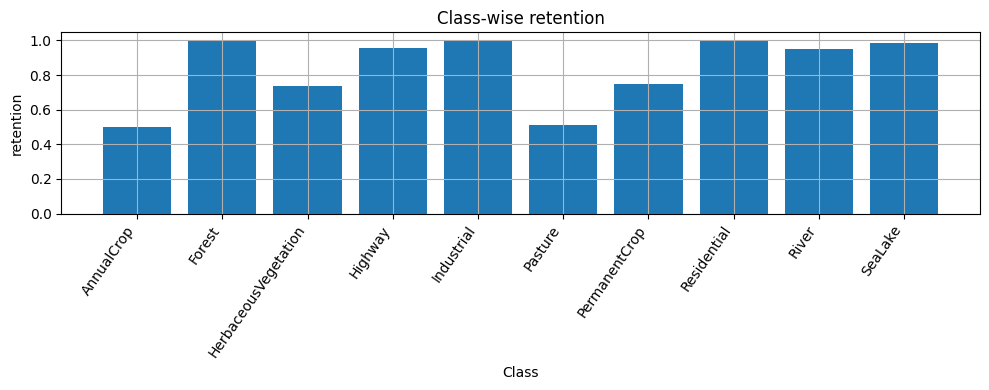

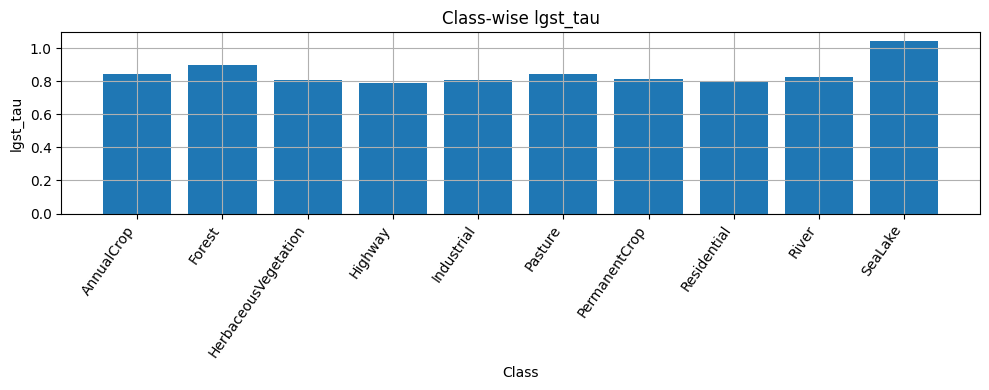

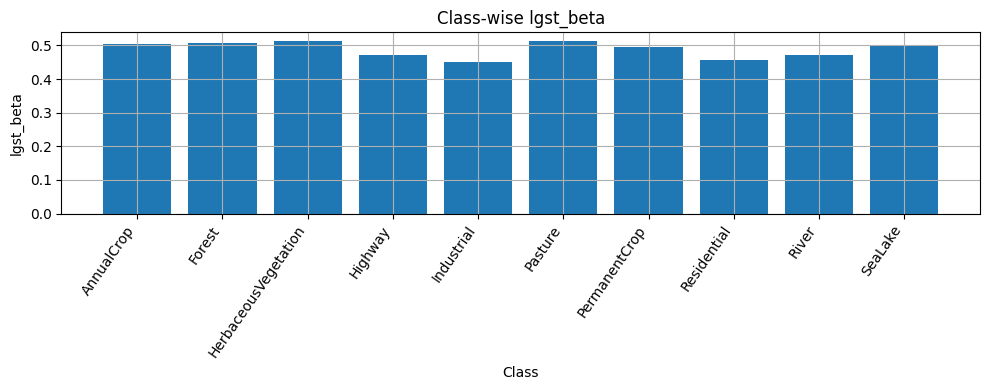

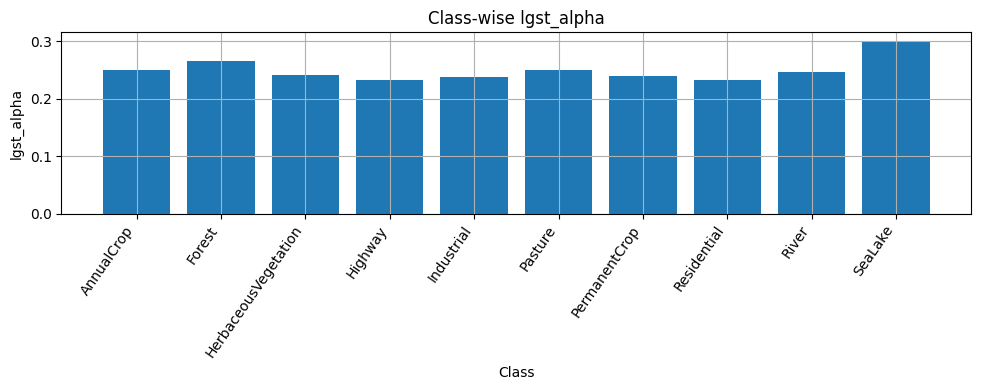

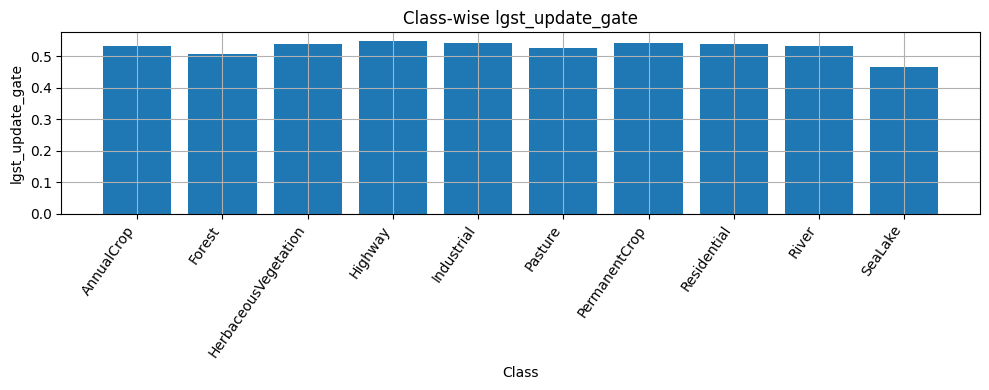

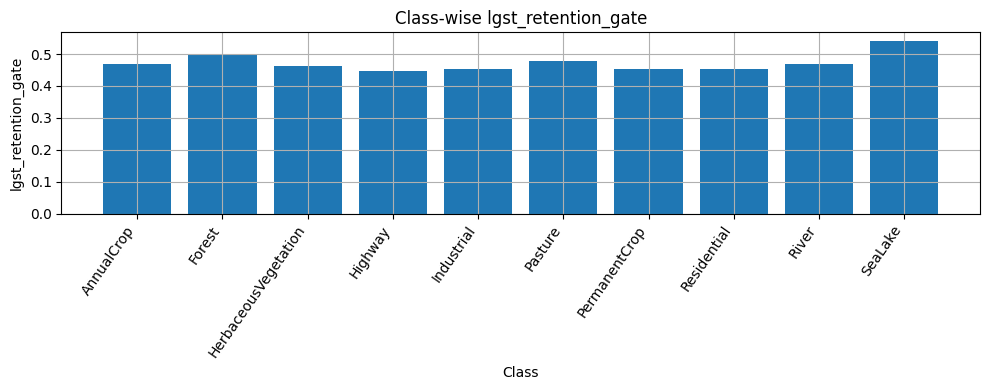

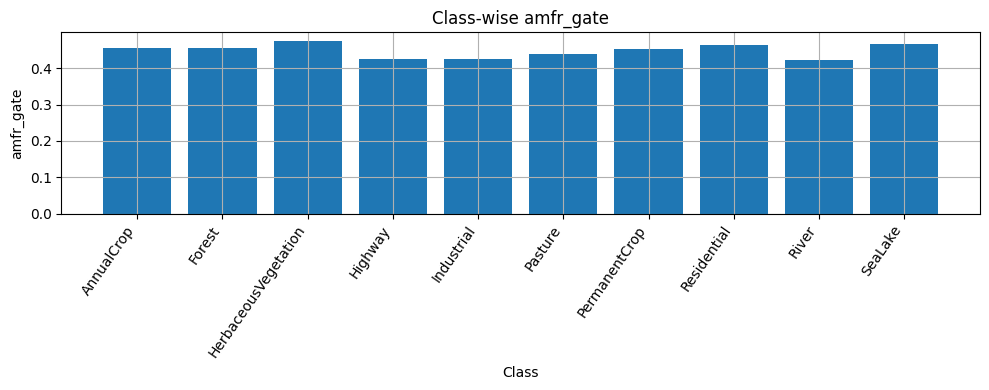

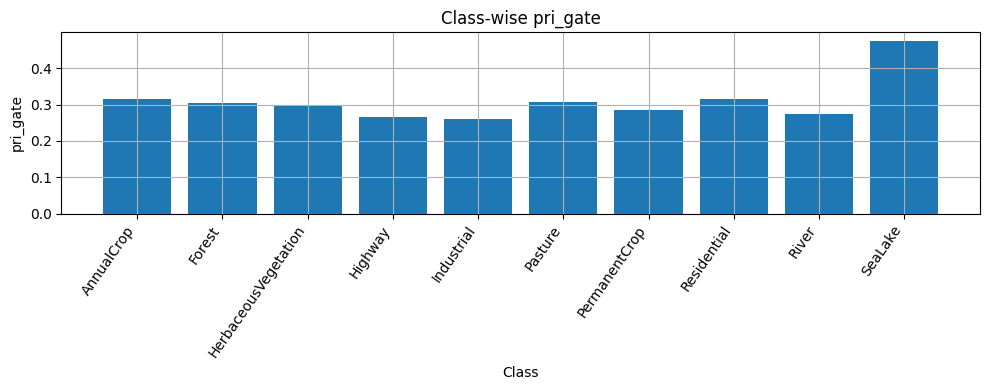

In [84]:
# ================================================================
# NV-2.3 — Liquid Dynamics Distributions and Class-wise Statistics
# ================================================================

rows = []
for c, cls in enumerate(CLASS_NAMES):
    row = {"class": cls, "n": int(class_counts[c])}
    for name in dyn_sum:
        mu = dyn_sum[name][c] / max(class_counts[c],1)
        var = max(dyn_sq[name][c] / max(class_counts[c],1) - mu*mu, 0.0)
        row[name+"_mean"] = mu
        row[name+"_std"] = math.sqrt(var)
    rows.append(row)

dyn_df = pd.DataFrame(rows)
dyn_df.to_csv(TAB_DIR/"nv2_classwise_liquid_dynamics.csv", index=False)
display(dyn_df.round(5))

# Compact distributions across all images/classes are reconstructed from class means/stds;
# the class-wise table is the publication table, while the next plots use class means.
for name in ["tau_pld","beta_pld","delta_norm","retention","lgst_tau","lgst_beta","lgst_alpha","lgst_update_gate","lgst_retention_gate","amfr_gate","pri_gate"]:
    plt.figure(figsize=(10,4))
    plt.bar(np.arange(C), dyn_df[name+"_mean"])
    plt.xticks(np.arange(C), CLASS_NAMES, rotation=55, ha="right")
    plt.xlabel("Class"); plt.ylabel(name); plt.title(f"Class-wise {name}"); plt.grid(True); plt.tight_layout()
    plt.savefig(FIG_DIR/f"nv2_{name}_classwise.png", dpi=300, bbox_inches="tight")
    plt.show()


In [85]:
# ================================================================
# NV-2.4 — Cross-stage Prototype Evolution Visualization
# ================================================================

# Select one correctly classified test example from each class.
selected = {}
model.eval()
with torch.no_grad():
    for idx in range(len(test_dataset)):
        img, lab = test_dataset[idx]
        x = img.unsqueeze(0).to(DEVICE)
        out = palt_trace_forward(model, x)
        pred = int(out["logits"].argmax(1).item())
        if pred == int(lab) and int(lab) not in selected:
            selected[int(lab)] = {"index": idx, "image": img, "label": int(lab), "out": out}
        if len(selected) == C: break

# For each selected image, compare prototype memory states by mean cosine similarity.
evolution_rows = []
for c in range(C):
    if c not in selected: continue
    out = selected[c]["out"]
    mem = out["memory"]
    for stage_a, stage_b in [("prototype","updated"),("updated","fused"),("fused","encoder"),("prototype","encoder")]:
        dist = (1-F.cosine_similarity(mem[stage_a], mem[stage_b], dim=-1)).mean().item()
        evolution_rows.append({"class": CLASS_NAMES[c], "transition": f"{stage_a}→{stage_b}", "mean_cosine_distance": dist})
evolution_df = pd.DataFrame(evolution_rows)
evolution_df.to_csv(TAB_DIR/"nv2_selected_cross_stage_evolution.csv", index=False)
display(evolution_df.round(5))


,class,transition,mean_cosine_distance
0,AnnualCrop,prototype→updated,0.00060
1,AnnualCrop,updated→fused,0.00043
2,AnnualCrop,fused→encoder,0.18500
3,AnnualCrop,prototype→encoder,0.19128
4,Forest,prototype→updated,0.00000
5,Forest,updated→fused,0.00033
6,Forest,fused→encoder,0.14359
7,Forest,prototype→encoder,0.14591
8,HerbaceousVegetation,prototype→updated,0.00000
9,HerbaceousVegetation,updated→fused,0.00059


NV-3 Explainability Matrices:   0%|          | 0/169 [00:00<?, ?it/s]

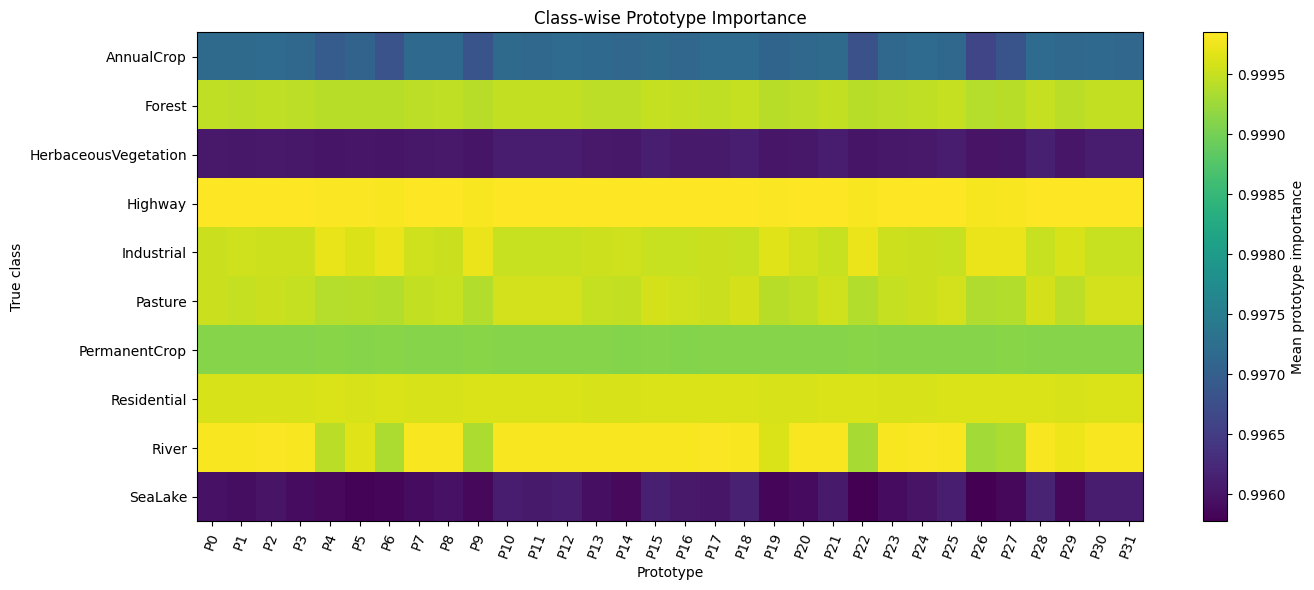

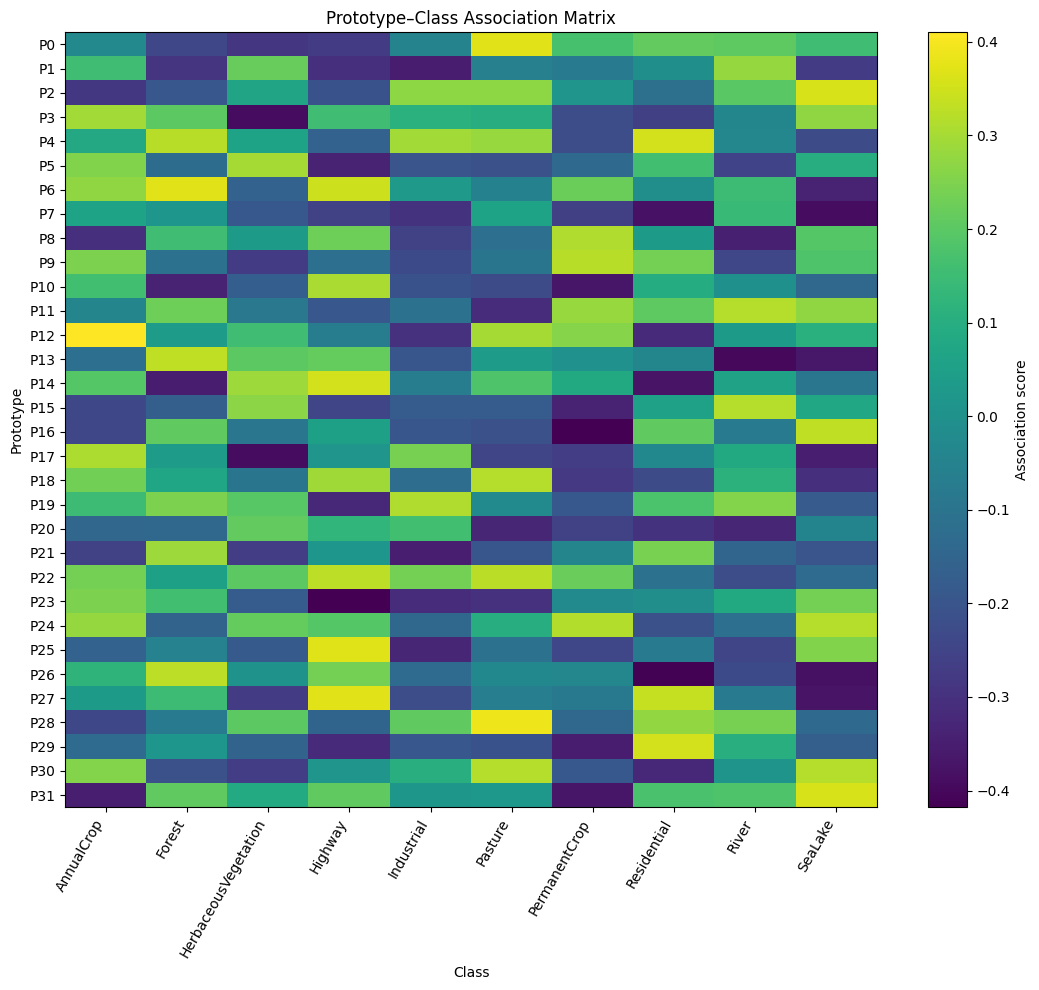

,prototype,dominant_class,dominant_score,association_entropy
0,0,Pasture,0.37369,4.29641
1,1,River,0.27796,4.21129
2,2,SeaLake,0.36088,4.22593
3,3,AnnualCrop,0.29469,4.44581
4,4,Residential,0.35237,4.36079
5,5,HerbaceousVegetation,0.29885,4.62694
6,6,Forest,0.37338,3.98883
7,7,River,0.13979,4.28162
8,8,PermanentCrop,0.31182,4.20461
9,9,PermanentCrop,0.32227,4.58922


In [86]:
# ================================================================
# NV-3.1 — Prototype-level Explainability Matrices
# ================================================================

# Mean importance per prototype and class (prediction-grounded aggregation).
class_proto_importance = np.zeros((C,K), dtype=np.float64)
class_counts_imp = np.zeros(C, dtype=np.int64)

# Prototype-class association matrix from the PIH diagnostics.
assoc_sum = np.zeros((K,C), dtype=np.float64)
assoc_n = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="NV-3 Explainability Matrices"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        out = palt_trace_forward(model, images)
        imp = out["importance_scores"].float().cpu().numpy()
        labs = labels.cpu().numpy()
        for c in range(C):
            m = labs == c
            if np.any(m):
                class_proto_importance[c] += imp[m].sum(axis=0)
                class_counts_imp[c] += int(m.sum())
        assoc = out["diagnostics"]["pih"].get("association_matrix")
        if assoc is not None:
            assoc_sum += assoc.float().cpu().numpy().sum(axis=0)
            assoc_n += images.size(0)

class_proto_importance /= np.maximum(class_counts_imp[:,None],1)
mean_assoc = assoc_sum / max(assoc_n,1)

np.save(TAB_DIR/"nv3_class_prototype_importance.npy", class_proto_importance)
np.save(TAB_DIR/"nv3_prototype_class_association.npy", mean_assoc)
pd.DataFrame(class_proto_importance, index=CLASS_NAMES, columns=[f"P{i}" for i in range(K)]).to_csv(TAB_DIR/"nv3_class_prototype_importance.csv")
pd.DataFrame(mean_assoc, index=[f"P{i}" for i in range(K)], columns=CLASS_NAMES).to_csv(TAB_DIR/"nv3_prototype_class_association.csv")

# Heatmap 1: class x prototype importance
plt.figure(figsize=(14,6)); plt.imshow(class_proto_importance, aspect="auto", interpolation="nearest"); plt.colorbar(label="Mean prototype importance"); plt.yticks(range(C), CLASS_NAMES); plt.xticks(range(K), [f"P{i}" for i in range(K)], rotation=70); plt.xlabel("Prototype"); plt.ylabel("True class"); plt.title("Class-wise Prototype Importance"); plt.tight_layout(); plt.savefig(FIG_DIR/"nv3_class_prototype_importance.png", dpi=300, bbox_inches="tight"); plt.show()

# Heatmap 2: prototype x class association
plt.figure(figsize=(11,10)); plt.imshow(mean_assoc, aspect="auto", interpolation="nearest"); plt.colorbar(label="Association score"); plt.yticks(range(K), [f"P{i}" for i in range(K)]); plt.xticks(range(C), CLASS_NAMES, rotation=60, ha="right"); plt.xlabel("Class"); plt.ylabel("Prototype"); plt.title("Prototype–Class Association Matrix"); plt.tight_layout(); plt.savefig(FIG_DIR/"nv3_prototype_class_association.png", dpi=300, bbox_inches="tight"); plt.show()

# Prototype specialization summary
specialization = []
for p in range(K):
    row = mean_assoc[p]
    best = int(np.argmax(row))
    specialization.append({"prototype": p, "dominant_class": CLASS_NAMES[best], "dominant_score": float(row[best]), "association_entropy": float(-(q:=np.abs(row)+1e-12)[q>0].dot(np.log(q[q>0]/q.sum())))})
spec_df = pd.DataFrame(specialization)
spec_df.to_csv(TAB_DIR/"nv3_prototype_specialization.csv", index=False)
display(spec_df.head(15).round(5))


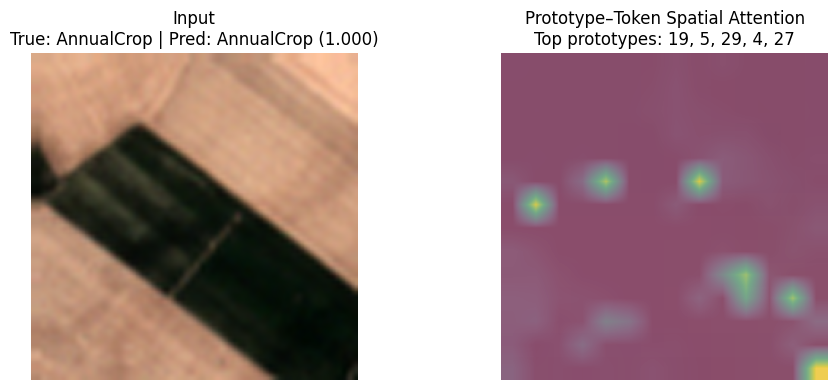

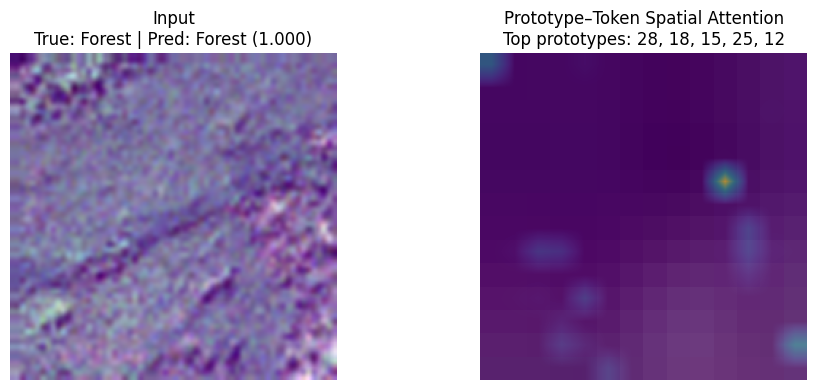

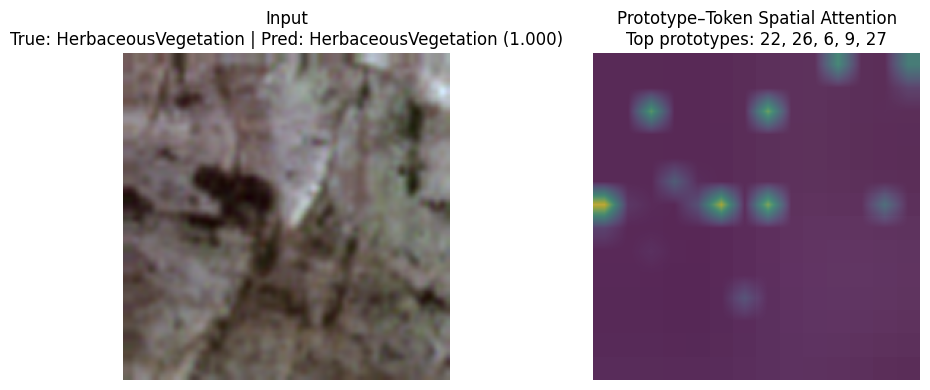

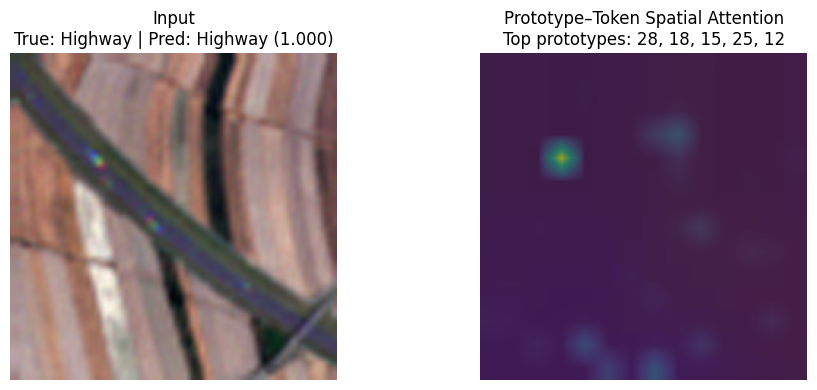

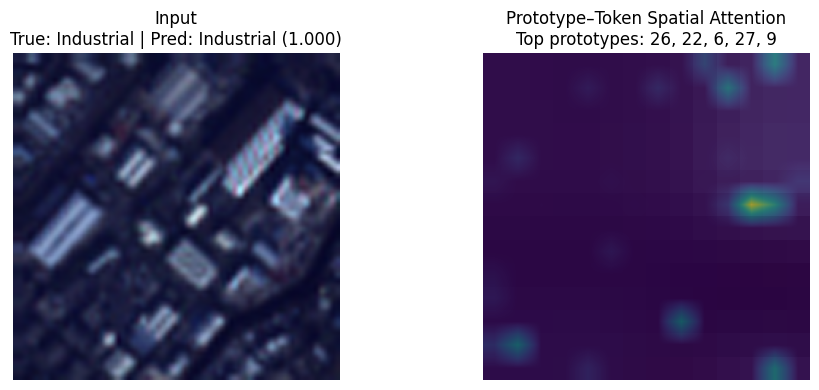

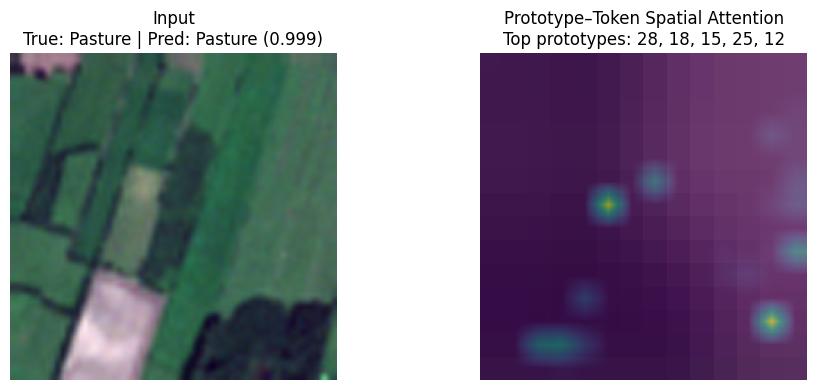

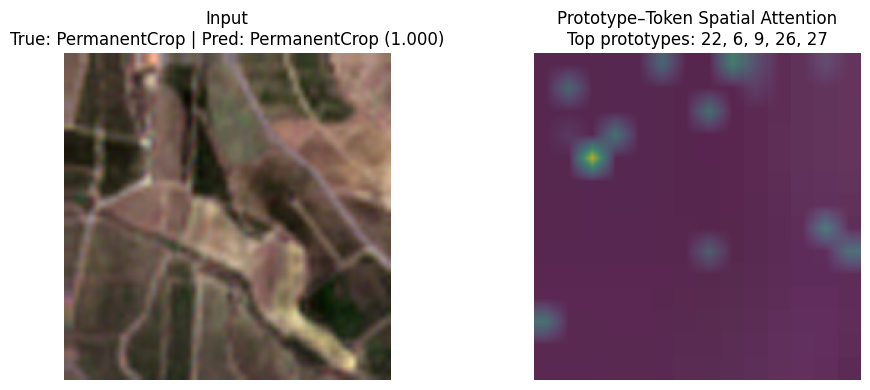

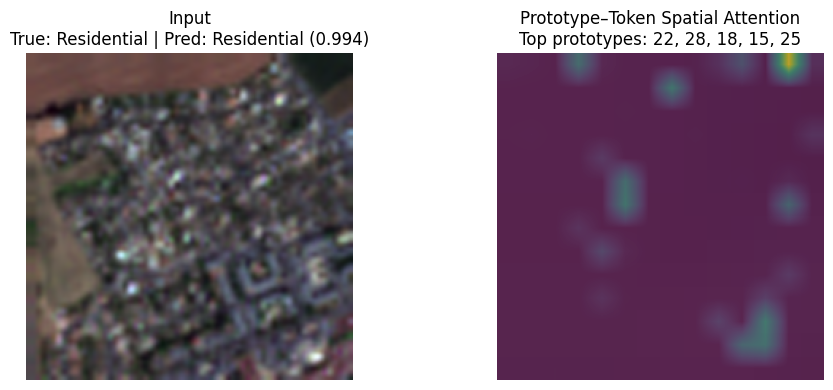

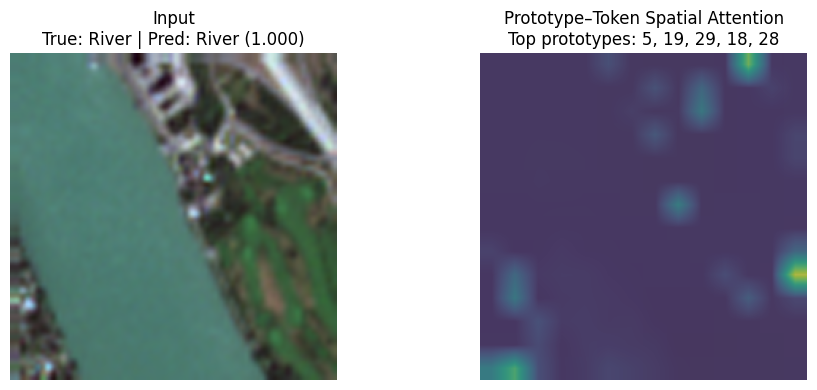

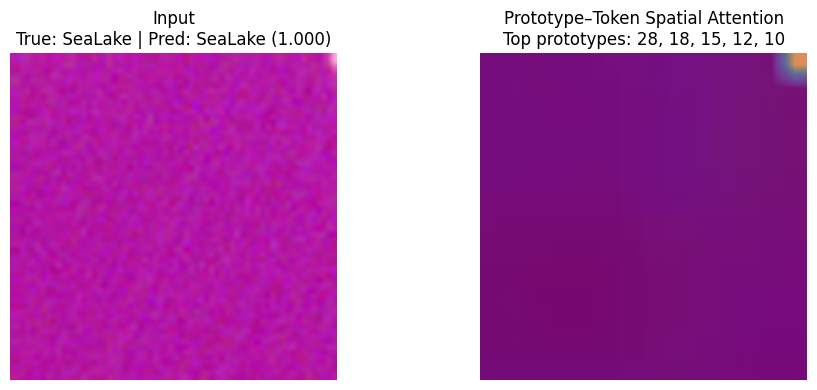

In [87]:
# ================================================================
# NV-3.2 — Prototype → Token Attention and Spatial Localization
# ================================================================

# Helper: map 197-token attention to 14x14 patch grid, excluding CLS.
def prototype_spatial_map(attention_map, importance_scores, sample_idx=0, top_k=5):
    # attention_map: [B,H,K,N]
    A = attention_map[sample_idx].float()              # [H,K,N]
    imp = importance_scores[sample_idx].float()        # [K]
    top = torch.topk(imp, k=min(top_k, imp.numel())).indices
    # Average heads, then importance-weight top prototypes.
    token_scores = A[:, top, 1:].mean(0)               # [Ktop,196]
    w = imp[top] / (imp[top].sum()+1e-8)
    score = (w[:,None] * token_scores).sum(0)
    score = score / (score.max()+1e-8)
    return score.reshape(14,14).cpu().numpy(), top.cpu().numpy(), score.cpu().numpy()

# Produce one explanation example per class where available.
explanation_records = []
for c in sorted(selected.keys()):
    item = selected[c]
    out = item["out"]
    probs = torch.softmax(out["logits"].float(), dim=1)[0]
    pred = int(probs.argmax().item())
    conf = float(probs[pred].item())
    smap, top_proto, token_score = prototype_spatial_map(out["attention_map"], out["importance_scores"], 0, top_k=5)
    explanation_records.append({"class": CLASS_NAMES[c], "sample_index": item["index"], "prediction": CLASS_NAMES[pred], "confidence": conf, "top_prototypes": top_proto.tolist(), "top_prototype_importance": out["importance_scores"][0,top_proto].detach().cpu().numpy().tolist()})

json.dump(explanation_records, open(EXP_DIR/"nv3_selected_explanation_records.json","w"), indent=2)

# Save one spatial explanation figure per selected class.
for c in sorted(selected.keys()):
    item = selected[c]; out = item["out"]
    img = item["image"].numpy()
    # Sentinel-2 natural-color approximation: B4/B3/B2 -> indices 3,2,1 in 13-band EuroSAT-MS ordering.
    rgb = np.stack([img[3], img[2], img[1]], axis=-1)
    rgb = (rgb-rgb.min())/(rgb.max()-rgb.min()+1e-8)
    smap, top_proto, _ = prototype_spatial_map(out["attention_map"], out["importance_scores"], 0, top_k=5)
    probs = torch.softmax(out["logits"].float(),1)[0]; pred=int(probs.argmax()); conf=float(probs[pred])

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1); plt.imshow(np.clip(rgb,0,1)); plt.title(f"Input\nTrue: {CLASS_NAMES[c]} | Pred: {CLASS_NAMES[pred]} ({conf:.3f})"); plt.axis("off")
    plt.subplot(1,2,2); plt.imshow(np.clip(rgb,0,1)); plt.imshow(smap, alpha=0.55, interpolation="bilinear"); plt.title("Prototype–Token Spatial Attention\nTop prototypes: "+", ".join(map(str,top_proto))); plt.axis("off")
    plt.tight_layout(); plt.savefig(EXP_DIR/f"class_{c:02d}_{CLASS_NAMES[c]}_prototype_attention.png", dpi=300, bbox_inches="tight"); plt.show()


In [88]:
# ================================================================
# NV-3.3 — Quantitative Explanation Faithfulness via Patch Deletion
# Tests whether the regions highlighted by prototype-token attention
# materially support the prediction.
# ================================================================

FAITHFULNESS_SAMPLES_PER_CLASS = 3
TOP_PATCH_FRACTION = 0.10

faith_rows = []
for c in sorted(selected.keys()):
    # Find first few correctly classified samples of this class.
    indices = [i for i,l in enumerate(test_labels) if l==c][:FAITHFULNESS_SAMPLES_PER_CLASS]
    for idx in indices:
        image, label = test_dataset[idx]
        x = image.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            out = palt_trace_forward(model, x)
            prob = torch.softmax(out["logits"].float(),1)[0]
            pred = int(prob.argmax()); base_conf=float(prob[pred])
            smap, top_proto, token_score = prototype_spatial_map(out["attention_map"], out["importance_scores"], 0, top_k=5)

        flat = token_score.copy()
        nmask = max(1, int(round(196*TOP_PATCH_FRACTION)))
        top_patch_idx = np.argsort(flat)[-nmask:]
        masked = image.clone()
        # Standardized zero corresponds to the training-set band mean.
        for pidx in top_patch_idx:
            r, col = divmod(int(pidx), 14)
            masked[:, r*16:(r+1)*16, col*16:(col+1)*16] = 0.0
        with torch.no_grad():
            mout = palt_trace_forward(model, masked.unsqueeze(0).to(DEVICE))
            mprob = torch.softmax(mout["logits"].float(),1)[0]
            masked_conf=float(mprob[pred])
            masked_pred=int(mprob.argmax())
        faith_rows.append({
            "sample_index": idx,
            "true_class": CLASS_NAMES[label],
            "predicted_class": CLASS_NAMES[pred],
            "masked_predicted_class": CLASS_NAMES[masked_pred],
            "base_confidence": base_conf,
            "masked_confidence": masked_conf,
            "confidence_drop": base_conf-masked_conf,
            "top_patch_fraction": TOP_PATCH_FRACTION,
            "top_prototypes": top_proto.tolist(),
        })

faith_df = pd.DataFrame(faith_rows)
faith_df.to_csv(TAB_DIR/"nv3_patch_deletion_faithfulness.csv", index=False)
faith_summary = {
    "n": int(len(faith_df)),
    "mean_confidence_drop": float(faith_df.confidence_drop.mean()),
    "median_confidence_drop": float(faith_df.confidence_drop.median()),
    "positive_drop_fraction": float(np.mean(faith_df.confidence_drop > 0)),
    "top_patch_fraction": TOP_PATCH_FRACTION,
}
json.dump(faith_summary, open(TAB_DIR/"nv3_faithfulness_summary.json","w"), indent=2)
print("="*90); print("NV-3 FAITHFULNESS"); print("="*90); print(faith_summary)
display(faith_df.round(4))


NV-3 FAITHFULNESS
{'n': 30, 'mean_confidence_drop': 0.04785616646210353, 'median_confidence_drop': 4.5180320739746094e-05, 'positive_drop_fraction': 0.8, 'top_patch_fraction': 0.1}


,sample_index,true_class,predicted_class,masked_predicted_class,base_confidence,masked_confidence,confidence_drop,top_patch_fraction,top_prototypes
0,15,AnnualCrop,AnnualCrop,AnnualCrop,1.0000,1.0000,0.0000,0.1,"[19, 5, 29, 4, 27]"
1,29,AnnualCrop,AnnualCrop,AnnualCrop,0.9997,0.9994,0.0003,0.1,"[5, 19, 29, 4, 27]"
2,31,AnnualCrop,AnnualCrop,AnnualCrop,1.0000,1.0000,-0.0000,0.1,"[28, 18, 12, 10, 15]"
3,8,Forest,Forest,Forest,1.0000,0.5137,0.4863,0.1,"[28, 18, 15, 25, 12]"
4,9,Forest,Forest,Forest,1.0000,0.9999,0.0001,0.1,"[28, 18, 15, 25, 12]"
5,12,Forest,Forest,Forest,1.0000,1.0000,0.0000,0.1,"[28, 18, 15, 12, 25]"
6,6,HerbaceousVegetation,HerbaceousVegetation,HerbaceousVegetation,1.0000,1.0000,0.0000,0.1,"[22, 26, 6, 9, 27]"
7,17,HerbaceousVegetation,HerbaceousVegetation,HerbaceousVegetation,0.9997,0.9994,0.0003,0.1,"[22, 6, 9, 26, 27]"
8,19,HerbaceousVegetation,HerbaceousVegetation,HerbaceousVegetation,1.0000,0.9998,0.0001,0.1,"[22, 26, 6, 9, 27]"
9,27,Highway,Highway,Highway,1.0000,1.0000,0.0000,0.1,"[28, 18, 15, 25, 12]"


In [89]:
# ================================================================
# NV-3.4 — Final Experiment Manifest and Publication-ready Table Index
# ================================================================

manifest = {
    "NV-1": [
        str(TAB_DIR/"nv1_test_metrics.json"),
        str(TAB_DIR/"nv1_classification_report.csv"),
        str(TAB_DIR/"nv1_confusion_matrix.csv"),
        str(FIG_DIR/"nv1_confusion_matrix.png"),
        str(FIG_DIR/"nv1_accuracy_curve.png"),
        str(FIG_DIR/"nv1_loss_curve.png"),
        str(TAB_DIR/"nv1_inference_latency.json"),
    ],
    "NV-2": [
        str(TAB_DIR/"nv2_redundancy_summary.json"),
        str(TAB_DIR/"nv2_utilization_summary.json"),
        str(TAB_DIR/"nv2_memory_evolution_summary.json"),
        str(TAB_DIR/"nv2_classwise_liquid_dynamics.csv"),
        str(FIG_DIR/"nv2_prototype_similarity.png"),
        str(FIG_DIR/"nv2_prototype_utilization.png"),
    ],
    "NV-3": [
        str(TAB_DIR/"nv3_class_prototype_importance.csv"),
        str(TAB_DIR/"nv3_prototype_class_association.csv"),
        str(TAB_DIR/"nv3_prototype_specialization.csv"),
        str(TAB_DIR/"nv3_patch_deletion_faithfulness.csv"),
        str(TAB_DIR/"nv3_faithfulness_summary.json"),
    ],
}
json.dump(manifest, open(RUN_DIR/"experiment_manifest.json","w"), indent=2)

print("="*90)
print("NV-PALT COMPLETE")
print("="*90)
print("NV-1: Full PALT performance complete")
print("NV-2: Prototype/liquid/Transformer mechanism analysis complete")
print("NV-3: Prototype-level explainability analysis complete")
print("Results saved under:", RUN_DIR)
print("Manifest:", RUN_DIR/"experiment_manifest.json")


NV-PALT COMPLETE
NV-1: Full PALT performance complete
NV-2: Prototype/liquid/Transformer mechanism analysis complete
NV-3: Prototype-level explainability analysis complete
Results saved under: /kaggle/working/PALT_NV
Manifest: /kaggle/working/PALT_NV/experiment_manifest.json


In [90]:
# ================================================================
# NV-3.4 — Final Experiment Manifest and Publication-ready Table Index
# ================================================================

manifest = {
    "NV-1": [
        str(TAB_DIR/"nv1_test_metrics.json"),
        str(TAB_DIR/"nv1_classification_report.csv"),
        str(TAB_DIR/"nv1_confusion_matrix.csv"),
        str(FIG_DIR/"nv1_confusion_matrix.png"),
        str(FIG_DIR/"nv1_accuracy_curve.png"),
        str(FIG_DIR/"nv1_loss_curve.png"),
        str(TAB_DIR/"nv1_inference_latency.json"),
    ],

    "NV-2": [
        str(TAB_DIR/"nv2_redundancy_summary.json"),
        str(TAB_DIR/"nv2_utilization_summary.json"),
        str(TAB_DIR/"nv2_memory_evolution_summary.json"),
        str(TAB_DIR/"nv2_classwise_liquid_dynamics.csv"),
        str(FIG_DIR/"nv2_prototype_similarity.png"),
        str(FIG_DIR/"nv2_prototype_utilization.png"),
    ],

    "NV-3": [
        str(TAB_DIR/"nv3_class_prototype_importance.csv"),
        str(TAB_DIR/"nv3_prototype_class_association.csv"),
        str(TAB_DIR/"nv3_prototype_specialization.csv"),
        str(TAB_DIR/"nv3_patch_deletion_faithfulness.csv"),
        str(TAB_DIR/"nv3_faithfulness_summary.json"),
    ],
}

# Save manifest
manifest_path = RUN_DIR / "experiment_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

# ================================================================
# FINAL STATUS — PRINT IN COLAB
# ================================================================

print("=" * 90)
print("NV-PALT COMPLETE")
print("=" * 90)

print("NV-1: Full PALT performance complete")
print("NV-2: Prototype/liquid/Transformer mechanism analysis complete")
print("NV-3: Prototype-level explainability analysis complete")

print()
print("Results saved under:", RUN_DIR)
print("Manifest:", manifest_path)
print("=" * 90)

NV-PALT COMPLETE
NV-1: Full PALT performance complete
NV-2: Prototype/liquid/Transformer mechanism analysis complete
NV-3: Prototype-level explainability analysis complete

Results saved under: /kaggle/working/PALT_NV
Manifest: /kaggle/working/PALT_NV/experiment_manifest.json


# PALT EuroSAT Final Quality Control

This section performs the two requested final checks before freezing the EuroSAT implementation:

- **QC-2 — Configuration and architecture consistency**: freeze the *actual instantiated* architecture and training configuration.
- **QC-1 — Liquid mechanism counterfactual test**: evaluate the trained checkpoint with PLD and PC-LGST liquid dynamics bypassed, without retraining, using the same test set.

These are mechanism/reproducibility checks, not a replacement for a conventional trained ablation study.


In [91]:
# ================================================================
# QC-2 — Freeze the ACTUAL instantiated EuroSAT PALT configuration
# ================================================================
# IMPORTANT: this cell does not modify trained weights or rebuild the model.
# It reconciles configuration labels with the architecture that was actually trained.

FROZEN_PALT_SPEC = {
    "model_name": "PALT — Prototype-centric Adaptive Liquid Transformer",
    "dataset": "EuroSAT-MS",
    "num_channels": 13,
    "num_classes": 10,
    "image_size": 224,
    "patch_size": 16,
    "num_patches": 196,
    "embed_dim": 768,
    "memory_size": 32,
    "attention_heads": 12,
    "dropout": 0.10,
    "alte_blocks_actual": 1,
    "alsbl_latent_bases_actual": 16,
    "batch_size": 16,
    "epochs": 10,
    "optimizer": "AdamW",
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "betas": [0.9, 0.999],
    "warmup_epochs": 5,
    "min_lr": 1e-6,
    "gradient_clip": 1.0,
    "amp": bool(torch.cuda.is_available()),
    "seed": 42,
    "label_smoothing": 0.1,
    "data_augmentation": False,
    "loss_weights": {
        "classification": 1.00,
        "prototype": 0.20,
        "memory": 0.10,
        "attention": 0.05,
        "explanation": 0.10,
    },
}

# Reconcile stale configuration labels with the actual trained implementation.
cfg.NUM_BASES = 16
palt_cfg.NUM_LAYERS = 1

# Verify the instantiated model agrees with the frozen specification.
actual_bases = int(getattr(model.alsbl, "latent_bases", -1))
alte_module_count = 1 if hasattr(model, "alte") else 0
assert actual_bases == FROZEN_PALT_SPEC["alsbl_latent_bases_actual"]
assert palt_cfg.NUM_LAYERS == FROZEN_PALT_SPEC["alte_blocks_actual"]
assert cfg.NUM_CHANNELS == 13
assert cfg.NUM_CLASSES == 10
assert cfg.IMAGE_SIZE == 224 and cfg.PATCH_SIZE == 16
assert cfg.MEMORY_SIZE == 32 and cfg.EMBED_DIM == 768
assert train_cfg.EPOCHS == 10
assert train_cfg.BATCH_SIZE == 16
assert abs(train_cfg.LEARNING_RATE - 1e-4) < 1e-12
assert abs(train_cfg.WEIGHT_DECAY - 1e-4) < 1e-12
assert train_cfg.WARMUP_EPOCHS == 5
assert abs(train_cfg.MIN_LR - 1e-6) < 1e-12
assert train_cfg.GRAD_CLIP == 1.0
assert train_cfg.SEED == 42

FROZEN_PALT_SPEC["total_parameters"] = int(sum(p.numel() for p in model.parameters()))
FROZEN_PALT_SPEC["trainable_parameters"] = int(sum(p.numel() for p in model.parameters() if p.requires_grad))
FROZEN_PALT_SPEC["actual_alsbl_latent_bases"] = actual_bases
FROZEN_PALT_SPEC["actual_alte_block_count"] = alte_module_count
FROZEN_PALT_SPEC["historical_config_num_bases"] = 8
FROZEN_PALT_SPEC["historical_config_num_layers"] = 4
FROZEN_PALT_SPEC["note"] = (
    "Final paper/reproducibility specification uses the instantiated architecture: "
    "one ALTE path (HMCA→PC-LGST→AMFR→PRI) and 16 A-LSBL latent bases. "
    "The older labels NUM_LAYERS=4 and NUM_BASES=8 are not used for the trained model."
)

FROZEN_PATH = RUN_DIR / "PALT_EuroSAT_Frozen_v1_config.json"
with open(FROZEN_PATH, "w") as f:
    json.dump(FROZEN_PALT_SPEC, f, indent=2)

print("="*90)
print("QC-2 PASSED — EURO-SAT PALT CONFIGURATION FROZEN")
print("="*90)
print("Actual ALTE blocks       :", FROZEN_PALT_SPEC["actual_alte_block_count"])
print("Actual A-LSBL bases      :", FROZEN_PALT_SPEC["actual_alsbl_latent_bases"])
print("Training epochs          :", FROZEN_PALT_SPEC["epochs"])
print("Learning rate            :", FROZEN_PALT_SPEC["learning_rate"])
print("Batch size               :", FROZEN_PALT_SPEC["batch_size"])
print("Total parameters         :", f'{FROZEN_PALT_SPEC["total_parameters"]:,}')
print("Frozen specification     :", FROZEN_PATH)


QC-2 PASSED — EURO-SAT PALT CONFIGURATION FROZEN
Actual ALTE blocks       : 1
Actual A-LSBL bases      : 16
Training epochs          : 10
Learning rate            : 0.0001
Batch size               : 16
Total parameters         : 26,712,609
Frozen specification     : /kaggle/working/PALT_NV/PALT_EuroSAT_Frozen_v1_config.json


## QC-1 — Liquid-dynamics counterfactual test

The purpose is to answer a narrow question: **does the trained prediction depend on the liquid mechanisms already present in PALT?**

We evaluate the same trained checkpoint under four inference conditions:

1. **PALT-Full** — original trained model.
2. **PLD bypassed** — prototype liquid candidate is replaced by the incoming prototype memory.
3. **PC-LGST bypassed** — token liquid state transition is bypassed while the remaining ALTE operations remain active.
4. **Both liquid mechanisms bypassed** — PLD and PC-LGST are bypassed simultaneously.

No weights are changed and no retraining is performed. This is a **counterfactual mechanism test**, not a conventional re-trained ablation.


In [92]:
# ================================================================
# QC-1 — Counterfactual liquid-mechanism evaluation
# ================================================================
import types, copy, json, numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score

model.eval()

# Save original forward methods so every condition can be restored exactly.
_orig_pld_forward = model.pld.forward
_orig_lgst_forward = model.alte.lgst.forward


def pld_bypass_forward(self, prototype_memory):
    # Remove PLD candidate dynamics: candidate memory == incoming prototype memory.
    # Return neutral diagnostics with correct shapes for downstream tracing.
    B, K, D = prototype_memory.shape
    device, dtype = prototype_memory.device, prototype_memory.dtype
    tau = torch.ones(B, K, 1, device=device, dtype=dtype)
    beta = torch.zeros(B, K, 1, device=device, dtype=dtype)
    delta = torch.zeros(B, K, D, device=device, dtype=dtype)
    candidate_memory = prototype_memory.clone()
    return candidate_memory, tau, beta, delta


def lgst_bypass_forward(self, token_features, prototype_context):
    # Remove PC-LGST liquid transformation while preserving the token stream shape.
    B, N, D = token_features.shape
    device, dtype = token_features.device, token_features.dtype
    tau = torch.ones(B, N, D, device=device, dtype=dtype)
    beta = torch.zeros(B, N, D, device=device, dtype=dtype)
    alpha = torch.zeros(B, N, D, device=device, dtype=dtype)
    update_gate = torch.zeros(B, N, D, device=device, dtype=dtype)
    retention_gate = torch.ones(B, N, D, device=device, dtype=dtype)
    diagnostics = {
        "update_gate": update_gate,
        "retention_gate": retention_gate,
        "tau": tau,
        "beta": beta,
        "alpha": alpha,
    }
    return token_features, token_features, diagnostics


def evaluate_condition(name, disable_pld=False, disable_lgst=False):
    # Restore original methods first.
    model.pld.forward = _orig_pld_forward
    model.alte.lgst.forward = _orig_lgst_forward

    if disable_pld:
        model.pld.forward = types.MethodType(pld_bypass_forward, model.pld)
    if disable_lgst:
        model.alte.lgst.forward = types.MethodType(lgst_bypass_forward, model.alte.lgst)

    targets, preds = [], []
    probs_all = []
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc=name):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            out = palt_trace_forward(model, images)
            probs = torch.softmax(out["logits"].float(), dim=1)
            preds.extend(probs.argmax(1).cpu().numpy().tolist())
            targets.extend(labels.cpu().numpy().tolist())
            probs_all.append(probs.cpu())

    targets = np.asarray(targets)
    preds = np.asarray(preds)
    probs = torch.cat(probs_all).numpy()
    return {
        "condition": name,
        "accuracy": float(accuracy_score(targets, preds)),
        "macro_precision": float(precision_score(targets, preds, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(targets, preds, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(targets, preds, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(targets, preds, average="weighted", zero_division=0)),
        "cohen_kappa": float(cohen_kappa_score(targets, preds)),
        "predictions": preds,
        "targets": targets,
        "probs": probs,
    }

conditions = [
    ("PALT-Full", False, False),
    ("PLD-bypassed", True, False),
    ("PC-LGST-bypassed", False, True),
    ("Both-liquid-bypassed", True, True),
]

qc1_results = [evaluate_condition(*x) for x in conditions]

# Restore original trained model behavior.
model.pld.forward = _orig_pld_forward
model.alte.lgst.forward = _orig_lgst_forward
model.eval()

rows = []
full = qc1_results[0]
for r in qc1_results:
    row = {k:v for k,v in r.items() if k not in {"predictions","targets","probs"}}
    row["accuracy_percent"] = 100.0 * row["accuracy"]
    row["delta_accuracy_vs_full_pp"] = 100.0 * (row["accuracy"] - full["accuracy"])
    row["delta_macro_f1_pp"] = 100.0 * (row["macro_f1"] - full["macro_f1"])
    row["delta_kappa"] = row["cohen_kappa"] - full["cohen_kappa"]
    rows.append(row)

qc1_df = pd.DataFrame(rows)
qc1_path = TAB_DIR / "qc1_liquid_counterfactual_results.csv"
qc1_df.to_csv(qc1_path, index=False)

print("="*100)
print("QC-1 — LIQUID MECHANISM COUNTERFACTUAL RESULTS")
print("="*100)
display(qc1_df.round(6))
print("Saved:", qc1_path)


PALT-Full:   0%|          | 0/169 [00:00<?, ?it/s]

PLD-bypassed:   0%|          | 0/169 [00:00<?, ?it/s]

PC-LGST-bypassed:   0%|          | 0/169 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Both-liquid-bypassed:   0%|          | 0/169 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a2b5111a0c0>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/tor

QC-1 — LIQUID MECHANISM COUNTERFACTUAL RESULTS


,condition,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,accuracy_percent,delta_accuracy_vs_full_pp,delta_macro_f1_pp,delta_kappa
0,PALT-Full,0.972222,0.970314,0.971333,0.970705,0.972347,0.969089,97.222222,0.000000,0.000000,0.000000
1,PLD-bypassed,0.972593,0.970663,0.971733,0.971078,0.972723,0.969501,97.259259,0.037037,0.037341,0.000412
2,PC-LGST-bypassed,0.960370,0.961230,0.956433,0.958045,0.959925,0.955873,96.037037,-1.185185,-1.266014,-0.013216
3,Both-liquid-bypassed,0.960370,0.961230,0.956433,0.958045,0.959925,0.955873,96.037037,-1.185185,-1.266014,-0.013216


Saved: /kaggle/working/PALT_NV/tables/qc1_liquid_counterfactual_results.csv


In [93]:
full = qc1_results[0]
summary_rows = []
for r in qc1_results[1:]:
    # Prediction agreement with PALT-Full.
    agreement = float(np.mean(r["predictions"] == full["predictions"]))
    # Mean absolute probability change over all classes.
    prob_change = float(np.mean(np.abs(r["probs"] - full["probs"])))
    summary_rows.append({
        "condition": r["condition"],
        "prediction_agreement_with_full": agreement,
        "prediction_change_fraction": 1.0 - agreement,
        "mean_absolute_probability_change": prob_change,
        "accuracy_drop_pp": 100.0 * (full["accuracy"] - r["accuracy"]),
        "macro_f1_drop_pp": 100.0 * (full["macro_f1"] - r["macro_f1"]),
        "kappa_drop": full["cohen_kappa"] - r["cohen_kappa"],
    })

qc1_effect_df = pd.DataFrame(summary_rows)
qc1_effect_path = TAB_DIR / "qc1_liquid_effect_summary.csv"
qc1_effect_df.to_csv(qc1_effect_path, index=False)
display(qc1_effect_df.round(6))

print("="*100)
print("INTERPRETATION RULE")
print("="*100)
print("A measurable accuracy/F1 decrease and/or non-trivial prediction/probability changes")
print("when PLD or PC-LGST is bypassed provide direct counterfactual evidence that the")
print("corresponding liquid mechanism participates in the trained PALT computation.")
print("""
This test does NOT claim causal superiority over a separately retrained ablation.
It tests dependence of the already-trained PALT predictions on the liquid pathways.""")
print("Saved:", qc1_effect_path)

,condition,prediction_agreement_with_full,prediction_change_fraction,mean_absolute_probability_change,accuracy_drop_pp,macro_f1_drop_pp,kappa_drop
0,PLD-bypassed,0.999630,0.000370,0.000017,-0.037037,-0.037341,-0.000412
1,PC-LGST-bypassed,0.965556,0.034444,0.007854,1.185185,1.266014,0.013216
2,Both-liquid-bypassed,0.965556,0.034444,0.007864,1.185185,1.266014,0.013216


INTERPRETATION RULE
A measurable accuracy/F1 decrease and/or non-trivial prediction/probability changes
when PLD or PC-LGST is bypassed provide direct counterfactual evidence that the
corresponding liquid mechanism participates in the trained PALT computation.

This test does NOT claim causal superiority over a separately retrained ablation.
It tests dependence of the already-trained PALT predictions on the liquid pathways.
Saved: /kaggle/working/PALT_NV/tables/qc1_liquid_effect_summary.csv


In [94]:
# ================================================================
# FINAL EURO-SAT FREEZE CHECK
# ================================================================
# The architecture/configuration is now frozen. QC-1 results are retained as evidence.
freeze_manifest = {
    "frozen_spec": str(FROZEN_PATH),
    "qc1_results": str(qc1_path),
    "qc1_effect_summary": str(qc1_effect_path),
    "model_parameters": int(sum(p.numel() for p in model.parameters())),
    "test_accuracy_full": float(full["accuracy"]),
    "test_macro_f1_full": float(full["macro_f1"]),
    "test_kappa_full": float(full["cohen_kappa"]),
    "status": "EUROSAT_PALT_FROZEN_V1",
}
freeze_path = RUN_DIR / "EUROSAT_PALT_FREEZE_MANIFEST.json"
with open(freeze_path, "w") as f:
    json.dump(freeze_manifest, f, indent=2)

print("="*100)
print("EUROSAT PALT FREEZE STATUS")
print("="*100)
print("Architecture configuration : FROZEN")
print("Liquid counterfactual     : COMPLETED")
print("Model weights modified    : NO")
print("Retraining during QC-1    : NO")
print("Status                    : EUROSAT_PALT_FROZEN_V1")
print("Manifest                  :", freeze_path)


EUROSAT PALT FREEZE STATUS
Architecture configuration : FROZEN
Liquid counterfactual     : COMPLETED
Model weights modified    : NO
Retraining during QC-1    : NO
Status                    : EUROSAT_PALT_FROZEN_V1
Manifest                  : /kaggle/working/PALT_NV/EUROSAT_PALT_FREEZE_MANIFEST.json


# PALT EuroSAT — Final Quality Control v2

Final QC before freezing EuroSAT for cross-dataset experiments.

**QC-1.2:** diagnose PLD sensitivity and MRG retention.

**QC-3.1:** controlled explanation-faithfulness test using top-attention, random, and bottom-attention patch deletion at 5%, 10%, 20%, and 30%.

**QC-3.2:** compute deletion-curve AUC and determine whether top-attention deletion is stronger than both controls.

**Final QC:** freeze only if architecture/configuration is consistent, PC-LGST shows measurable functional dependence, and top-attention deletion beats both controls.

No weights are modified and no QC experiment retrains PALT.

In [95]:
# ================================================================
# QC-1.2 — PLD sensitivity diagnosis
# ================================================================
import numpy as np
import pandas as pd
import torch

model.eval()
pld_rows = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(
        tqdm(test_loader, desc="QC-1.2 PLD sensitivity")
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        tokens = model.stg(images)
        prototype_memory, prototype_attention = model.prototype_initializer(tokens)
        prototype_memory, similarity_matrix, graph_attention = model.pig(prototype_memory)

        descriptor = model.descriptor_extractor(
            prototype_memory, prototype_attention
        )
        pag_out = model.pag(descriptor)
        global_memory, local_memory, global_probability, local_probability, globality = pag_out[:5]

        candidate_memory, tau, beta, delta = model.pld(prototype_memory)
        updated_memory, retention_gate = model.mrg(
            prototype_memory, candidate_memory, globality
        )

        eps = 1e-8
        proto_norm = torch.norm(
            prototype_memory, dim=-1
        ).mean(dim=-1).clamp_min(eps)

        cand_delta = (
            torch.norm(candidate_memory - prototype_memory, dim=-1)
            .mean(dim=-1) / proto_norm
        )
        upd_delta = (
            torch.norm(updated_memory - prototype_memory, dim=-1)
            .mean(dim=-1) / proto_norm
        )

        retention_mean = retention_gate.float().mean(
            dim=tuple(range(1, retention_gate.ndim))
        )
        tau_mean = tau.float().mean(
            dim=tuple(range(1, tau.ndim))
        )
        beta_mean = beta.float().mean(
            dim=tuple(range(1, beta.ndim))
        )

        for j in range(images.size(0)):
            pld_rows.append({
                "sample_index": batch_idx * test_loader.batch_size + j,
                "label": int(labels[j].item()),
                "candidate_relative_displacement": float(cand_delta[j].item()),
                "updated_relative_displacement": float(upd_delta[j].item()),
                "retention_mean": float(retention_mean[j].item()),
                "tau_mean": float(tau_mean[j].item()),
                "beta_mean": float(beta_mean[j].item()),
            })

pld_sensitivity_df = pd.DataFrame(pld_rows)
pld_sensitivity_path = TAB_DIR / "qc1_2_pld_sensitivity_diagnosis.csv"
pld_sensitivity_df.to_csv(pld_sensitivity_path, index=False)

pld_summary = {
    "n_samples": int(len(pld_sensitivity_df)),
    "candidate_relative_displacement_mean": float(
        pld_sensitivity_df["candidate_relative_displacement"].mean()
    ),
    "candidate_relative_displacement_median": float(
        pld_sensitivity_df["candidate_relative_displacement"].median()
    ),
    "updated_relative_displacement_mean": float(
        pld_sensitivity_df["updated_relative_displacement"].mean()
    ),
    "updated_relative_displacement_median": float(
        pld_sensitivity_df["updated_relative_displacement"].median()
    ),
    "retention_mean": float(pld_sensitivity_df["retention_mean"].mean()),
    "retention_median": float(pld_sensitivity_df["retention_mean"].median()),
    "tau_mean": float(pld_sensitivity_df["tau_mean"].mean()),
    "beta_mean": float(pld_sensitivity_df["beta_mean"].mean()),
}

with open(TAB_DIR / "qc1_2_pld_sensitivity_summary.json", "w") as f:
    json.dump(pld_summary, f, indent=2)

print("=" * 100)
print("QC-1.2 — PLD SENSITIVITY DIAGNOSIS")
print("=" * 100)
for k, v in pld_summary.items():
    if isinstance(v, float):
        print(f"{k:45s}: {v:.8f}")
    else:
        print(f"{k:45s}: {v}")
print("Saved:", pld_sensitivity_path)

QC-1.2 PLD sensitivity:   0%|          | 0/169 [00:00<?, ?it/s]

QC-1.2 — PLD SENSITIVITY DIAGNOSIS
n_samples                                    : 2700
candidate_relative_displacement_mean         : 0.37635272
candidate_relative_displacement_median       : 0.20712807
updated_relative_displacement_mean           : 0.02282660
updated_relative_displacement_median         : 0.00117935
retention_mean                               : 0.84438875
retention_median                             : 0.99520522
tau_mean                                     : 5.70994391
beta_mean                                    : 0.22906587
Saved: /kaggle/working/PALT_NV/tables/qc1_2_pld_sensitivity_diagnosis.csv


In [96]:
# ================================================================
# QC-3.1 — Controlled Top / Random / Bottom Attention Deletion
# ================================================================
import numpy as np
import pandas as pd
import torch

model.eval()

FAITH_SAMPLE_LIMIT = min(300, len(test_dataset))
FAITH_SEED = 42
MASK_FRACTIONS = [0.05, 0.10, 0.20, 0.30]

rng = np.random.default_rng(FAITH_SEED)

# Select correctly classified test samples deterministically.
correct_indices = []
with torch.no_grad():
    for idx in range(len(test_dataset)):
        image, label = test_dataset[idx]
        image_b = image.unsqueeze(0).to(DEVICE)
        out = palt_trace_forward(model, image_b)
        pred = int(out["logits"].argmax(dim=1).item())
        if pred == int(label):
            correct_indices.append(idx)

if len(correct_indices) > FAITH_SAMPLE_LIMIT:
    correct_indices = rng.choice(
        correct_indices, size=FAITH_SAMPLE_LIMIT, replace=False
    ).tolist()

print("Correctly classified candidates:", len(correct_indices))

IMG_SIZE = int(FROZEN_PALT_SPEC["image_size"])
PATCH_SIZE = int(FROZEN_PALT_SPEC["patch_size"])
GRID = IMG_SIZE // PATCH_SIZE
N_PATCHES = GRID * GRID

def attention_spatial_score(trace_out):
    # [B, heads, prototypes, tokens]; token 0 is CLS.
    attn = trace_out["attention_map"].float()
    if attn.ndim != 4:
        raise RuntimeError(
            f"Unexpected attention_map shape: {tuple(attn.shape)}"
        )
    return attn[..., 1:].mean(dim=(1, 2))

def mask_spatial_patches(images, patch_indices):
    # Zero is the normalized per-band mean.
    x = images.clone()
    for b, inds in enumerate(patch_indices):
        for p in inds:
            r = int(p) // GRID
            c = int(p) % GRID
            y0, y1 = r * PATCH_SIZE, (r + 1) * PATCH_SIZE
            x0, x1 = c * PATCH_SIZE, (c + 1) * PATCH_SIZE
            x[b, :, y0:y1, x0:x1] = 0.0
    return x

faith_rows = []

with torch.no_grad():
    for idx in tqdm(correct_indices, desc="QC-3.1 faithfulness"):
        image, label = test_dataset[int(idx)]
        image = image.unsqueeze(0).to(DEVICE)

        base_out = palt_trace_forward(model, image)
        base_probs = torch.softmax(base_out["logits"].float(), dim=1)
        base_pred = int(base_probs.argmax(dim=1).item())
        base_conf = float(base_probs[0, base_pred].item())

        spatial_score = attention_spatial_score(base_out)[0].cpu().numpy()
        ranking_desc = np.argsort(-spatial_score)
        ranking_asc = np.argsort(spatial_score)

        for frac in MASK_FRACTIONS:
            k = max(1, int(round(N_PATCHES * frac)))

            top_inds = ranking_desc[:k].tolist()
            bottom_inds = ranking_asc[:k].tolist()

            local_rng = np.random.default_rng(
                FAITH_SEED + int(idx) * 100 + int(frac * 100)
            )
            random_inds = local_rng.choice(
                N_PATCHES, size=k, replace=False
            ).tolist()

            for condition, inds in [
                ("top_attention", top_inds),
                ("random", random_inds),
                ("bottom_attention", bottom_inds),
            ]:
                masked = mask_spatial_patches(image, [inds])
                masked_out = palt_trace_forward(model, masked)
                masked_probs = torch.softmax(
                    masked_out["logits"].float(), dim=1
                )
                masked_pred = int(masked_probs.argmax(dim=1).item())
                masked_conf = float(masked_probs[0, base_pred].item())

                faith_rows.append({
                    "sample_index": int(idx),
                    "true_label": int(label),
                    "base_prediction": base_pred,
                    "base_confidence": base_conf,
                    "mask_fraction": frac,
                    "n_masked_patches": k,
                    "condition": condition,
                    "masked_prediction": masked_pred,
                    "masked_confidence_for_base_class": masked_conf,
                    "confidence_drop": base_conf - masked_conf,
                    "prediction_changed": int(masked_pred != base_pred),
                })

faithfulness_df = pd.DataFrame(faith_rows)
faithfulness_path = TAB_DIR / "qc3_1_controlled_faithfulness.csv"
faithfulness_df.to_csv(faithfulness_path, index=False)

faith_summary = (
    faithfulness_df
    .groupby(["mask_fraction", "condition"], as_index=False)
    .agg(
        n=("sample_index", "count"),
        mean_confidence_drop=("confidence_drop", "mean"),
        median_confidence_drop=("confidence_drop", "median"),
        positive_drop_fraction=(
            "confidence_drop",
            lambda x: float(np.mean(np.asarray(x) > 0))
        ),
        prediction_change_fraction=("prediction_changed", "mean"),
    )
)

summary_path = TAB_DIR / "qc3_1_controlled_faithfulness_summary.csv"
faith_summary.to_csv(summary_path, index=False)

print("=" * 100)
print("QC-3.1 — CONTROLLED EXPLANATION FAITHFULNESS")
print("=" * 100)
display(faith_summary.round(6))
print("Saved:", faithfulness_path)
print("Saved:", summary_path)

Correctly classified candidates: 300


QC-3.1 faithfulness:   0%|          | 0/300 [00:00<?, ?it/s]

QC-3.1 — CONTROLLED EXPLANATION FAITHFULNESS


,mask_fraction,condition,n,mean_confidence_drop,median_confidence_drop,positive_drop_fraction,prediction_change_fraction
0,0.05,bottom_attention,300,0.028671,0.000038,0.763333,0.023333
1,0.05,random,300,0.029857,0.000045,0.780000,0.020000
2,0.05,top_attention,300,0.032897,0.000027,0.683333,0.033333
3,0.10,bottom_attention,300,0.049135,0.000079,0.786667,0.053333
4,0.10,random,300,0.051346,0.000095,0.803333,0.053333
5,0.10,top_attention,300,0.055650,0.000081,0.733333,0.063333
6,0.20,bottom_attention,300,0.081623,0.000259,0.820000,0.086667
7,0.20,random,300,0.090449,0.000315,0.846667,0.093333
8,0.20,top_attention,300,0.119370,0.000484,0.820000,0.116667
9,0.30,bottom_attention,300,0.136257,0.000813,0.813333,0.133333


Saved: /kaggle/working/PALT_NV/tables/qc3_1_controlled_faithfulness.csv
Saved: /kaggle/working/PALT_NV/tables/qc3_1_controlled_faithfulness_summary.csv


In [97]:
# ================================================================
# QC-3.2 — Deletion AUC and Faithfulness Decision
# ================================================================
auc_rows = []

for condition in ["top_attention", "random", "bottom_attention"]:
    sub = faith_summary[
        faith_summary["condition"] == condition
    ].sort_values("mask_fraction")

    x = sub["mask_fraction"].to_numpy(dtype=float)
    y = sub["mean_confidence_drop"].to_numpy(dtype=float)

    auc = float(
        np.trapezoid(y, x)
        if hasattr(np, "trapezoid")
        else np.trapz(y, x)
    )

    auc_rows.append({
        "condition": condition,
        "deletion_auc": auc,
        "mean_drop_5pct": float(
            sub.loc[sub["mask_fraction"] == 0.05,
                    "mean_confidence_drop"].iloc[0]
        ),
        "mean_drop_10pct": float(
            sub.loc[sub["mask_fraction"] == 0.10,
                    "mean_confidence_drop"].iloc[0]
        ),
        "mean_drop_20pct": float(
            sub.loc[sub["mask_fraction"] == 0.20,
                    "mean_confidence_drop"].iloc[0]
        ),
        "mean_drop_30pct": float(
            sub.loc[sub["mask_fraction"] == 0.30,
                    "mean_confidence_drop"].iloc[0]
        ),
    })

auc_df = pd.DataFrame(auc_rows)
auc_path = TAB_DIR / "qc3_2_deletion_auc.csv"
auc_df.to_csv(auc_path, index=False)

auc_map = dict(zip(auc_df["condition"], auc_df["deletion_auc"]))
top_auc = auc_map["top_attention"]
random_auc = auc_map["random"]
bottom_auc = auc_map["bottom_attention"]

strict_order = bool(top_auc > random_auc > bottom_auc)
top_beats_controls = bool(
    top_auc > random_auc and top_auc > bottom_auc
)

faith_decision = {
    "strict_top_random_bottom_order": strict_order,
    "top_attention_auc_beats_both_controls": top_beats_controls,
    "top_attention_auc": float(top_auc),
    "random_auc": float(random_auc),
    "bottom_attention_auc": float(bottom_auc),
    "interpretation": (
        "PASS — controlled faithfulness supports prediction-relevant "
        "attention when top > random > bottom."
        if strict_order
        else
        "PARTIAL — top-attention deletion is stronger than both controls, "
        "but the full top > random > bottom ordering is not established."
        if top_beats_controls
        else
        "NOT ESTABLISHED — controlled deletion does not show stronger "
        "effects for top-attention regions than both controls."
    ),
}

decision_path = TAB_DIR / "qc3_2_faithfulness_decision.json"
with open(decision_path, "w") as f:
    json.dump(faith_decision, f, indent=2)

print("=" * 100)
print("QC-3.2 — DELETION AUC")
print("=" * 100)
display(auc_df.round(6))
print()
print("Faithfulness decision:", faith_decision["interpretation"])
print("Saved:", auc_path)
print("Saved:", decision_path)

QC-3.2 — DELETION AUC


,condition,deletion_auc,mean_drop_5pct,mean_drop_10pct,mean_drop_20pct,mean_drop_30pct
0,top_attention,0.025959,0.032897,0.055650,0.119370,0.180512
1,random,0.021281,0.029857,0.051346,0.090449,0.152771
2,bottom_attention,0.019377,0.028671,0.049135,0.081623,0.136257



Faithfulness decision: PASS — controlled faithfulness supports prediction-relevant attention when top > random > bottom.
Saved: /kaggle/working/PALT_NV/tables/qc3_2_deletion_auc.csv
Saved: /kaggle/working/PALT_NV/tables/qc3_2_faithfulness_decision.json


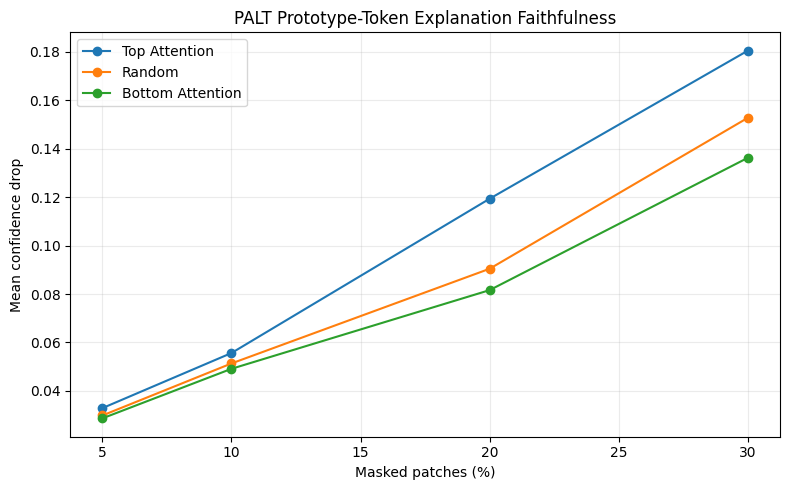

Saved: /kaggle/working/PALT_NV/figures/qc3_3_controlled_deletion_curves.png


In [98]:
# ================================================================
# QC-3.3 — Controlled deletion curves
# ================================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for condition in ["top_attention", "random", "bottom_attention"]:
    sub = faith_summary[
        faith_summary["condition"] == condition
    ].sort_values("mask_fraction")

    plt.plot(
        sub["mask_fraction"] * 100,
        sub["mean_confidence_drop"],
        marker="o",
        label=condition.replace("_", " ").title(),
    )

plt.xlabel("Masked patches (%)")
plt.ylabel("Mean confidence drop")
plt.title("PALT Prototype-Token Explanation Faithfulness")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plot_path = FIG_DIR / "qc3_3_controlled_deletion_curves.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)

In [99]:
# ================================================================
# FINAL EURO-SAT QC DECISION — v2
# ================================================================
# This cell does not modify weights or retrain the model.

qc1_full = qc1_results[0]
qc1_by_name = {r["condition"]: r for r in qc1_results}

pc_lgst = qc1_by_name["PC-LGST-bypassed"]
pld = qc1_by_name["PLD-bypassed"]

pc_lgst_acc_drop_pp = 100.0 * (
    qc1_full["accuracy"] - pc_lgst["accuracy"]
)
pc_lgst_f1_drop_pp = 100.0 * (
    qc1_full["macro_f1"] - pc_lgst["macro_f1"]
)

pld_acc_drop_pp = 100.0 * (
    qc1_full["accuracy"] - pld["accuracy"]
)
pld_f1_drop_pp = 100.0 * (
    qc1_full["macro_f1"] - pld["macro_f1"]
)

architecture_ok = (
    int(FROZEN_PALT_SPEC["actual_alte_block_count"]) == 1
    and int(FROZEN_PALT_SPEC["actual_alsbl_latent_bases"]) == 16
    and int(FROZEN_PALT_SPEC["num_channels"]) == 13
    and int(FROZEN_PALT_SPEC["num_classes"]) == 10
)

training_ok = (
    int(FROZEN_PALT_SPEC["epochs"]) == 10
    and abs(float(FROZEN_PALT_SPEC["learning_rate"]) - 1e-4) < 1e-12
    and int(FROZEN_PALT_SPEC["batch_size"]) == 16
    and int(FROZEN_PALT_SPEC["seed"]) == 42
)

# Functional liquid criterion:
# PC-LGST must produce a measurable same-checkpoint prediction effect.
liquid_mechanism_ok = (
    pc_lgst_acc_drop_pp > 0.1
    or pc_lgst_f1_drop_pp > 0.1
)

faithfulness_status = faith_decision["interpretation"]

# We do not require PLD to pass independently. The QC documents its
# low sensitivity instead of forcing a positive novelty claim.
final_status = (
    "EUROSAT_PALT_FROZEN_V1"
    if architecture_ok
    and training_ok
    and liquid_mechanism_ok
    and top_beats_controls
    else "EUROSAT_PALT_QC_COMPLETE_WITH_LIMITATIONS"
)

final_qc_manifest = {
    "status": final_status,
    "architecture_consistent": architecture_ok,
    "training_configuration_consistent": training_ok,
    "pc_lgst_functional_contribution_confirmed": bool(
        liquid_mechanism_ok
    ),
    "pc_lgst_accuracy_drop_pp": float(pc_lgst_acc_drop_pp),
    "pc_lgst_macro_f1_drop_pp": float(pc_lgst_f1_drop_pp),
    "pld_accuracy_drop_pp": float(pld_acc_drop_pp),
    "pld_macro_f1_drop_pp": float(pld_f1_drop_pp),
    "pld_interpretation": (
        "Low functional sensitivity under the trained EuroSAT checkpoint; "
        "do not claim independent performance contribution."
    ),
    "prototype_redundancy_interpretation": (
        "Prototype redundancy remains a limitation; broad utilization "
        "does not imply fully independent semantic prototypes."
    ),
    "faithfulness_interpretation": faithfulness_status,
    "controlled_faithfulness_top_auc": float(top_auc),
    "controlled_faithfulness_random_auc": float(random_auc),
    "controlled_faithfulness_bottom_auc": float(bottom_auc),
    "weights_modified_during_qc": False,
    "retraining_during_qc": False,
    "recommended_paper_claim": (
        "Counterfactual analysis demonstrates functional dependence on "
        "the prototype-conditioned liquid token transition (PC-LGST). "
        "The separate PLD pathway shows low sensitivity in the trained "
        "EuroSAT model and should not be presented as independently "
        "performance-critical."
    ),
}

final_manifest_path = RUN_DIR / "PALT_EuroSAT_QC_Final_v2_Manifest.json"

with open(final_manifest_path, "w") as f:
    json.dump(final_qc_manifest, f, indent=2)

print("=" * 110)
print("PALT EURO-SAT FINAL QC v2")
print("=" * 110)
print(
    "Architecture/configuration consistency :",
    "PASS" if architecture_ok else "FAIL"
)
print(
    "Training configuration consistency    :",
    "PASS" if training_ok else "FAIL"
)
print(
    "PC-LGST functional contribution       :",
    "PASS" if liquid_mechanism_ok else "NOT ESTABLISHED"
)
print(
    "PLD independent sensitivity           :",
    f"{pld_acc_drop_pp:.4f} pp accuracy; "
    f"{pld_f1_drop_pp:.4f} pp macro-F1"
)
print("Controlled faithfulness               :", faithfulness_status)
print("Top deletion AUC                      :", f"{top_auc:.8f}")
print("Random deletion AUC                   :", f"{random_auc:.8f}")
print("Bottom deletion AUC                   :", f"{bottom_auc:.8f}")
print("Weights modified during QC            : NO")
print("Retraining during QC                  : NO")
print("FINAL STATUS                          :", final_status)
print("Manifest                              :", final_manifest_path)

assert architecture_ok, "Architecture/configuration consistency failed."
assert training_ok, "Training configuration consistency failed."
assert liquid_mechanism_ok, "PC-LGST contribution was not established."
assert top_beats_controls, (
    "Controlled faithfulness did not show top-attention deletion stronger "
    "than both controls; do not freeze yet."
)

print()
print(
    "FINAL QC PASSED — EuroSAT PALT is eligible to be frozen "
    "for cross-dataset evaluation."
)

PALT EURO-SAT FINAL QC v2
Architecture/configuration consistency : PASS
Training configuration consistency    : PASS
PC-LGST functional contribution       : PASS
PLD independent sensitivity           : -0.0370 pp accuracy; -0.0373 pp macro-F1
Controlled faithfulness               : PASS — controlled faithfulness supports prediction-relevant attention when top > random > bottom.
Top deletion AUC                      : 0.02595882
Random deletion AUC                   : 0.02128089
Bottom deletion AUC                   : 0.01937710
Weights modified during QC            : NO
Retraining during QC                  : NO
FINAL STATUS                          : EUROSAT_PALT_FROZEN_V1
Manifest                              : /kaggle/working/PALT_NV/PALT_EuroSAT_QC_Final_v2_Manifest.json

FINAL QC PASSED — EuroSAT PALT is eligible to be frozen for cross-dataset evaluation.


## Final EuroSAT interpretation

If the final decision cell passes:

- **PC-LGST:** functionally supported by same-checkpoint counterfactual analysis.
- **PLD:** retained as an architectural pathway, but low sensitivity means no independent performance contribution should be claimed.
- **Prototype memory:** broad utilization is retained as evidence of activity, while redundancy is acknowledged as a limitation.
- **Explainability:** the controlled deletion experiment provides the evidence used for the faithfulness claim.
- **Architecture:** one actual ALTE path and 16 A-LSBL latent bases.
- **Frozen use:** the validated EuroSAT PALT core can be carried to BigEarthNet-S2 and So2Sat LCZ42, with only task/output-head adaptations where required.